<a href="https://colab.research.google.com/github/SNIGDHA-ms24043/IDC-PROJECT--Music-Genre-Classification/blob/main/Music_Genre_IDC_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("let's goooo")
print("music genre classification ")
print("features ")

let's goooo
music genre classification 
features 


In [ ]:
# Snigdha
'''
Roadmap
1) create table => Use audio features such as MFCC,chroma, spectral centroid, tempo and energy.=> done already
2) Start with extracted-feature CSV if audio processing is too hard.
Advanced one can use Librosa to extract features from .wav files. => Librosa is a Python library specifically designed for analyzing audio and music.
.wav is an audio file format.
3)EDA: compare tempo, spectral features and MFCC patterns across genres=> done
4)Classification: KNN, SVM, RandomForest, Logistic Regression.Feature scaling is important for KNN/SVM.Optional deep learning: CNN on spectrogram images.
5)Model comparison and confusion matrix.
Short audio/AI reflection: which genres are confused and why?
6)Metrics: accuracy, macro F1, confusion matrix.
Check class balance across genres.
Extension: build a simple song-similarity recommender using
cosine similarity.

In [ ]:
# Snigdha
'''importing files and show number of columns and rows
'''
import pandas as pd
df=pd.read_excel("/content/features_3_sec.csv.xlsx")
#f-string (formatted string).=>It allows you to put Python variables/calculations directly inside a piece of text using {}
print(f"Loaded rows={df.shape[0]}, columns={df.shape[1]}")

Loaded rows=998, columns=60


In [ ]:
# Snigdha
'''
Data description
1) filename= the genre of a music
2) length = duration of the song (seconds)
3) chroma_stft=Average chroma feature calculated using STFT *
4) rms=Root Mean Square energy *
5) spectral_centroid=Center of the frequency spectrum ["center of mass" of the frequencies]
6) spectral_bandwidth=Spread of frequencies around the spectral centroid
7) rolloff=Frequency below which a chosen percentage of total spectral energy lies
8) zero_crossing_rate=Rate at which the waveform crosses zero
9) harmony=Harmonic component of the audio
10)perceptr=Perceptual/tonal audio feature in this dataset *
11)tempo=Estimated tempo=> estimated speed of the music, generally expressed in BPM: beats per minute.
12)mfcc [1-20]=20 Mel-Frequency Cepstral Coefficients=> they provide information about the spectral shape/timbre of sound, using a frequency representation related to human auditory perception.
[compact numerical description of characteristics of the sound's spectrum]
13)label=Genre/class assigned to the song

Notes

3)Chroma looks at the distribution of musical pitch classes.
STFT = Short-Time Fourier Transform.
It allows us to examine the frequency content of the music over short periods of time.
chroma_stft tells us about the distribution of musical pitch/harmonic content over time.

4) as a measure related to the energy/intensity of the audio signal.

10)The name perceptr isn't one of the standard Librosa feature names in the same straightforward way as tempo, rms, spectral_centroid, or mfcc.
It may represent a perceptual/tonal feature calculated by the dataset's feature-extraction pipeline.

In [ ]:
#gurleen
# EDA Notebook with genre comparison plots(minimum deliverables)

# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")

print("\nSong / Slice counts per genre:")
print(df["label"].value_counts())


Combined DataFrame shape: (5993, 60)

Song / Slice counts per genre:
label
pop          1000
jazz         1000
disco         999
classical     998
rock          998
hiphop        998
Name: count, dtype: int64


In [ ]:
#gurleen
#data quality check
display(df.describe())
#Compute summary statistics (count, mean, std, min, max, quartiles) for numeric columns
print("dtypes")
display(df.dtypes)
#Inspect data types (e.g., float64, int64, object/string) across all columns
print("isna")
display(df.isna().sum())
#Check for number of missing or null (NaN) values column-by-column and sum them.

,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
count,5993.0,5993.000000,5993.000000,5993.000000,5.993000e+03,5993.000000,5.993000e+03,5993.000000,5.993000e+03,5993.000000,...,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000
mean,66149.0,0.369765,0.085313,0.128493,3.138759e-03,2265.230236,4.501238e+05,2305.666850,1.157067e+05,4729.658658,...,1.147663,51.496599,-2.745784,53.746498,0.696740,55.751498,-1.806700,59.343750,-0.640064,62.662091
std,0.0,0.092304,0.008304,0.074561,4.253689e-03,800.434954,4.692345e+05,612.913004,1.023451e+05,1809.642137,...,5.593858,38.789302,5.686764,39.518274,5.231412,41.809001,5.266784,47.382750,5.293887,52.241778
min,66149.0,0.107108,0.038064,0.000953,4.379535e-08,472.741636,8.118813e+02,499.162910,1.653263e+03,658.336276,...,-26.850016,3.070262,-27.809795,1.624544,-20.733809,3.437439,-27.448456,3.065302,-35.640659,1.429122
25%,66149.0,0.299573,0.080289,0.069345,5.016397e-04,1643.004276,1.150352e+05,1863.473852,4.868666e+04,3330.772423,...,-2.448044,29.183075,-6.429787,29.949141,-2.635681,30.325510,-5.174462,31.134136,-3.789416,31.285770
50%,66149.0,0.381032,0.084971,0.121310,1.574680e-03,2282.579370,2.931697e+05,2311.503052,8.873703e+04,4803.974797,...,0.909661,41.604786,-2.846961,43.233727,0.431402,43.638138,-2.048507,45.675880,-0.895388,47.818382
75%,66149.0,0.439004,0.090665,0.182003,3.873321e-03,2829.708631,6.233330e+05,2760.571284,1.516846e+05,5992.276330,...,4.396758,60.209942,0.577235,63.435772,3.622621,67.347115,1.164105,71.660454,2.271236,75.617569
max,66149.0,0.738563,0.114378,0.442567,3.261522e-02,4952.034726,4.794119e+06,3708.147554,1.235143e+06,9487.446477,...,39.144405,683.932556,34.048843,529.363342,36.970322,629.729797,31.365425,1143.230591,34.212101,910.473206


dtypes


,0
filename,object
length,int64
chroma_stft_mean,float64
chroma_stft_var,float64
rms_mean,float64
rms_var,float64
spectral_centroid_mean,float64
spectral_centroid_var,float64
spectral_bandwidth_mean,float64
spectral_bandwidth_var,float64


isna


,0
filename,0
length,0
chroma_stft_mean,0
chroma_stft_var,0
rms_mean,0
rms_var,0
spectral_centroid_mean,0
spectral_centroid_var,0
spectral_bandwidth_mean,0
spectral_bandwidth_var,0


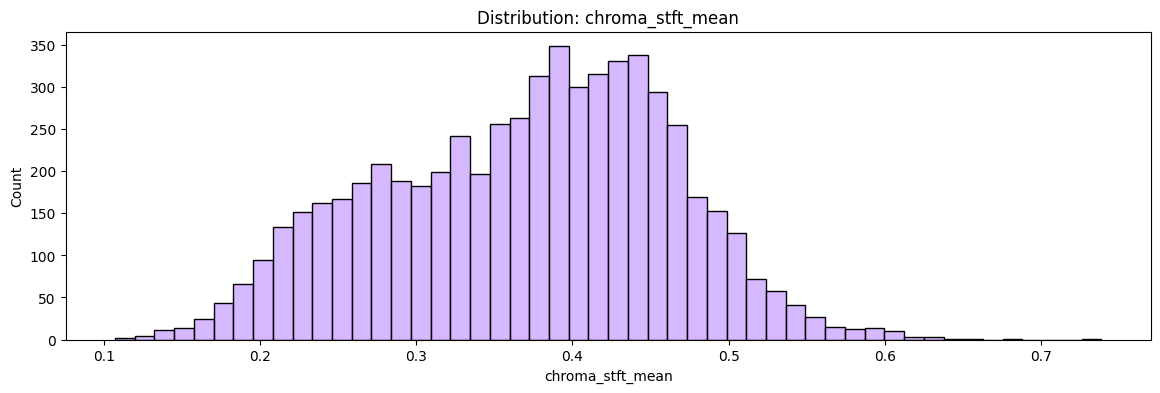

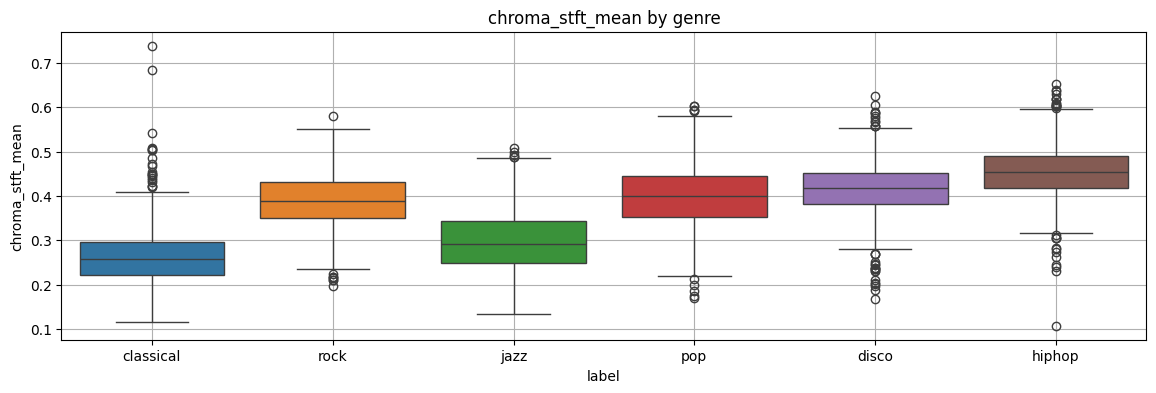

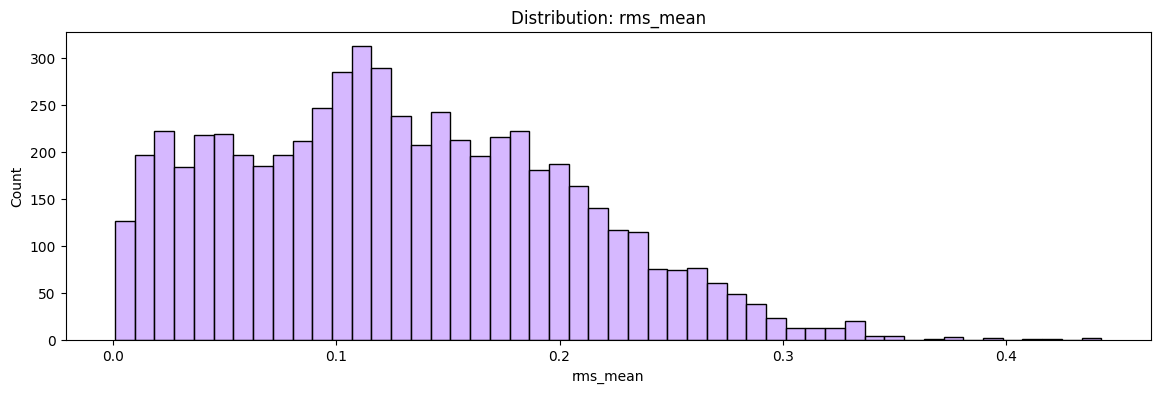

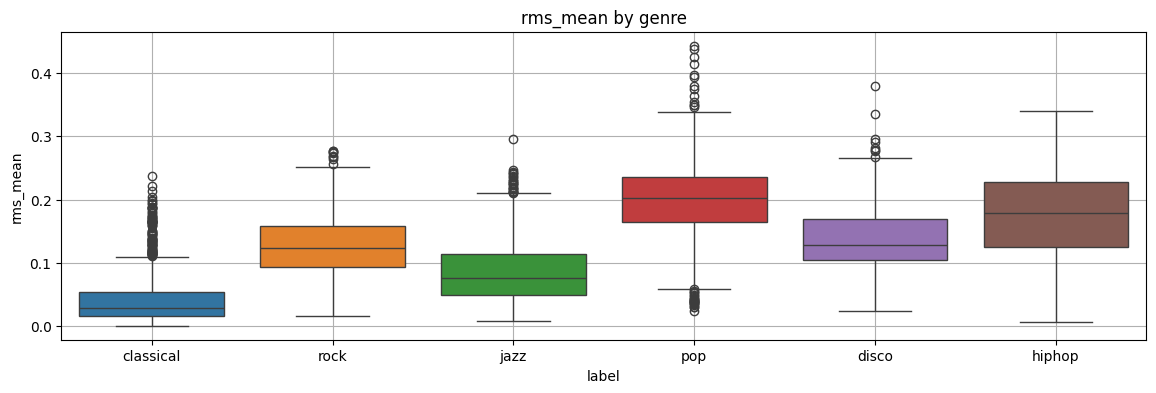

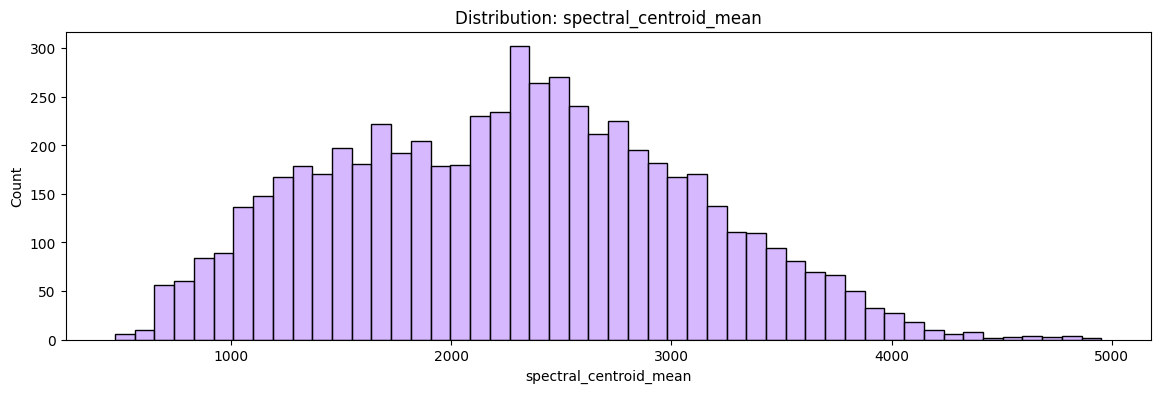

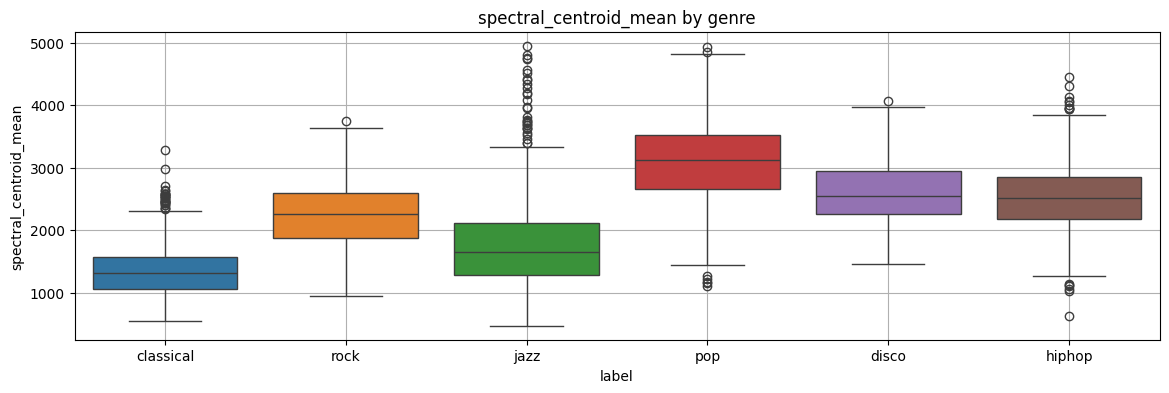

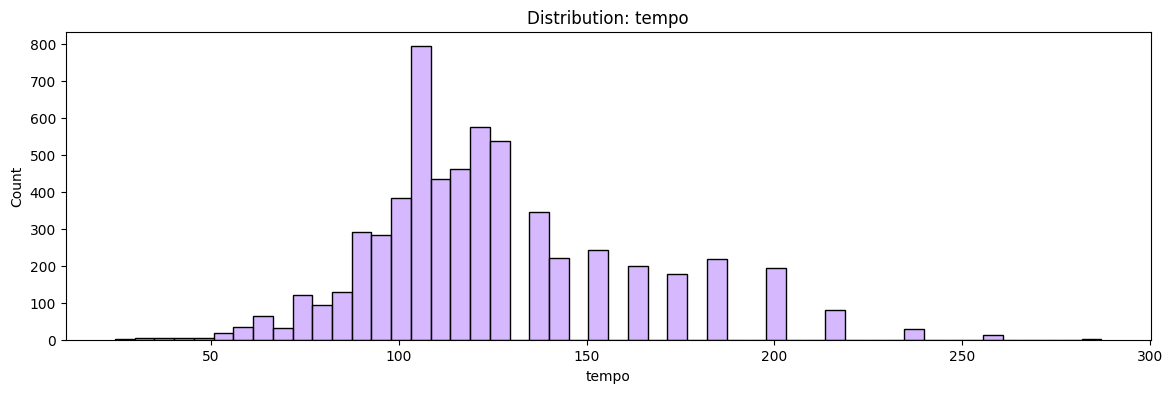

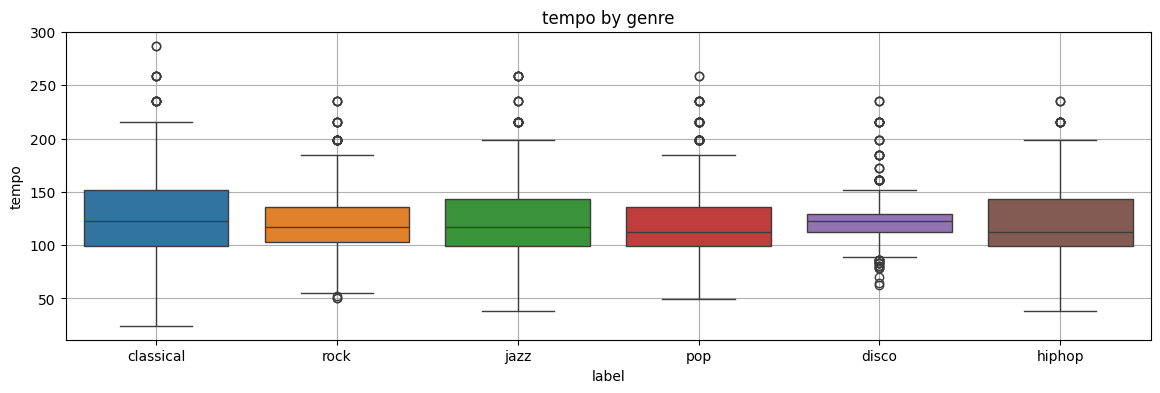

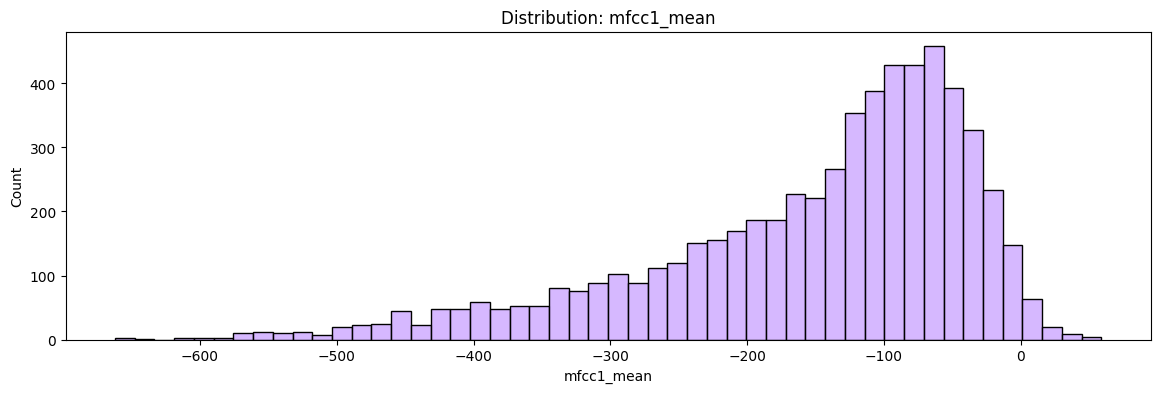

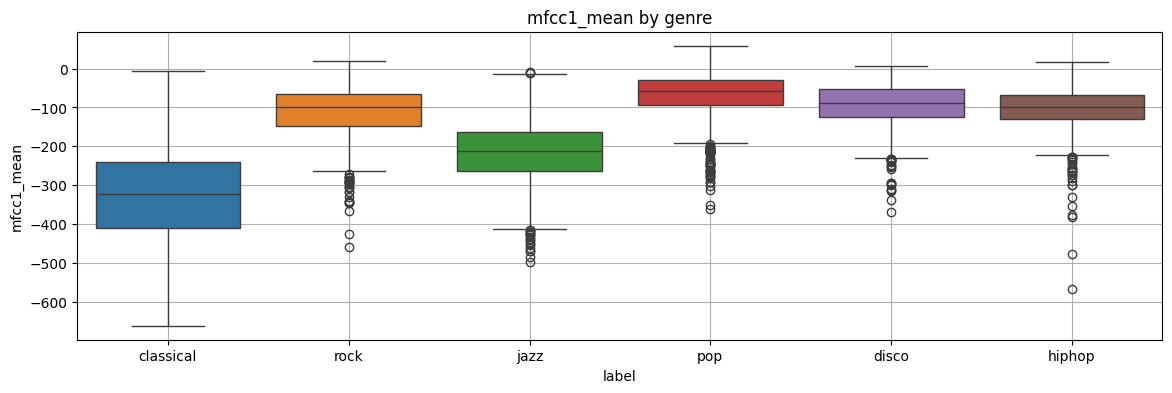

In [ ]:
#gurleen
#distribution analysis using histogram and box plot
import matplotlib.pyplot as plt # Handles the figure dimensions (figsize), titles, axis labels, and rendering (plt.show()).
import pandas as pd # Manages tabular datasets (DataFrames), supporting data loading, missing value checks, and feature selections.
import seaborn as sns #Produces high-level statistical plots (such as histograms, box plots, count plots, and heatmaps) with built-in color palettes.

numeric_cols = ["chroma_stft_mean","rms_mean","spectral_centroid_mean","tempo","mfcc1_mean"]
#Define key numerical audio metrics to inspect for skewness, spread, and genre separability.
#Loop through each audio feature to generate distribution and genre-comparison plots
for col in numeric_cols:
    plt.figure(figsize=(14, 4))
    sns.histplot(data=df, x=col, bins=50, color="#C9A0FF")#Plot overall feature distribution (histogram)
    plt.title(f"Distribution: {col}")
    plt.show()
    plt.figure(figsize=(14, 4))
    sns.boxplot(data=df, y=col, x="label", hue="label")#Plot feature breakdown across music genres (box plot)
    plt.title(f"{col} by genre")
    plt.grid()
    plt.show()


'Sub-sampling: A pairplot creates an NxN grid of scatter plots.Taking a random sample of 500 rows makes the plot render almost instantly while still showing clear distribution trends.\n   Random_state=42: Ensures reproducibility—you get the exact same random sample of songs every time you run the code.'

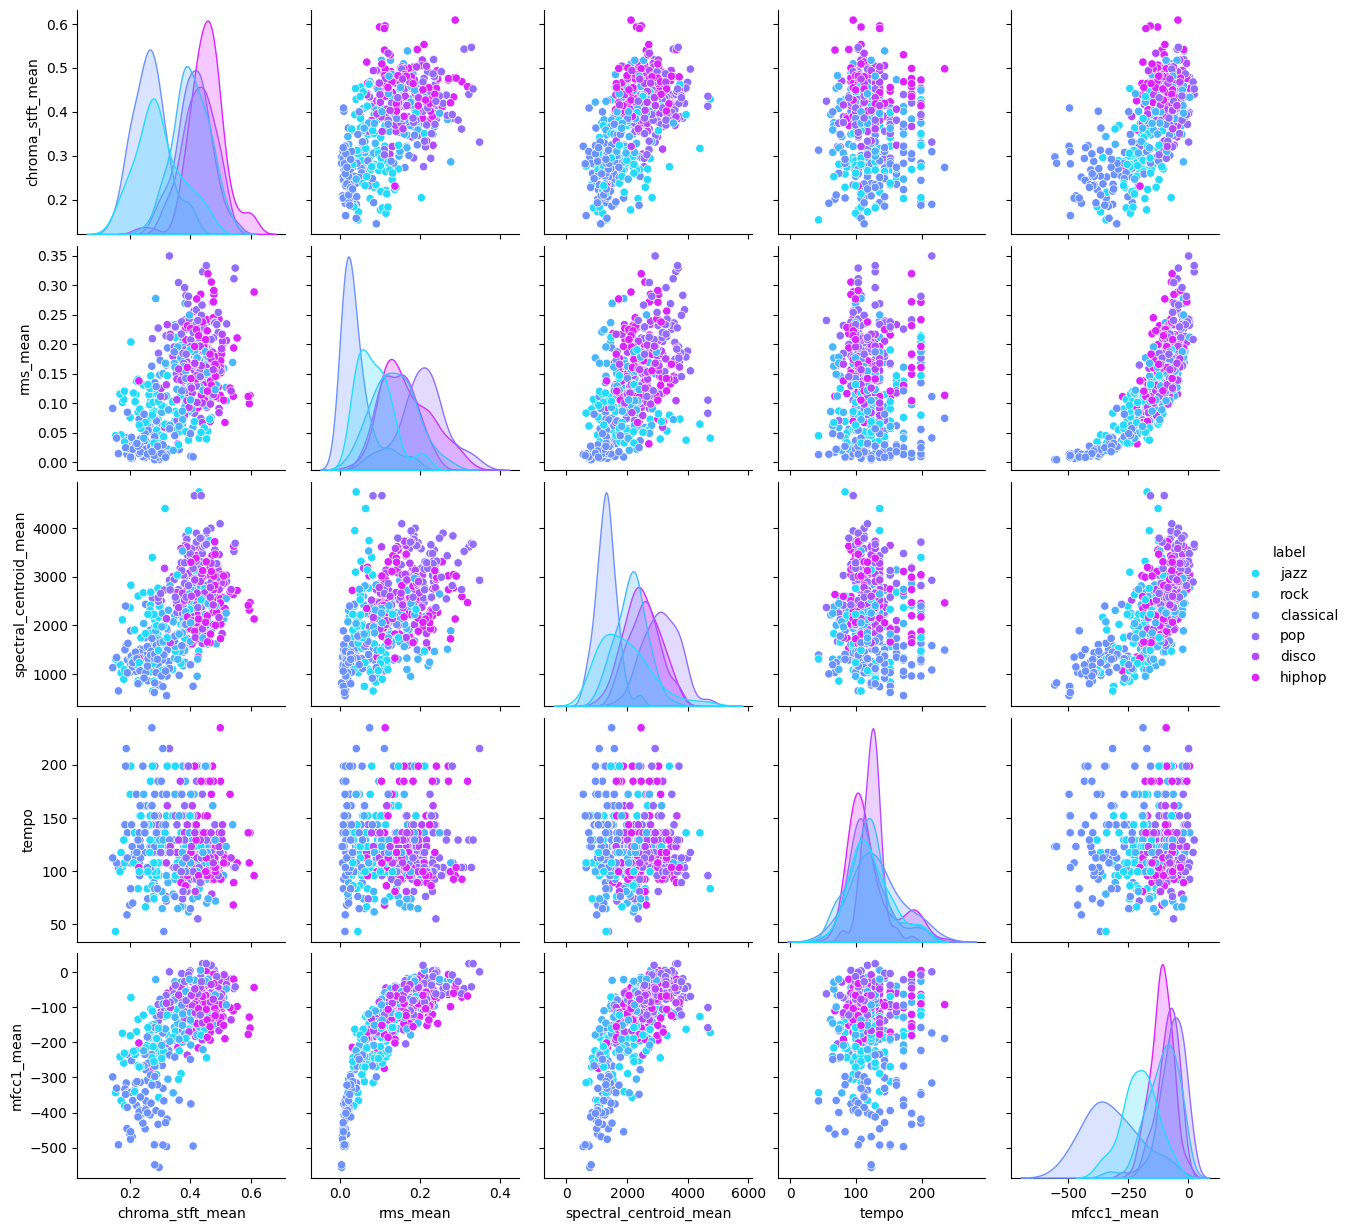

In [ ]:
#gurleen
#pairwise relationships
pair_cols = ["chroma_stft_mean","rms_mean","spectral_centroid_mean","tempo","mfcc1_mean","label"]
sns.pairplot(df[pair_cols].sample(min(500, len(df)), random_state=42), hue="label", palette="cool")
'''Sub-sampling: A pairplot creates an NxN grid of scatter plots.Taking a random sample of 500 rows makes the plot render almost instantly while still showing clear distribution trends.
   Random_state=42: Ensures reproducibility—you get the exact same random sample of songs every time you run the code.'''

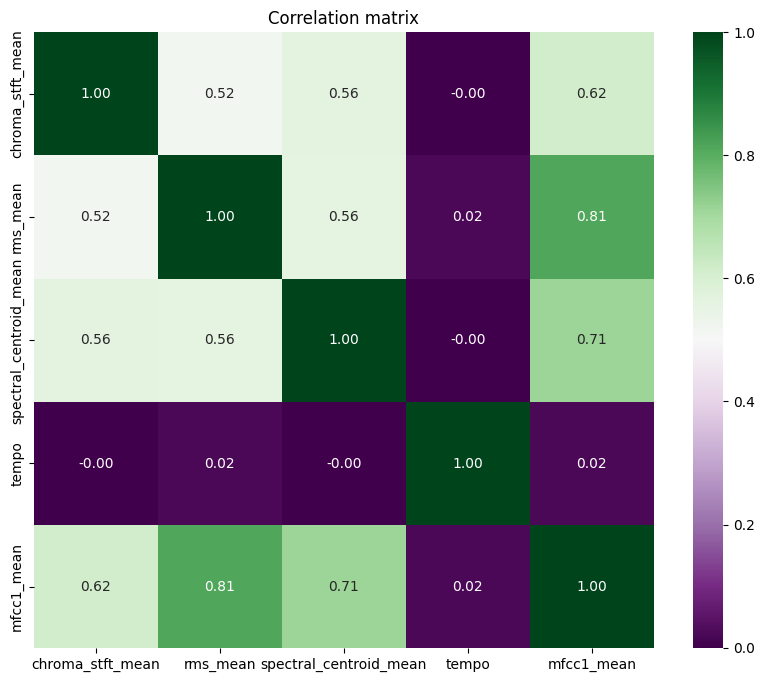

In [ ]:
#gurleen
corr_cols = ["chroma_stft_mean","rms_mean","spectral_centroid_mean","tempo","mfcc1_mean","label"]
corr_matrix = df[corr_cols].corr(numeric_only=True)
#Compute pairwise Pearson correlation coefficients (-1.0 to +1.0) for numerical columns for every pair of feature.
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='PRGn') # Display exact correlation values inside each cell and Format values to 2 decimal places.
plt.title("Correlation matrix")
plt.show()



In [ ]:
#Snigdha
#using Librosa to extract features from .wav files.
#First, install Librosa alongside soundfile (for loading audio formats) and matplotlib (for optional visualization)

'''
When you load an audio file using librosa.load, it automatically resamples the audio to a default sampling rate of 22,050 Hz and normalizes the amplitude.
It returns a 1D NumPy array representing the audio time-series signal (y) and the sample rate (sr)
'''
import librosa
import numpy as np

# Load audio file (supports WAV, MP3, FLAC, etc.)
audio_path = "/content/classical.00000.wav"
y, sr = librosa.load(audio_path, sr=None)  # sr=None preserves native sample rate
# Extract 13 MFCCs (commonly 13 to 40 are used)
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
print("MFCCs shape:", mfccs.shape)  # Shape: (n_mfcc, number_of_frames)
chromagram = librosa.feature.chroma_stft(y=y, sr=sr)
print("Chroma shape:", chromagram.shape)  # Shape: (12, number_of_frames)
rms = librosa.feature.rms(y=y)
print("RMS shape:", rms.shape)  # Shape: (1, number_of_frames)
spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)
'''
Because audio files have different lengths, the extracted feature matrices will have varying numbers of time frames.
 To pass these into standard tabular machine learning models (like Random Forests, SVMs, or XGBoost), you should compress the
 time axis by calculating the mean and standard deviation across all frames
'''
# Function to aggregate features into a single row vector
def extract_global_features(y, sr):
    features = {}

    # Calculate raw features
    mfcc_feat = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    chroma_feat = librosa.feature.chroma_stft(y=y, sr=sr)
    rms_feat = librosa.feature.rms(y=y)

    # Aggregate over time windows using Mean and Std Dev
    features['mfcc_mean'] = np.mean(mfcc_feat, axis=1)
    features['mfcc_std'] = np.std(mfcc_feat, axis=1)

    features['chroma_mean'] = np.mean(chroma_feat, axis=1)
    features['rms_mean'] = np.mean(rms_feat)

    # Flatten everything into a single 1D array
    feature_vector = np.concatenate([
        features['mfcc_mean'],
        features['mfcc_std'],
        features['chroma_mean'],
        [features['rms_mean']]
    ])

    return feature_vector

# Extract a static feature row for one file
ML_ready_features = extract_global_features(y, sr)
print("Final feature vector size:", ML_ready_features.shape)

# 1. Load audio and extract spectral features
y, sr = librosa.load('/content/classical.00000.wav', sr=None)

spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)
# 2. Calculate the mean across time frames (axis=1)
# This squeezes the 2D array into a single average scalar value
mean_centroid = np.mean(spectral_centroids, axis=1)[0]


print(f"Mean Spectral Centroid: {mean_centroid:.2f} Hz")

MFCCs shape: (13, 1293)
Chroma shape: (12, 1293)
RMS shape: (1, 1293)
Final feature vector size: (39,)
Mean Spectral Centroid: 1505.36 Hz


In [ ]:
#Snigdha
#Extracting all imp audio features
import librosa
import numpy as np

# 1. Load the audio file
y, sr = librosa.load('/content/classical.00000.wav', sr=None)

# 2. Extract Features
spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)
# 2. Calculate the mean across time frames (axis=1)
# This squeezes the 2D array into a single average scalar value
mean_centroid = np.mean(spectral_centroids, axis=1)[0]


print(f"Mean Spectral Centroid: {mean_centroid:.2f} Hz")

# Tempo (returns a scalar or a 1D array depending on your librosa version)
tempo, _ = librosa.beat.beat_track(y=y, sr=sr)

# MFCCs (returns 2D array: [n_mfcc, time_frames])
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

# Chroma (returns 2D array: [12_pitch_classes, time_frames])
chroma = librosa.feature.chroma_stft(y=y, sr=sr)

# Spectral Centroid (returns 2D array: [1, time_frames])
spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)

# Energy / RMS (returns 2D array: [1, time_frames])
energy = librosa.feature.rms(y=y)

# 3. Calculate Means (Averaging over time)

# Tempo is already an overall average metric, no axis needed
mean_tempo = tempo[0] if isinstance(tempo, np.ndarray) else tempo

# 2D features require axis=1 to average across the time columns
mean_mfccs = np.mean(mfccs, axis=1)              # Returns 13 values (one per coefficient)
mean_chroma = np.mean(chroma, axis=1)            # Returns 12 values (one per pitch)
mean_centroid = np.mean(spectral_centroids, axis=1)[0] # Returns a single scalar
mean_energy = np.mean(energy, axis=1)[0]         # Returns a single scalar


# 4. Print Results

print(f"Tempo: {mean_tempo:.2f} BPM")
print(f"Mean Centroid: {mean_centroid:.2f} Hz")
print(f"Mean Energy (RMS): {mean_energy:.4f}")
print(f"Mean MFCCs (first 3): {mean_mfccs[:3]}")
print(f"Mean Chroma (first 3): {mean_chroma[:3]}")


Mean Spectral Centroid: 1505.36 Hz
Tempo: 95.70 BPM
Mean Centroid: 1505.36 Hz
Mean Energy (RMS): 0.0362
Mean MFCCs (first 3): [-268.21857   135.68166   -34.056377]
Mean Chroma (first 3): [0.1244859  0.29797456 0.4111422 ]


In [ ]:
#gurleen
import matplotlib.pyplot as plt# Figure creation, layout customization, and axis formatting.
import numpy as np# Multi-dimensional array handling and mathematical operations.
import pandas as pd# Data manipulation, cleaning, and DataFrame management.
import seaborn as sns# Advanced statistical plots (heatmaps, box plots, count plots).
from sklearn.ensemble import RandomForestClassifier# Ensemble tree-based classifier
from sklearn.linear_model import LogisticRegression# Linear model for multi-class classification


from sklearn.metrics import accuracy_score, classification_report, f1_score
# Calculates overall percentage of correct predictions.
#Generates Precision, Recall, F1-Score, and Support per class
# Measures harmonic mean of Precision and Recall
from sklearn.model_selection import train_test_split# Partitions data into training and testing subsets
from sklearn.neighbors import KNeighborsClassifier# Distance-based non-parametric classifier
from sklearn.preprocessing import LabelEncoder, StandardScaler# Converts categorical text labels into integer indices and Standardizes numerical features (zero mean, unit variance).
from sklearn.svm import SVC# Support Vector Classifier for complex decision boundaries
from sklearn.metrics import confusion_matrix# Builds actual vs. predicted classification error grid

In [ ]:
#gurleen + Snigdha (comments)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
df=pd.read_excel("/content/features_3_sec.csv.xlsx")
# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")
target_col = 'label'
ignore_cols = [target_col, 'filename', 'length']
#target_col is a variable that stores the name of the column to be predicted.
#label is the column containing the correct music genre for each song.

#filename is excluded because the song's filename is generally not a meaningful audio feature.
#length is excluded because it is not prediciting the genre here

# Automatically select ALL numerical feature columns
feature_cols = [c for c in df.columns if c not in ignore_cols]
#where c is a temporary variable representing one column name. This code goes through every column not in the exclusion list

X = df[feature_cols]
y = df[target_col]
#df[feature_cols] selects the feature columns and stores them in X.
#df[target_col] selects the label column and stores it in y.


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
'''
X_train	Features for training songs
X_test	Features for test songs
y_train	Correct genres for training songs
y_test	Correct genres for test songs
'''
#X: all the input features.
#y: all the correct genre labels.
#test_size=0.3: reserve 30% of the data for testing.
#stratify=y: preserve approximately the same proportion of each genre in the training and testing sets.
#random_state=42: make the random split reproducible, so you get the same split when rerunning the code on the same data.

scaler = StandardScaler()
#StandardScaler standardizes each feature using its mean and standard deviation

X_train_scaled = scaler.fit_transform(X_train)
#calculate the mean and standard deviation of each feature using the training set and standardize the training features using those statistics.
X_test_scaled = scaler.transform(X_test)
#Use the same training-set statistics to standardize the test features.
# fit transform was not used because the test data must remain independent of the preprocessing decisions learned from the training data.
#Using the training statistics helps avoid data leakage

models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=42
    ),
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42
    ),
}
'''
When a new song is presented, KNN looks for the five most similar songs in the training set and predicts the genre based on their labels, typically by majority vote.
SVM learns boundaries that separate genres in feature space. The RBF kernel lets it model nonlinear boundaries.class_weight='balanced' adjusts the importance of classes
according to their frequencies in the training data.
Random Forest builds 200 decision trees and combines their predictions to classify songs.It can learn complex relationships between features. class_weight='balanced'
helps account for unequal numbers of songs per genre.
Logistic Regression can perform classification. It estimates class probabilities from the input features and predicts a genre.
'''
'''
random_state=42 makes the randomized aspects of supported algorithms reproducible.
class_weight='balanced' is helpful when some genres have far fewer examples than others.
These are model settings, also called hyperparameters.
'''

results = {}

print("   MODEL EVALUATION   ")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    #This tells the model to learn patterns from the training data.It receives: X_train_scaled: the scaled audio features.
    #y_train: the correct genres associated with those features. The model learns how the numerical characteristics relate to the different music genres.
    y_pred = model.predict(X_test_scaled)
    #the trained model predicts the genre of every song in the test set.

    acc = accuracy_score(y_test, y_pred)
    #Accuracy is the fraction of predictions that are correct
    results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")



Combined DataFrame shape: (5993, 60)
   MODEL EVALUATION   
KNN Accuracy: 0.9055
SVM Accuracy: 0.9038
Random Forest Accuracy: 0.9271
Logistic Regression Accuracy: 0.8148


In [ ]:
#Snigdha
#only checking accuracy

target_col = 'label'
ignore_cols = [target_col, 'filename', 'length']

# Automatically select ALL numerical feature columns
feature_cols = [c for c in df.columns if c not in ignore_cols]

X = df[feature_cols]
y = df[target_col]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=42
    ),
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42
    ),
}


results = {}

print("   MODEL EVALUATION   ")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")


   MODEL EVALUATION   
KNN Accuracy: 0.9055
SVM Accuracy: 0.9038
Random Forest Accuracy: 0.9271
Logistic Regression Accuracy: 0.8148


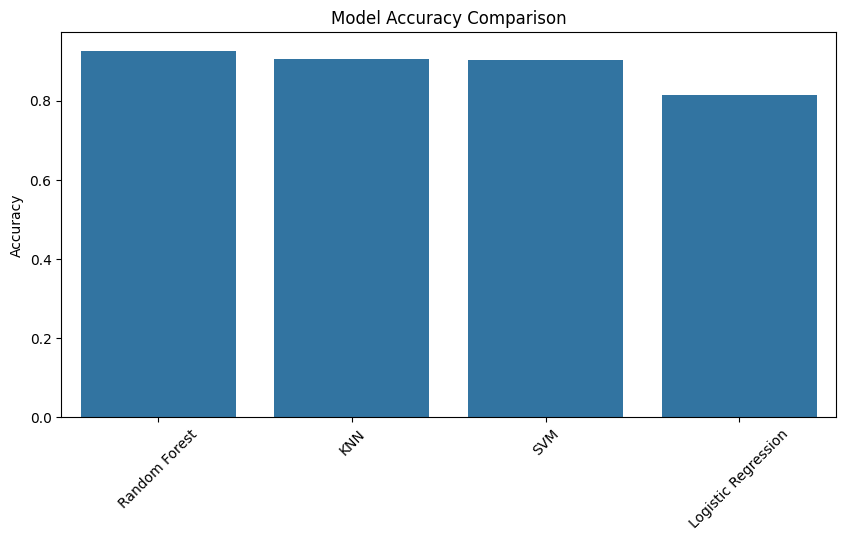

In [ ]:
# gurleen
#Model Accuracy Comparision Bar Chart
sorted_results = dict(sorted(results.items(), key=lambda item: item[1], reverse=True))
#takes your results dictionary (e.g {'Random Forest': 0.9271, 'KNN': 0.9055, ...}) and sorts it by score (item) in descending order (reverse=True) so the winning model appears on the far left.
plt.figure(figsize=(10,5))
sns.barplot(x=list(sorted_results.keys()), y=list(sorted_results.values()))
#Places model names on the horizontal x-axis and Plots the corresponding performance scores on the vertical y-axis.
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.show()

Combined DataFrame shape: (5993, 60)
   MODEL EVALUATION   

KNN:
  Macro F1: 0.9057

SVM:
  Macro F1: 0.9036

Random Forest:
  Macro F1: 0.9270

Logistic Regression:
  Macro F1: 0.8141


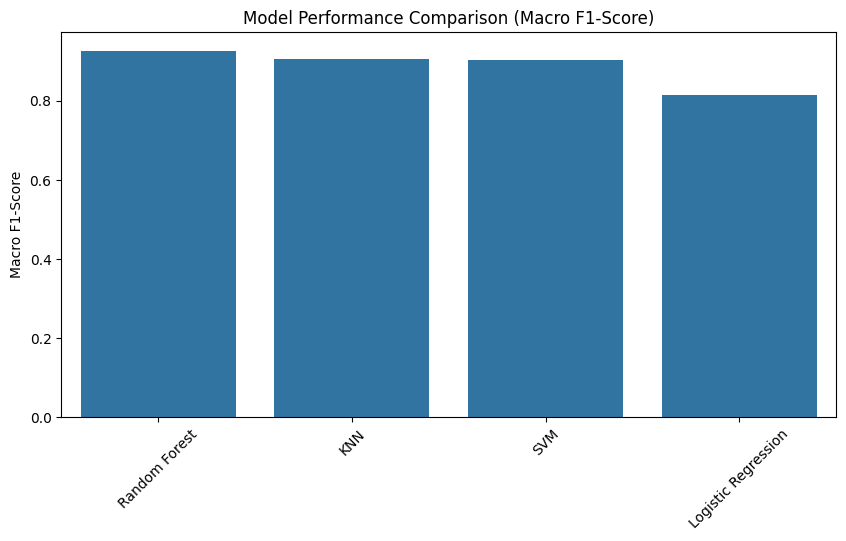

In [ ]:
#gurleen
#Macro F1 Score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix


df=pd.read_excel("/content/features_3_sec.csv.xlsx")
# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")


target_col = 'label'
ignore_cols = [target_col, 'filename', 'length']

# Automatically select ALL numerical feature columns
feature_cols = [c for c in df.columns if c not in ignore_cols]

X = df[feature_cols]
y = df[target_col]
#df[feature_cols] selects the feature columns and stores them in X.
#df[target_col] selects the label column and stores it in y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
'''
X_train	Features for training songs
X_test	Features for test songs
y_train	Correct genres for training songs
y_test	Correct genres for test songs
'''
#X: all the input features.
#y: all the correct genre labels.
#test_size=0.3: reserve 30% of the data for testing.
#stratify=y: preserve approximately the same proportion of each genre in the training and testing sets.
#random_state=42: make the random split reproducible, so you get the same split when rerunning the code on the same data.
#StandardScaler standardizes each feature using its mean and standard deviation
#Use the same training-set statistics to standardize the test features.
# fit transform was not used because the test data must remain independent of the preprocessing decisions learned from the training data.
#Using the training statistics helps avoid data leakage

models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=42
    ),
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42
    ),
}


results = {}

print("   MODEL EVALUATION   ")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    #Computes the unweighted harmonic mean across all genre classes, ensuring minority genres are weighted equally alongside common genres.
    results[name] = macro_f1
    print(f"\n{name}:")
    print(f"  Macro F1: {macro_f1:.4f}")

sorted_results = dict(sorted(results.items(), key=lambda item: item[1], reverse=True))
#Sorts the models in descending order by Macro F1 score so the winning algorithm (Random Forest) appears on the far left
plt.figure(figsize=(10,5))
sns.barplot(x=list(sorted_results.keys()), y=list(sorted_results.values()))
plt.title("Model Performance Comparison (Macro F1-Score)")
plt.ylabel("Macro F1-Score")
plt.xticks(rotation=45)
plt.show()


Combined DataFrame shape: (5993, 60)
RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

   classical       0.95      0.97      0.96       300
       disco       0.90      0.89      0.89       300
      hiphop       0.95      0.92      0.93       299
        jazz       0.91      0.96      0.94       300
         pop       0.94      0.93      0.94       300
        rock       0.92      0.89      0.90       299

    accuracy                           0.93      1798
   macro avg       0.93      0.93      0.93      1798
weighted avg       0.93      0.93      0.93      1798



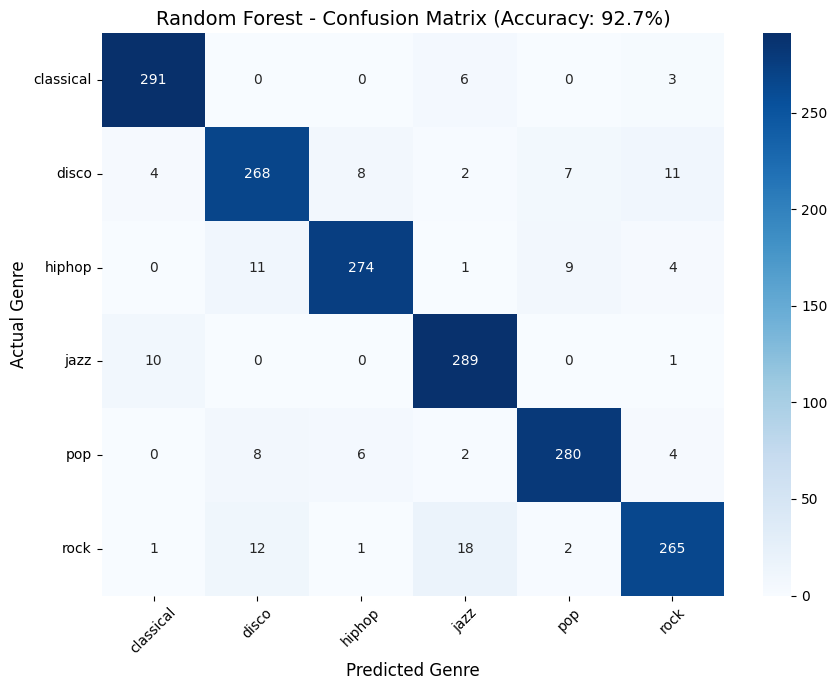

In [ ]:
#gurleen
# confusion matrix for random forest classification model
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix


df=pd.read_excel("/content/features_3_sec.csv.xlsx")
# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")


rf_model = models['Random Forest']
y_pred_rf = rf_model.predict(X_test_scaled)
#Feeds the scaled test audio features into your trained Random Forest model to generate genre predictions.

print("RANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_rf))
'''Prints a text table with metrics for every individual music genre:
Precision: How accurate the model's guesses were when it claimed a song belonged to a specific genre.
Recall: What percentage of the true tracks in a genre the model successfully detected.
F1-Score: The balanced score combining Precision and Recall.
Support: The exact number of test tracks evaluated for each genre.'''

cm = confusion_matrix(y_test, y_pred_rf)
'''Builds a 2D numerical array (a grid):
Rows represent the Actual Genres.
Columns represent the Predicted Genres.
Each cell contains the count of test tracks corresponding to that specific (Actual, Predicted) pair.'''
#this array contains only raw numbers. It has no column headers or row titles attached to it

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=rf_model.classes_,#Scikit-Learn automatically inspects all unique target labels in your dataset and stores them in alphabetical order inside rf_model.classes.
    #tick labels :Replaces numeric indices (0, 1, 2...) with text genre labels (e.g., classical, pop, rock).
    yticklabels=rf_model.classes_,
)
plt.title('Random Forest - Confusion Matrix (Accuracy: 92.7%)', fontsize=14)
plt.xlabel('Predicted Genre', fontsize=12)
plt.ylabel('Actual Genre', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Combined DataFrame shape: (5993, 60)

 KNN CLASSIFICATION REPORT 
              precision    recall  f1-score   support

   classical       0.91      0.95      0.93       300
       disco       0.82      0.92      0.87       300
      hiphop       0.92      0.92      0.92       299
        jazz       0.91      0.91      0.91       300
         pop       0.96      0.88      0.92       300
        rock       0.94      0.85      0.89       299

    accuracy                           0.91      1798
   macro avg       0.91      0.91      0.91      1798
weighted avg       0.91      0.91      0.91      1798


 SVM CLASSIFICATION REPORT 
              precision    recall  f1-score   support

   classical       0.92      0.97      0.94       300
       disco       0.86      0.85      0.85       300
      hiphop       0.95      0.90      0.92       299
        jazz       0.92      0.94      0.93       300
         pop       0.93      0.92      0.92       300
        rock       0.85      0.85    

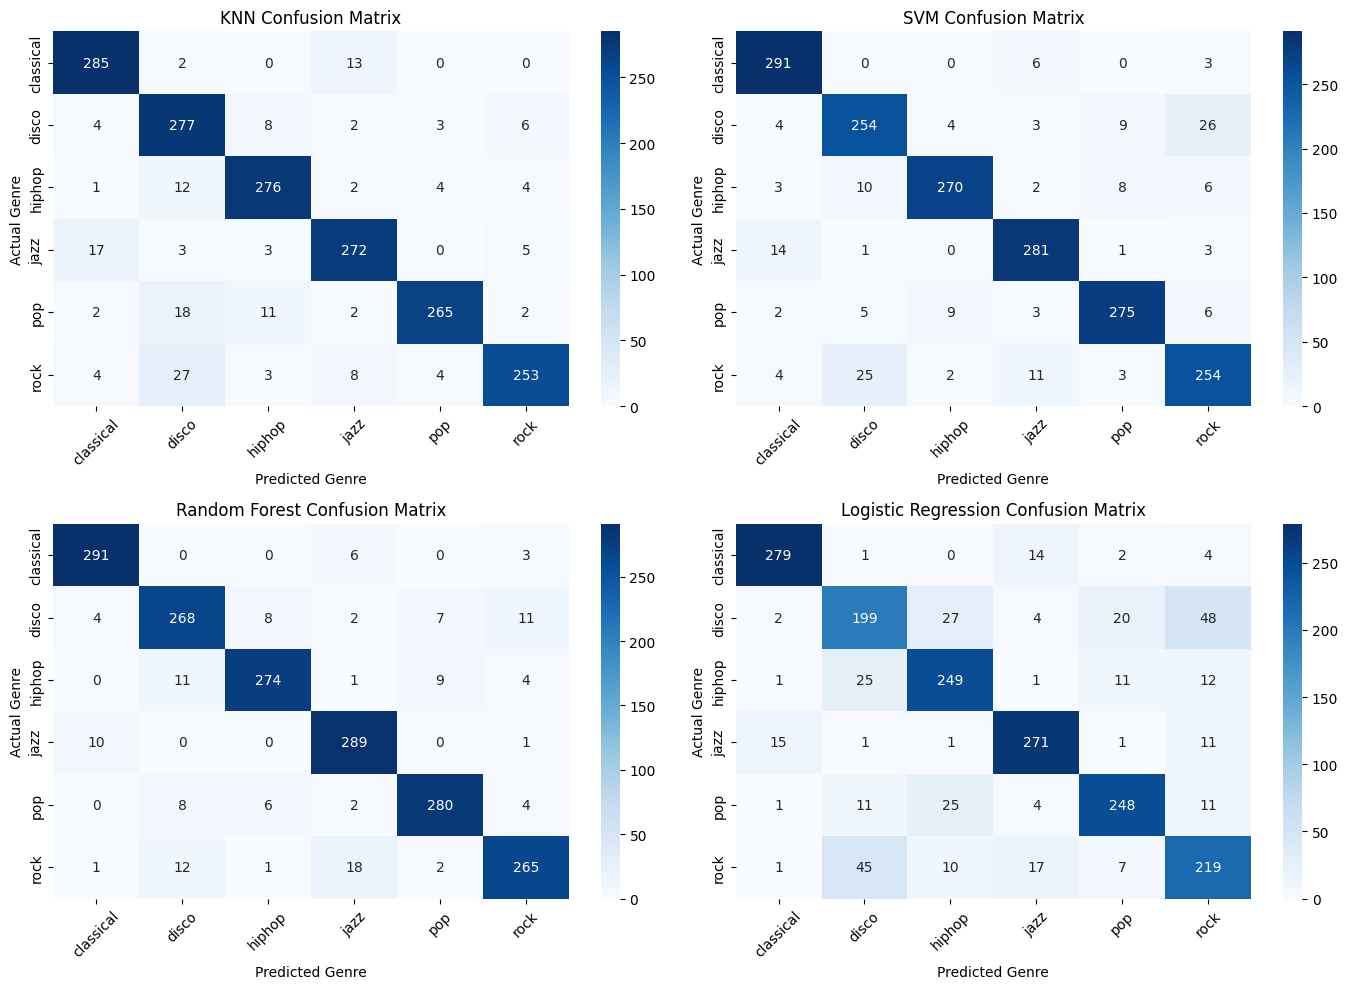

In [ ]:
#gurleen
#confusion matrix for all models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix


df=pd.read_excel("/content/features_3_sec.csv.xlsx")
# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")


fig, axes = plt.subplots(2, 2, figsize=(14, 10))#creates four empty plot boxes on a 14×10 inch canvas.
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
  y_pred = model.predict(X_test_scaled)
  print(f"\n {name} CLASSIFICATION REPORT ")
  print(classification_report(y_test, y_pred))
  '''Loops over the key-value pairs stored in your models dictionary (where keys are algorithm names like "SVM" or "Random Forest", and values are the trained model objects)
     enumerate(...): Wraps the dictionary loop with an automatic loop counter idx starting at 0 (0, 1, 2, 3).
     Variable Unpacking idx, (name, model): On each pass through the loop, Python assigns:
idx: The current position index integer (0 for 1st model, 1 for 2nd, etc.). This index tells Seaborn which specific box in the 2×2 grid (ax=axes[idx]) to plot the confusion matrix into.
name: The text string of the algorithm's name (e.g., 'Random Forest').'''

  # Plot Confusion Matrix in subplot
  cm = confusion_matrix(y_test, y_pred)
  sns.heatmap(
      cm,
      annot=True,
      fmt='d',
      cmap='Blues',
      xticklabels=model.classes_,
      yticklabels=model.classes_,
      ax=axes[idx],
  )
  axes[idx].set_title(f'{name} Confusion Matrix', fontsize=12)
  axes[idx].set_xlabel('Predicted Genre')
  axes[idx].set_ylabel('Actual Genre')
  axes[idx].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


In [1]:
#Snigdha
#CNN code = installing
!pip install -q librosa soundfile

import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
#The core open-source deep learning framework developed by Google, used for building and training neural networks.
from tqdm.notebook import tqdm
#Imports the Keras API modules used to construct neural network architectures.
#models lets you build models (like Sequential), and layers provides building blocks (like Dense, Conv2D, Dropout).
from sklearn.model_selection import train_test_split
#A utility function used to convert integer-encoded class labels into one-hot encoded vectors (e.g., class 2 out of 3 classes becomes [0, 0, 1]).
from sklearn.preprocessing import LabelEncoder
#Splits arrays or dataframes into random train and test subsets to train and evaluate the machine learning model.
from sklearn.metrics import confusion_matrix, classification_report
#Converts categorical text labels (like "dog", "cat", "car") into numerical integers (0, 1, 2) that neural networks can process.
from tensorflow.keras.utils import to_categorical
#Evaluation metrics tools used at the end of training to check accuracy, precision, recall, and F1-score.
from tensorflow.keras import layers, models
#Imports a progress bar specifically optimized for Jupyter Notebooks and JupyterLab.
# It is often wrapped around loops to show real-time progress when processing large datasets of audio files.
'''
!pip install -q librosa soundfile

import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.utils import to_categorical
'''


'\n!pip install -q librosa soundfile\n\nimport os\nimport numpy as np\nimport pandas as pd\nimport librosa\nimport librosa.display\nimport matplotlib.pyplot as plt\n\nimport tensorflow as tf\nfrom tensorflow.keras import layers, models\n\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.preprocessing import LabelEncoder\nfrom sklearn.metrics import confusion_matrix, classification_report\nfrom tensorflow.keras.utils import to_categorical\n'

In [8]:
#Snigdha
#Dataset of CNN

import os
import pandas as pd

DATA_DIR = '/content'
data = []

for file in os.listdir(DATA_DIR):
    # .lower() ensures it catches .WAV, .wav, .AU, etc.
    if file.lower().endswith(('.wav', '.au')):
        genre = file.split('.')[0]
        file_path = os.path.join(DATA_DIR, file)
        data.append((genre, file_path))

df = pd.DataFrame(data, columns=['genre', 'file_path'])

print(f'Total files: {len(df)}')
print(df['genre'].value_counts())

Total files: 18
genre
jazz         3
disco        3
pop          3
classical    3
rock         3
hiphop       3
Name: count, dtype: int64


In [13]:
#Snigdha
#CNN part Mel Spectogram extraction
SR = 22050
N_FFT      = 2048
HOP_LENGTH = 512
N_MELS     = 128

def extract_mel_spectrogram(file_path, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    y, sr   = librosa.load(file_path, sr=sr)
    mel     = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels)
    mel_db  = librosa.power_to_db(mel, ref=np.max)
    return mel_db
'''
mel_spectrograms = []
labels           = []
for idx, row in tqdm(df.iterrows(), total=len(df), desc='Extracting Mel spectrograms'):
    try:
        mel = extract_mel_spectrogram(row['path'])
        mel_spectrograms.append(mel)
        labels.append(row['label'])
    except Exception as e:
        print(f'Error: {row["path"]}: {e}')

print(f'Extracted {len(mel_spectrograms)} spectrograms')
print(f'Spectrogram shape (raw): {mel_spectrograms[0].shape}')  # (128, 173) for 4s @ 22050Hz
'''
mel_spectrograms = []
labels = []

for idx, row in tqdm(df.iterrows(), total=len(df), desc='Extracting Mel spectrograms'):
    try:
        # Changed 'path' to 'file_path'
        mel = extract_mel_spectrogram(row['file_path'])
        mel_spectrograms.append(mel)

        # Changed 'label' to 'genre'
        labels.append(row['genre'])
    except Exception as e:
        print(f'Error: {row["file_path"]}: {e}')

print(f'Extracted {len(mel_spectrograms)} spectrograms')
print(f'Spectrogram shape: {mel_spectrograms[0].shape}')


Extracting Mel spectrograms:   0%|          | 0/18 [00:00<?, ?it/s]

Extracted 18 spectrograms
Spectrogram shape: (128, 1293)


Found genres to plot: ['jazz', 'disco', 'pop', 'classical', 'rock', 'hiphop']


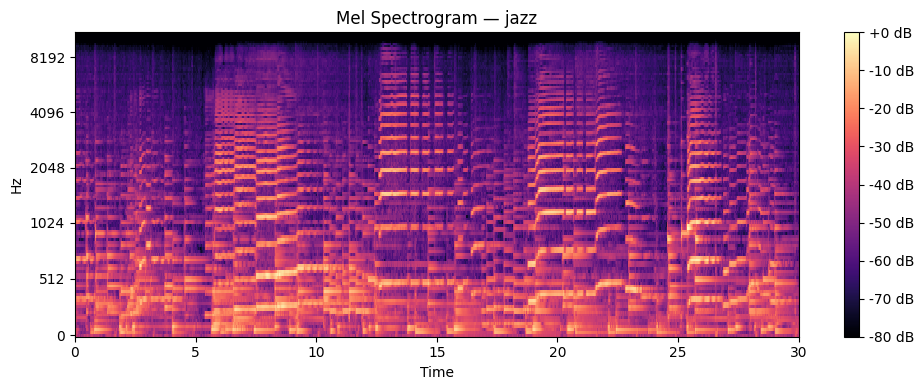

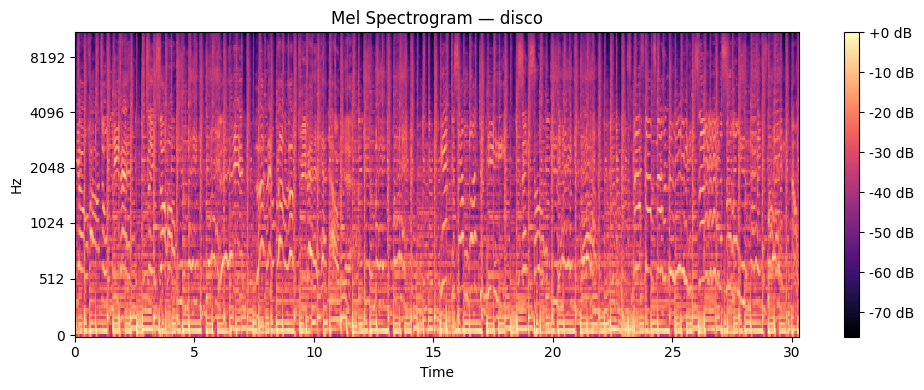

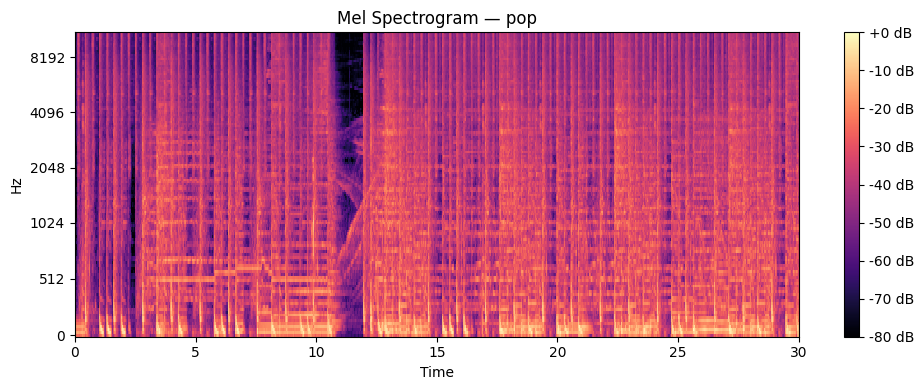

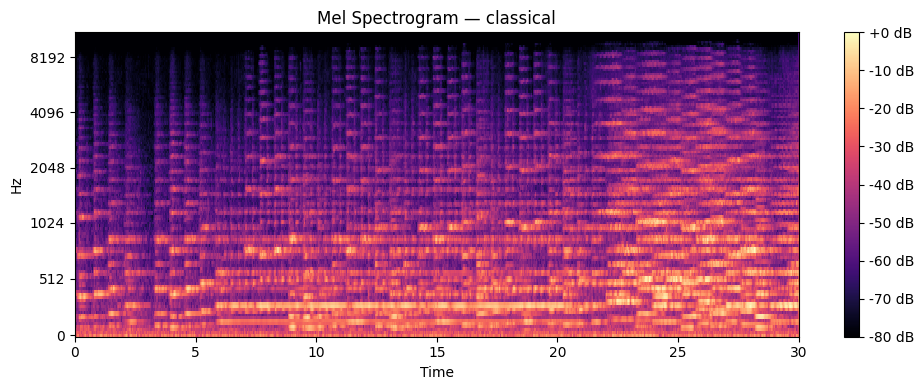

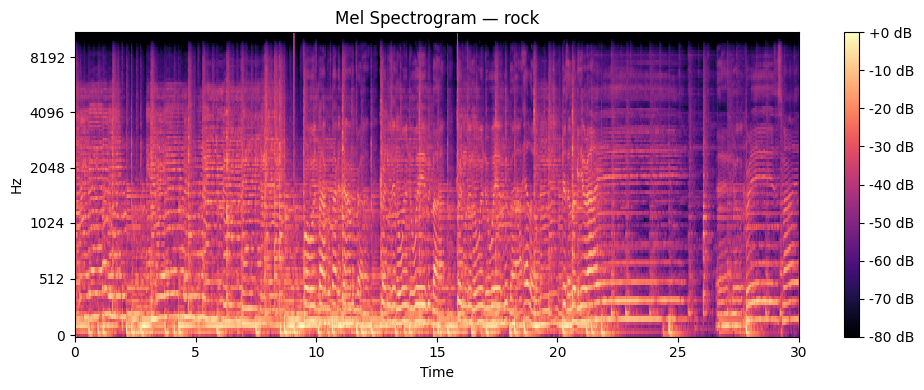

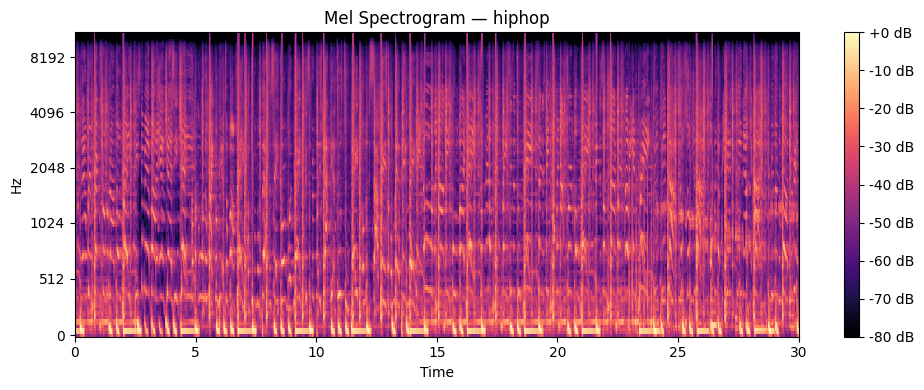

In [16]:
#Snigdha
#Visualising the spectrogram
'''
import matplotlib.pyplot as plt
import librosa.display
import numpy as np

# Find all unique genres present in your DataFrame
unique_genres = df['genre'].unique()

# Loop through each genre and plot its spectrogram
for genre in unique_genres:
    # Pick the first audio file that matches this genre
    sample_row = df[df['genre'] == genre].iloc[0]
    file_path = sample_row['file_path']

    # Load audio and generate its Mel spectrogram
    y, sr = librosa.load(file_path, sr=SR)
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
    mel_db = librosa.power_to_db(mel, ref=np.max)
plt.figure(figsize=(10, 4))
librosa.display.specshow(mel_spectrograms[0], sr=SR, hop_length=HOP_LENGTH,
                         x_axis='time', y_axis='mel', cmap='magma')
plt.colorbar(format='%+2.0f dB')
plt.title(f'Mel Spectrogram — {labels[0]}')
plt.tight_layout()
plt.show()
'''
import matplotlib.pyplot as plt
import librosa.display
import numpy as np

# Get all unique genres from your dataframe
unique_genres = df['genre'].unique()
print(f"Found genres to plot: {list(unique_genres)}")

# Loop through every unique genre and display its spectrogram
for genre in unique_genres:
    # Pick the first file belonging to this genre
    sample_row = df[df['genre'] == genre].iloc[0]
    file_path = sample_row['file_path']

    # Load audio and compute Mel spectrogram
    y, sr = librosa.load(file_path, sr=SR)
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
    mel_db = librosa.power_to_db(mel, ref=np.max)

    # Plotting
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(mel_db, sr=sr, hop_length=HOP_LENGTH, x_axis='time', y_axis='mel')
    plt.colorbar(format='%+2.0f dB')
    plt.title(f'Mel Spectrogram — {genre}')
    plt.tight_layout()
    plt.show()

In [22]:
#Snigdha
#Resizing in CNN
import numpy as np

FIXED_WIDTH = 130

# Pad or truncate every spectrogram and assign directly to X_raw
processed = []
for mel in mel_spectrograms:
    if mel.shape[1] > FIXED_WIDTH:
        processed.append(mel[:, :FIXED_WIDTH])
    else:
        processed.append(np.pad(mel, ((0, 0), (0, FIXED_WIDTH - mel.shape[1])), mode='constant'))

X_raw = np.array(processed)
y_raw = np.array(labels)

print("X_raw shape:", X_raw.shape)
print("y_raw shape:", y_raw.shape)

X_raw shape: (18, 128, 130)
y_raw shape: (18,)


Combined DataFrame shape: (5993, 60)
Dataset shape: (5993, 60)

Missing values in dataset:
 filename                   0
length                     0
chroma_stft_mean           0
chroma_stft_var            0
rms_mean                   0
rms_var                    0
spectral_centroid_mean     0
spectral_centroid_var      0
spectral_bandwidth_mean    0
spectral_bandwidth_var     0
rolloff_mean               0
rolloff_var                0
zero_crossing_rate_mean    0
zero_crossing_rate_var     0
harmony_mean               0
harmony_var                0
perceptr_mean              0
perceptr_var               0
tempo                      0
mfcc1_mean                 0
mfcc1_var                  0
mfcc2_mean                 0
mfcc2_var                  0
mfcc3_mean                 0
mfcc3_var                  0
mfcc4_mean                 0
mfcc4_var                  0
mfcc5_mean                 0
mfcc5_var                  0
mfcc6_mean                 0
mfcc6_var                  0
mfcc7_mea

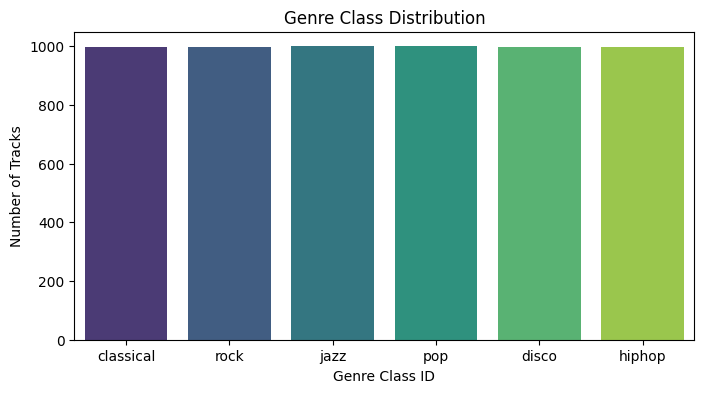

In [ ]:
#gurleen
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df=pd.read_excel("/content/features_3_sec.csv.xlsx")
# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")


# Inspect shape and missing values
print("Dataset shape:", df.shape)
print("\nMissing values in dataset:\n", df.isnull().sum())

# 3. Check class balance across genres
print("CLASS BALANCE ACROSS GENRES")
print(df['label'].value_counts())

# 4. Plot class distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='label', palette='viridis',hue='label')# hue tells seaborn to differentiate genres visually
plt.title('Genre Class Distribution')
plt.xlabel('Genre Class ID')
plt.ylabel('Number of Tracks')
plt.show()

In [ ]:
#Snigdha
#work to be done now
'''
KNN (K-Nearest Neighbors): Looks at a new data point and finds the closest matching data points in your existing dataset, assigning it the most common category among
those neighbors.
SVM (Support Vector Machine): Draws an optimal dividing line (or boundary) through your data space to separate different categories from each other as cleanly as possible.
Random Forest: Builds multiple decision trees using random parts of your data and combines their individual votes to make a final, highly accurate classification.
Logistic Regression: Calculates the mathematical probability that a data point belongs to a particular class (using a score from 0 to 1) to make a binary decision.
Feature Scaling: Adjusts and standardizes the numeric ranges of your data columns so that variables with large numbers don't unfairly overpower smaller numbers during
calculations.
CNN on Spectrogram Images: Takes sound or time-series signal data, converts it into a visual frequency graph (spectrogram), and scans that image to recognize patterns.
'''


Number of tracks per genre:
label
classical     998
disco         999
hiphop        998
jazz         1000
pop          1000
rock          998
Name: filename, dtype: int64


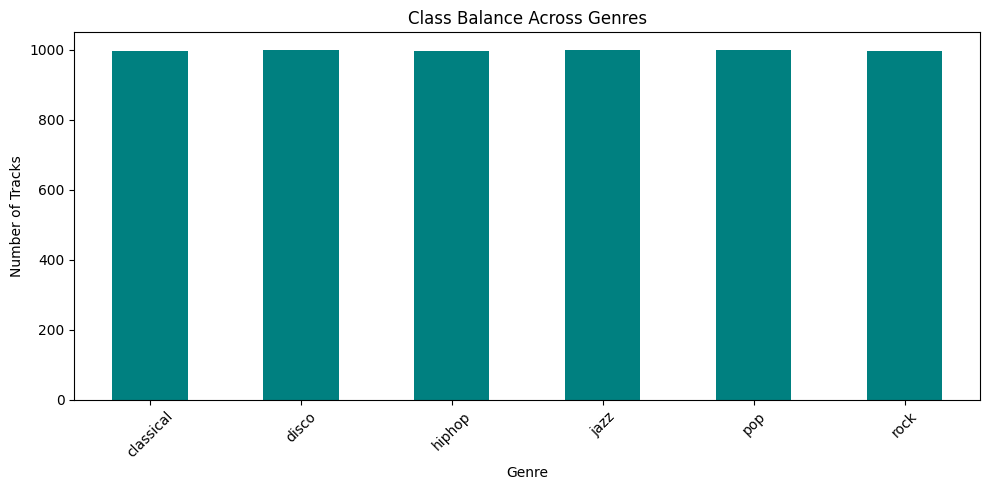

In [ ]:
#Dhanya
# Check class balance across genres
# df must contain a "label" column.
# For sliced audio data, count unique filenames so each track is counted once.

if "filename" in df.columns:
    genre_counts = df.groupby("label")["filename"].nunique().sort_index()
else:
    genre_counts = df["label"].value_counts().sort_index()

print("Number of tracks per genre:")
print(genre_counts)

genre_counts.plot(kind="bar", figsize=(10, 5), color="teal")
plt.title("Class Balance Across Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Dhanya
# Song-similarity recommender using cosine similarity
# Use the 30-second feature DataFrame, with one row per track.
# Required columns: "filename", "label", plus numeric audio features.

import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

metadata_cols = {"filename", "label", "track_id"}
feature_cols = [
    col for col in df.select_dtypes(include="number").columns
    if col not in metadata_cols
]

songs = df.dropna(subset=feature_cols).reset_index(drop=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(songs[feature_cols])
similarity = cosine_similarity(X_scaled)

query = input("Enter a song filename or a unique part of it: ").strip()
matches = songs[
    songs["filename"].astype(str).str.contains(query, case=False, regex=False)
]

if matches.empty:
    print("No matching song found.")
else:
    query_idx = matches.index[0]
    scores = similarity[query_idx]

    recommendations = pd.DataFrame({
        "filename": songs["filename"],
        "genre": songs["label"],
        "similarity": scores
    })

    recommendations = (
        recommendations.drop(index=query_idx)
        .sort_values("similarity", ascending=False)
        .head(5)
        .reset_index(drop=True)
    )

    print("Similar songs:")
    display(recommendations)

Enter a song filename or a unique part of it: /content/rock.00006.wav
No matching song found.


In [ ]:
# Recommend dataset songs similar to an uploaded WAV
# Run Part 1 first so its SQLite database exists.

from pathlib import Path
import io
import sqlite3
import zipfile

import librosa
import numpy as np
import pandas as pd
from google.colab import files
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

DB_PATH = Path("/content/outputs/part1/music_genre.db")

if not DB_PATH.exists():
    raise FileNotFoundError("Run Part 1 first; its SQLite database was not found.")

# Load one row per song.
with sqlite3.connect(DB_PATH) as connection:
    songs = pd.read_sql_query("SELECT * FROM features_30_sec", connection)

# Use numeric audio features; exclude metadata and identifiers.
excluded = {"length", "track_id"}
feature_cols = [
    col for col in songs.select_dtypes(include="number").columns
    if col not in excluded
]

if not feature_cols:
    raise ValueError("No numeric audio features were found.")

# Fit the same preprocessing steps on the dataset.
X = songs[feature_cols].replace([np.inf, -np.inf], np.nan)

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
dataset_scaled = scaler.fit_transform(X_imputed)

print(f"Loaded {len(songs)} songs and {len(feature_cols)} audio features.")

def extract_uploaded_song_features(audio_path, feature_cols, sr=22050):
    """Extract features using the CSV's mean/var column naming."""
    y, sr = librosa.load(audio_path, sr=sr, mono=True)

    if len(y) == 0:
        raise ValueError("The uploaded audio file is empty or unreadable.")

    feature_values = {}

    def add_mean_var(prefix, values):
        values = np.asarray(values).ravel()
        feature_values[f"{prefix}_mean"] = float(np.mean(values))
        feature_values[f"{prefix}_var"] = float(np.var(values))

    # Chroma, RMS, and spectral features
    add_mean_var(
        "chroma_stft",
        librosa.feature.chroma_stft(y=y, sr=sr)
    )
    add_mean_var("rms", librosa.feature.rms(y=y)[0])
    add_mean_var(
        "spectral_centroid",
        librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    )
    add_mean_var(
        "spectral_bandwidth",
        librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
    )
    add_mean_var(
        "rolloff",
        librosa.feature.spectral_rolloff(y=y, sr=sr)[0]
    )
    add_mean_var(
        "zero_crossing_rate",
        librosa.feature.zero_crossing_rate(y)[0]
    )

    # Harmonic/percussive components
    harmonic, percussive = librosa.effects.hpss(y)
    add_mean_var("harmony", harmonic)
    add_mean_var("perceptr", percussive)

    # Tempo
    tempo = librosa.beat.tempo(y=y, sr=sr)
    feature_values["tempo"] = float(np.asarray(tempo).ravel()[0])

    # MFCCs
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    for i in range(20):
        add_mean_var(f"mfcc{i + 1}", mfcc[i])

    missing = [col for col in feature_cols if col not in feature_values]
    if missing:
        raise ValueError(
            "The extractor is missing dataset columns: " + ", ".join(missing)
        )

    return pd.DataFrame(
        [[feature_values[col] for col in feature_cols]],
        columns=feature_cols
    )

# Upload a WAV, or a ZIP containing a WAV.
uploaded = files.upload()

audio_path = None
audio_name = None

for uploaded_name in uploaded:
    if uploaded_name.lower().endswith(".wav"):
        audio_path = Path("/content") / Path(uploaded_name).name
        audio_path.write_bytes(uploaded[uploaded_name])
        audio_name = audio_path.name
        break

    if uploaded_name.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(uploaded[uploaded_name])) as archive:
            wav_files = [
                name for name in archive.namelist()
                if name.lower().endswith(".wav")
                and not name.endswith("/")
            ]

            if wav_files:
                wav_member = wav_files[0]
                audio_name = Path(wav_member).name
                audio_path = Path("/content") / audio_name
                audio_path.write_bytes(archive.read(wav_member))
                break

if audio_path is None:
    raise ValueError("Upload a .wav file or a ZIP file containing a .wav.")

# Extract and transform the uploaded song with the dataset's fitted imputer/scaler.
uploaded_features = extract_uploaded_song_features(
    str(audio_path), feature_cols
)
uploaded_imputed = imputer.transform(uploaded_features)
uploaded_scaled = scaler.transform(uploaded_imputed)

# Find the five most similar dataset songs.
similarity_scores = cosine_similarity(
    uploaded_scaled, dataset_scaled
)[0]

top_indices = np.argsort(similarity_scores)[::-1][:5]

recommendations = songs.loc[
    top_indices, ["filename", "label"]
].copy()
recommendations.insert(0, "similarity", similarity_scores[top_indices])

print(f"Songs most similar to uploaded track: {audio_name}")
display(recommendations.reset_index(drop=True))

Codes with few new methods and comparisions


In [ ]:
# DHANYA
# part 1
# part 2.0
# part 2.1
# part 2.2
# part 2.3
# part 2.4
# part 2.5
# part 3
# part 4


In [ ]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
from pathlib import Path
from google.colab import files

for expected_name in [
    "features_30_sec.csv.zip",
    "features_3_sec.csv.zip",
]:
    expected_path = Path("/content") / expected_name

    while not expected_path.exists():
        print(f"Choose the file named exactly: {expected_name}")
        uploaded = files.upload()

        if expected_name not in uploaded:
            print("That wasn't the requested ZIP. Please choose the matching ZIP file.")

30-second dataset shape: (1000, 61)
3-second dataset shape: (9990, 61)
30-second unique tracks: 1000
3-second unique tracks: 1000

Missing cells:
30-second: 0
3-second: 0

Duplicate full rows:
30-second: 0
3-second: 0

Original tracks per genre:


,original_track_count
label,
blues,100
classical,100
country,100
disco,100
hiphop,100
jazz,100
metal,100
pop,100
reggae,100



3-second slices per genre:


,slice_count
label,
blues,1000
classical,998
country,997
disco,999
hiphop,998
jazz,1000
metal,1000
pop,1000
reggae,1000



Number of 3-second slices per original track:
9      10
10    990

Numeric audio feature columns: 57
Genres: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']

SQLite database written: /content/outputs/part1/music_genre.db


,dataset,genre,original_track_count,row_or_slice_count
0,features_30_sec,blues,100,100
1,features_30_sec,classical,100,100
2,features_30_sec,country,100,100
3,features_30_sec,disco,100,100
4,features_30_sec,hiphop,100,100
5,features_30_sec,jazz,100,100
6,features_30_sec,metal,100,100
7,features_30_sec,pop,100,100
8,features_30_sec,reggae,100,100
9,features_30_sec,rock,100,100


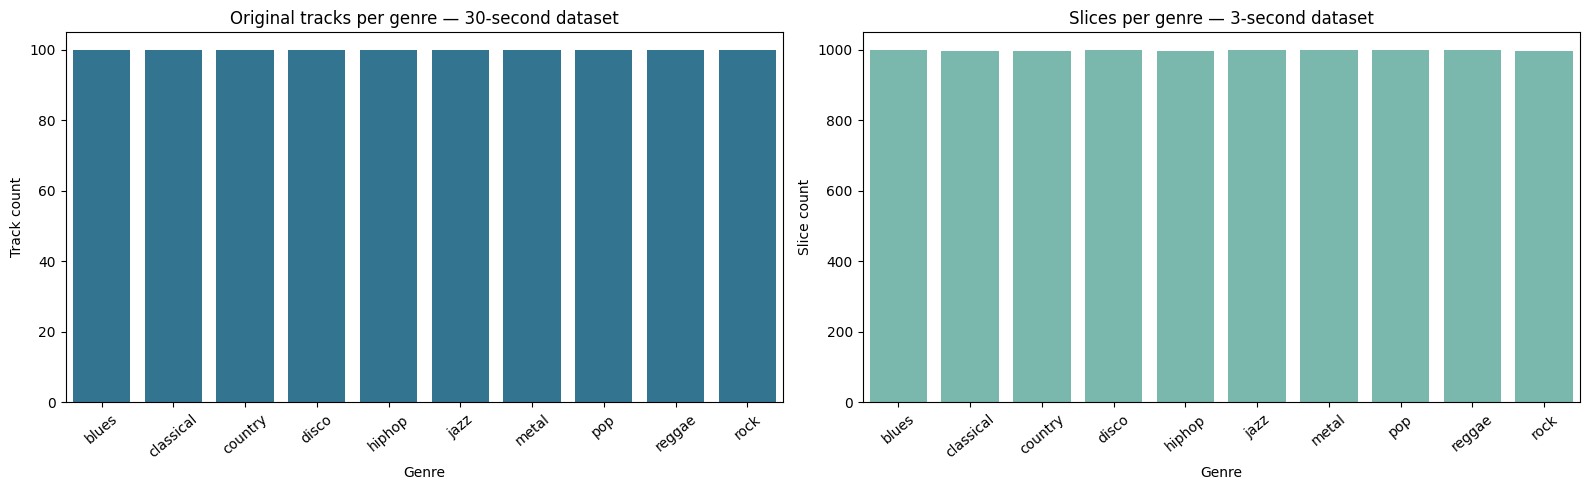

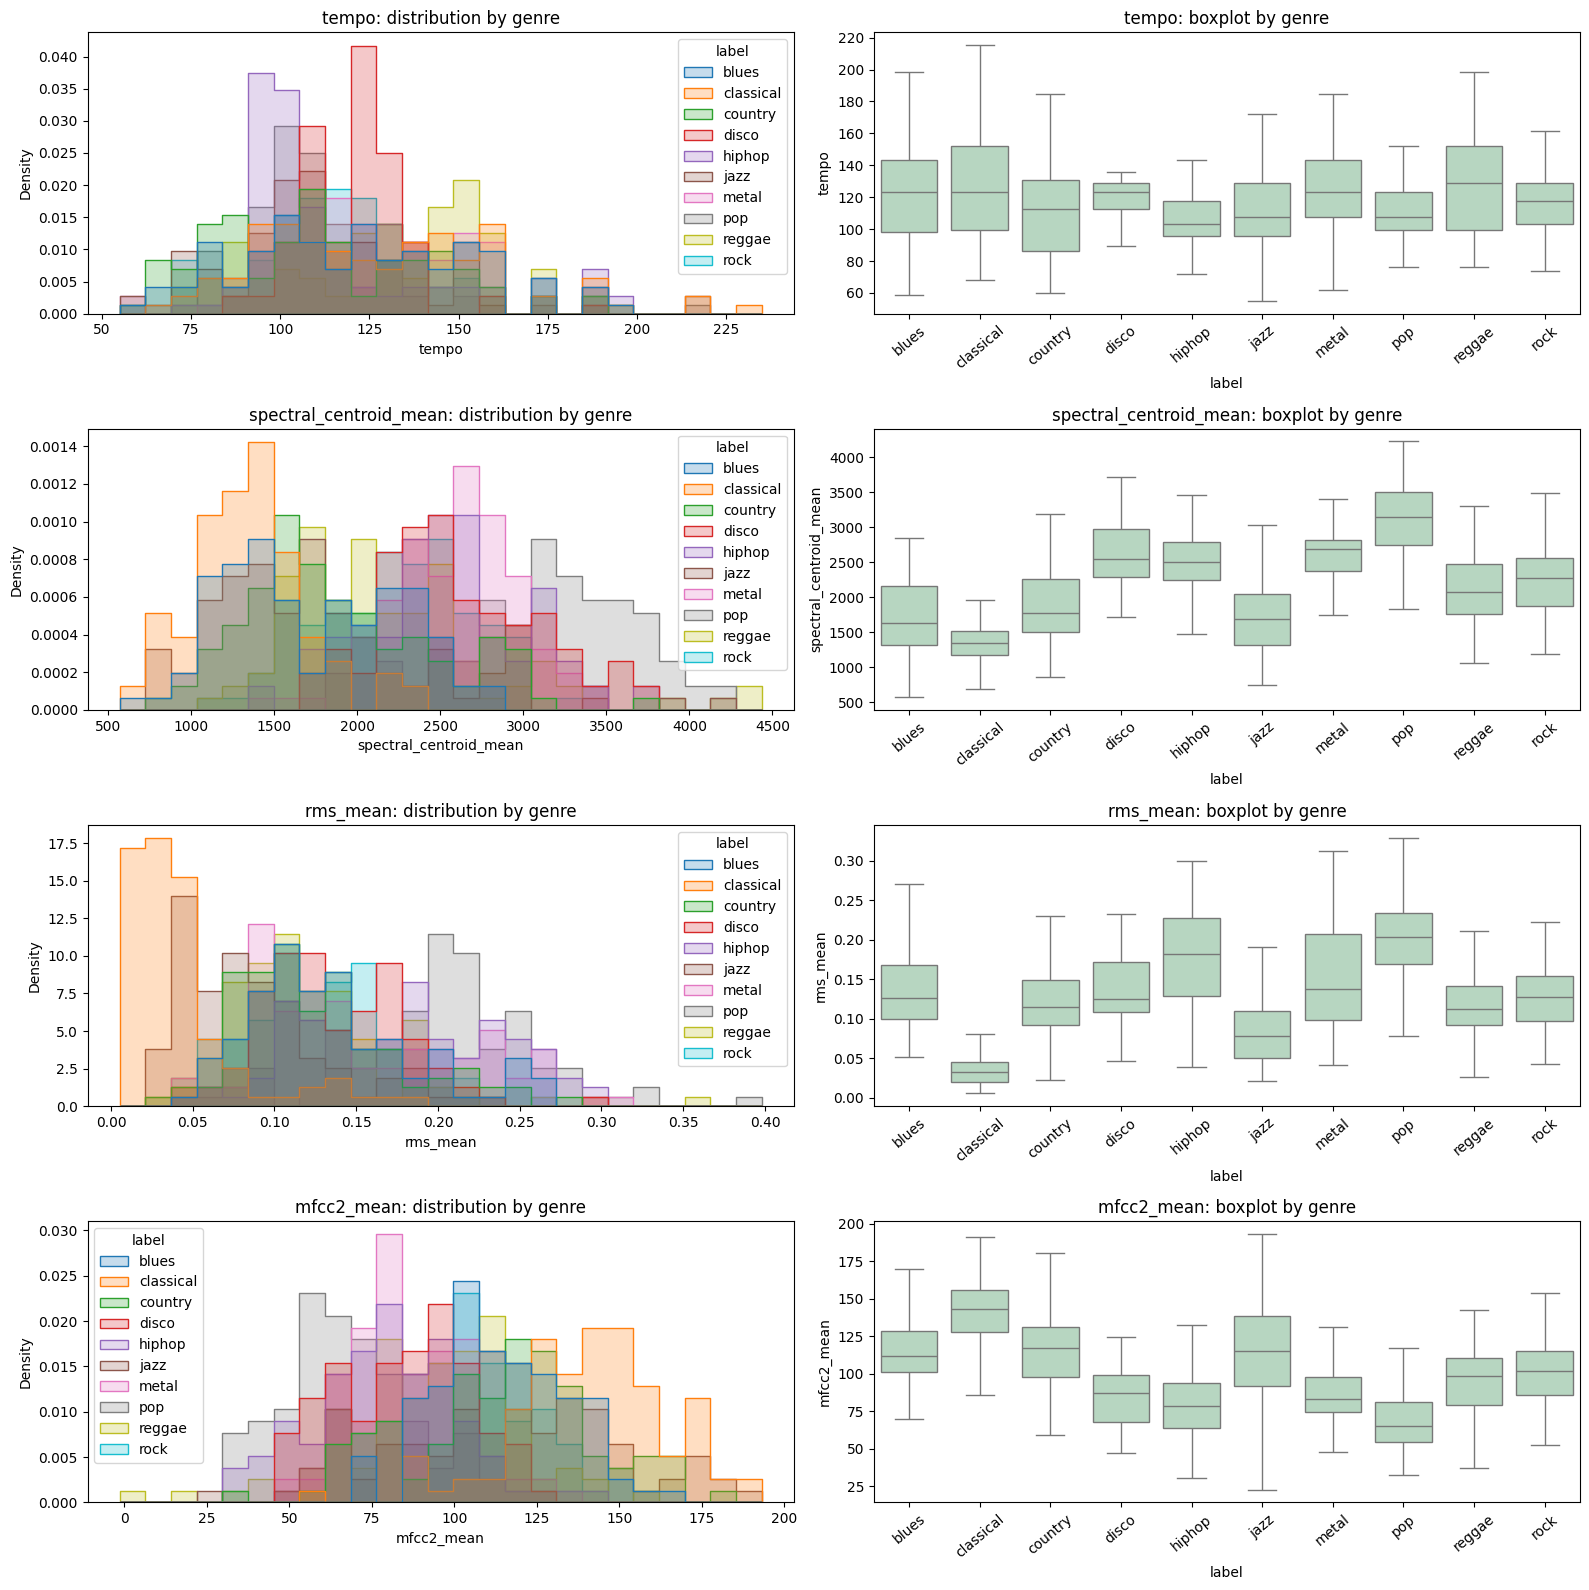


Top 15 EDA-ranked features:


,feature,anova_f_score,p_value
0,chroma_stft_mean,176.453282,7.683150e-199
17,mfcc1_mean,130.371835,2.494661e-161
6,spectral_bandwidth_mean,116.601879,9.982752e-149
8,rolloff_mean,110.871317,2.939032e-143
4,spectral_centroid_mean,97.484924,6.437171e-130
23,mfcc4_mean,83.868555,1.887743e-115
19,mfcc2_mean,83.189909,1.053923e-114
5,spectral_centroid_var,82.134648,1.546188e-113
15,perceptr_var,80.388712,1.358291e-111
2,rms_mean,74.194652,1.485967e-104


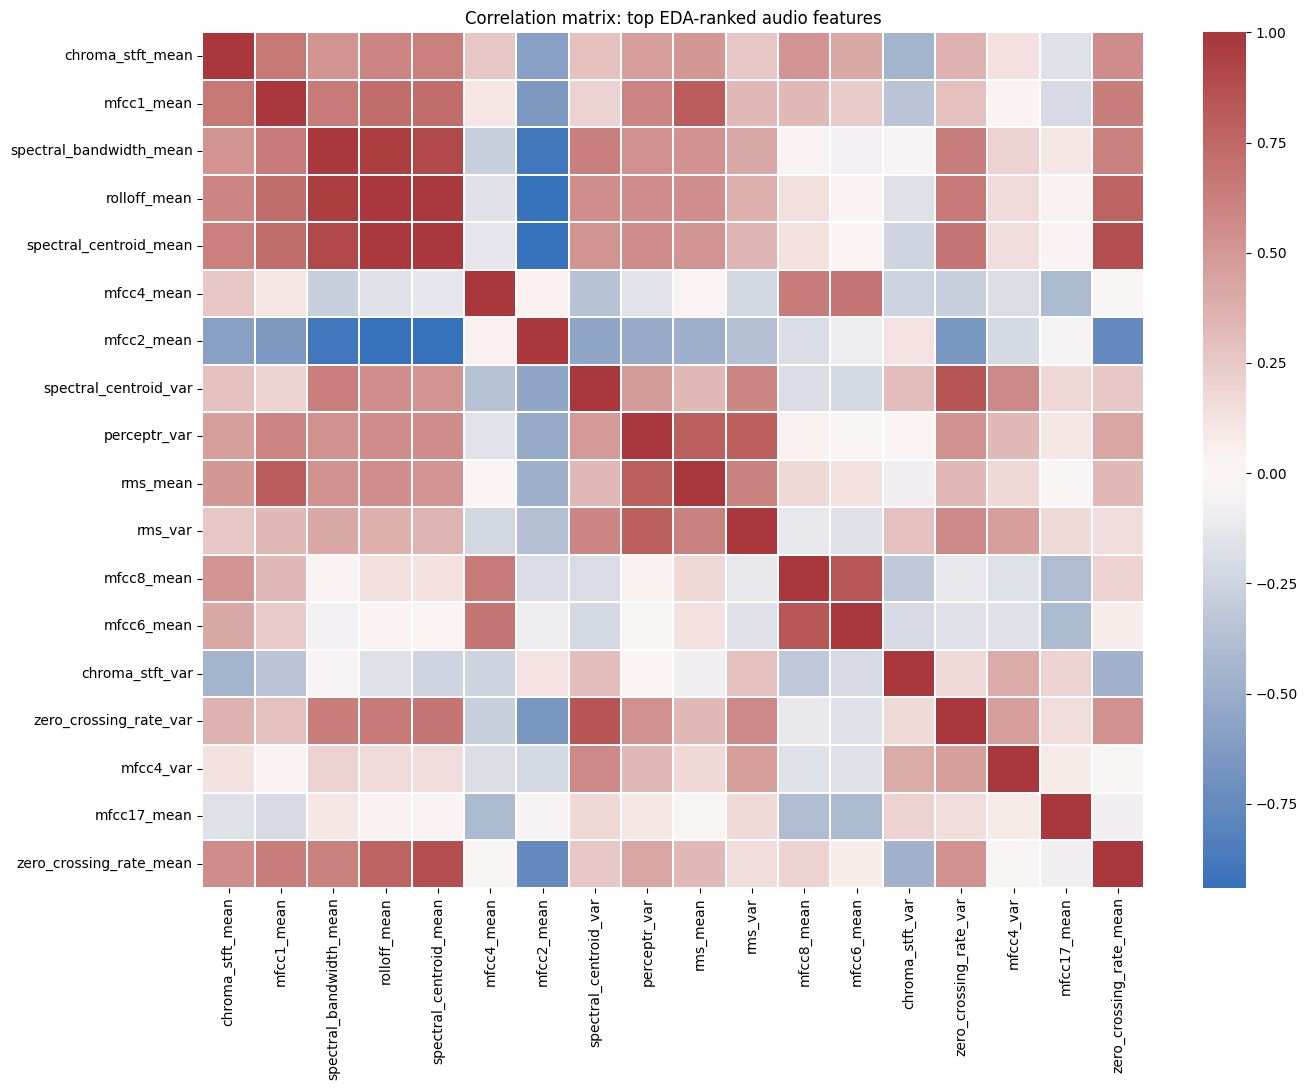

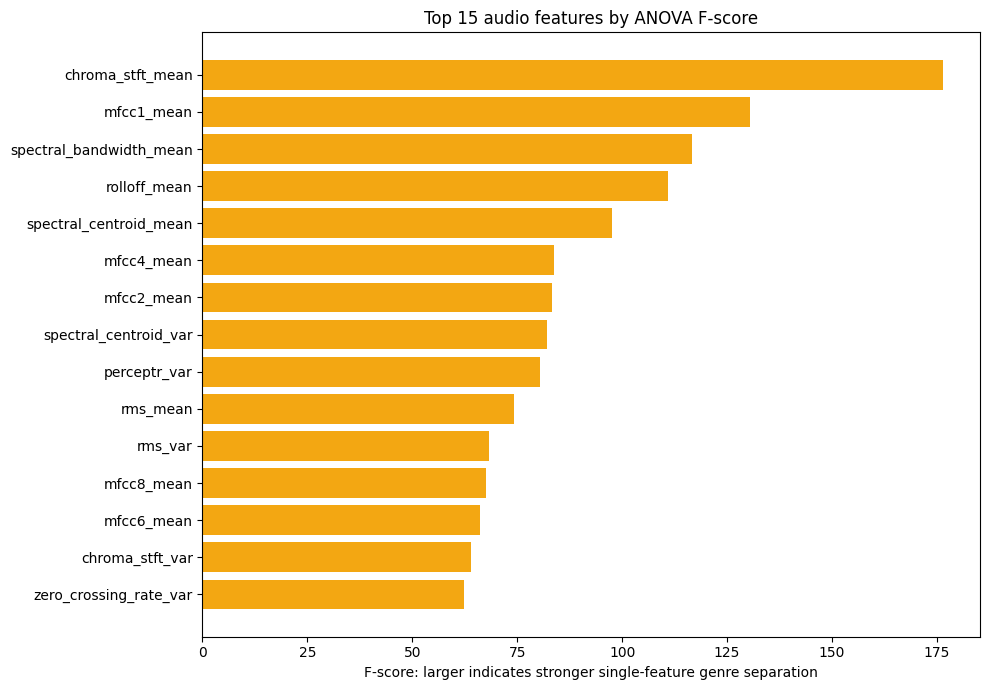

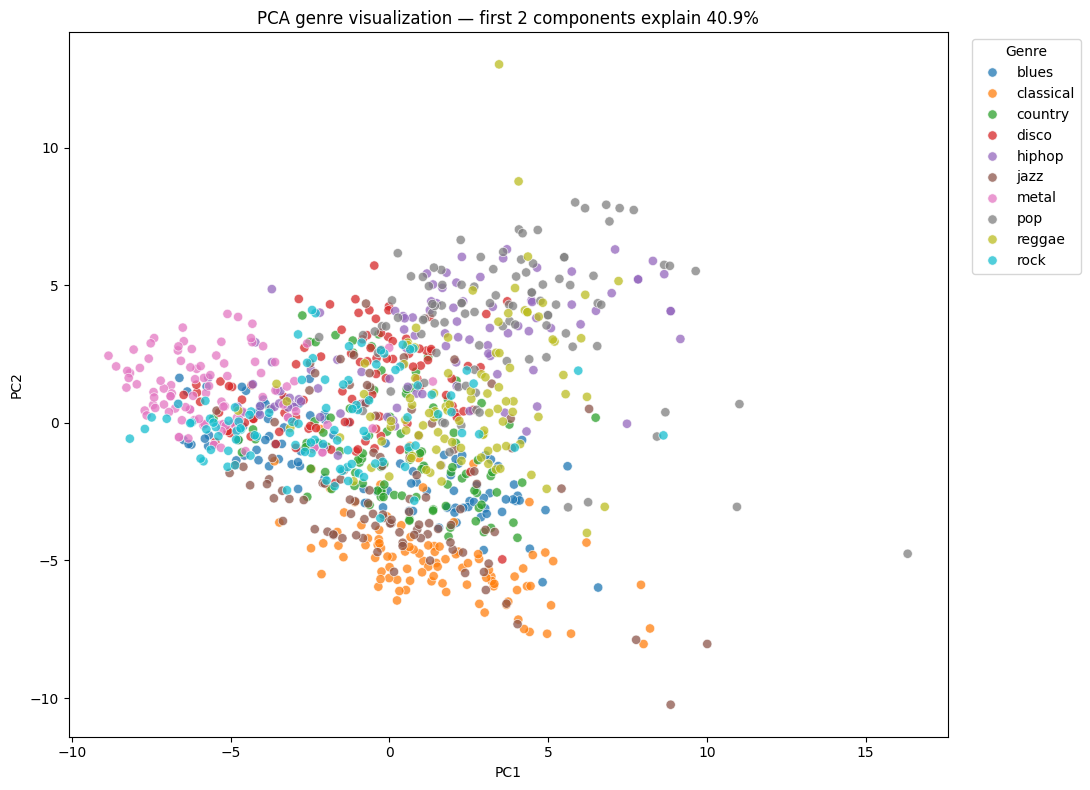

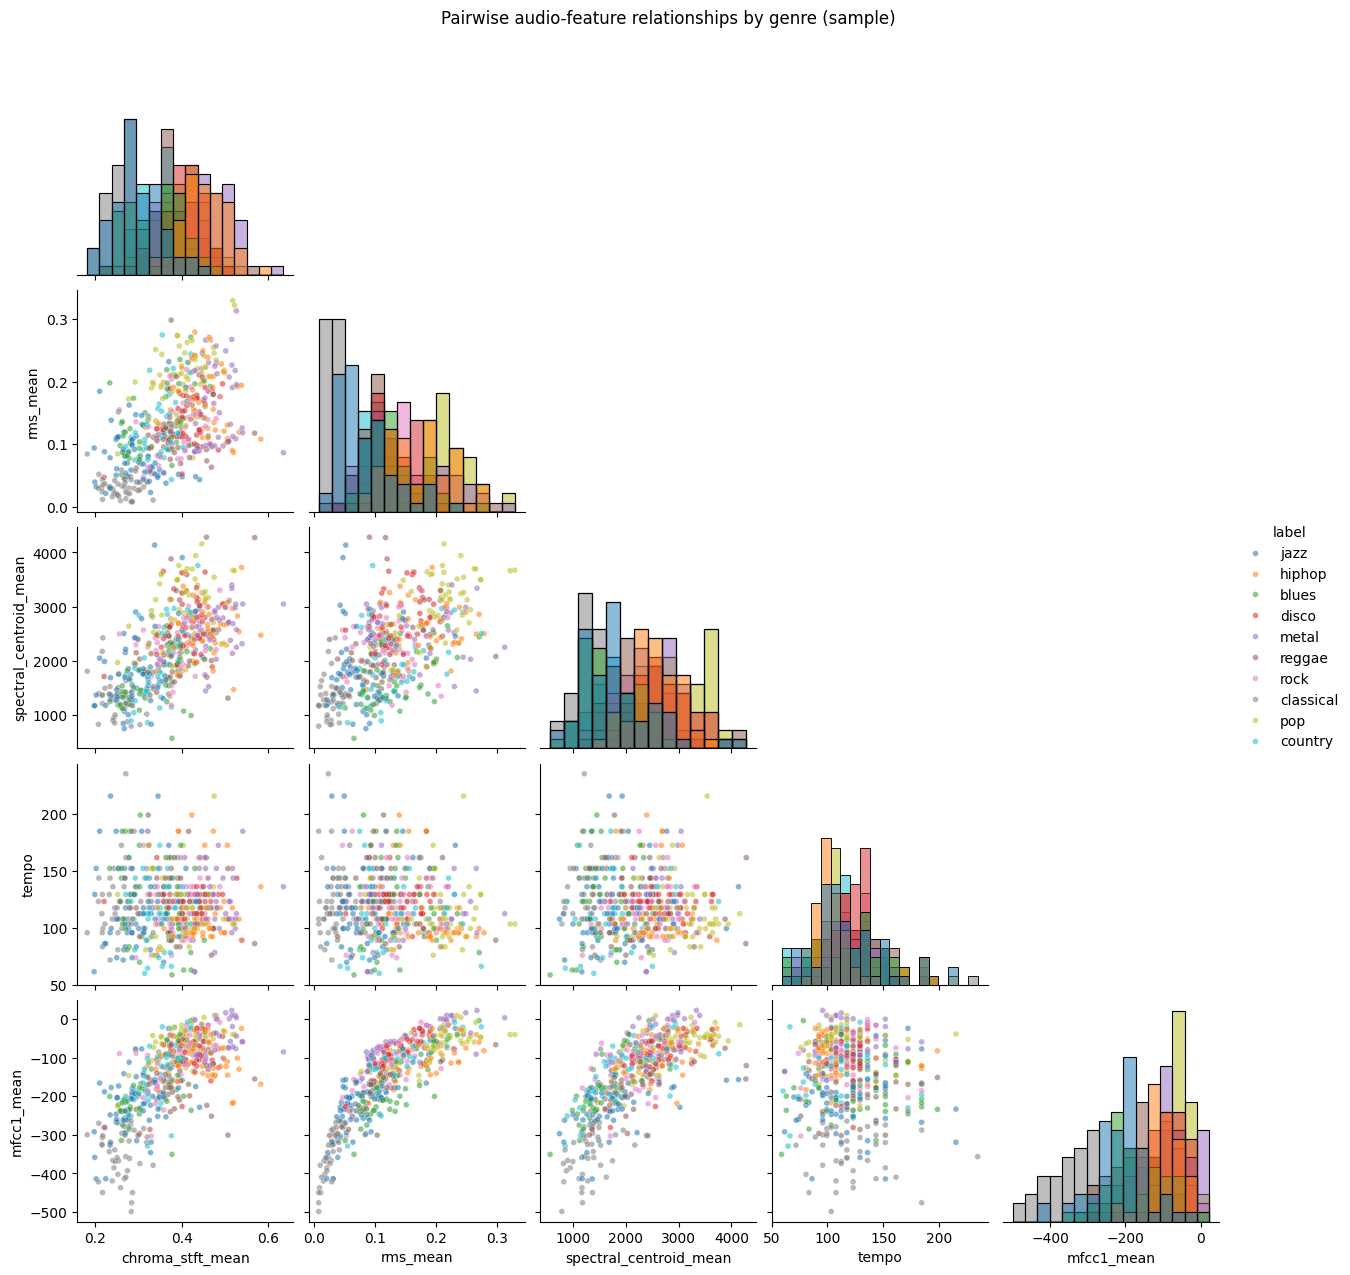


Part 1 complete.
Database, EDA figures, and reports are in: /content/outputs/part1
The source ZIP files were read only; they were not modified.


In [ ]:
# IDC409 MUSIC GENRE CLASSIFICATION — PART 1
#This part loads the 3-second and 30-second feature datasets for all 10 genres. It checks the data, counts tracks and slices per genre, and explores audio-feature distributions, correlations, and genre patterns. This helps us understand the dataset before training models.
# Uses the supplied pre-extracted feature CSVs.
# Supports all 10 GTZAN genres.

DATA_DIR = Path("/content")
OUTPUT_DIR = Path("/content/outputs/part1")
DB_PATH = OUTPUT_DIR / "music_genre.db"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

path_30 = DATA_DIR / "features_30_sec.csv.zip"
path_3 = DATA_DIR / "features_3_sec.csv.zip"

for path in [path_30, path_3]:
    if not path.exists():
        raise FileNotFoundError(
            f"Cannot find {path}. Upload both dataset ZIP files in Cell 1."
        )

# Read the CSV inside each ZIP without extracting or changing the source files.
df30 = pd.read_csv(path_30, compression="zip")
df3 = pd.read_csv(path_3, compression="zip")

# Create the original-song ID. The 3-second CSV has multiple slices per song.
df30["track_id"] = df30["filename"].astype(str).str.replace(
    r"\.wav$", "", regex=True
)
df3["track_id"] = df3["filename"].astype(str).str.replace(
    r"\.\d+\.wav$", "", regex=True
)

# Basic checks and summary.
required_columns = {"filename", "label", "track_id"}
for name, data in [("30-second", df30), ("3-second", df3)]:
    missing_columns = required_columns - set(data.columns)
    if missing_columns:
        raise ValueError(f"{name} data is missing columns: {missing_columns}")
    if data.empty:
        raise ValueError(f"{name} dataset is empty.")

print("30-second dataset shape:", df30.shape)
print("3-second dataset shape:", df3.shape)
print("30-second unique tracks:", df30["track_id"].nunique())
print("3-second unique tracks:", df3["track_id"].nunique())
print("\nMissing cells:")
print("30-second:", int(df30.isna().sum().sum()))
print("3-second:", int(df3.isna().sum().sum()))
print("\nDuplicate full rows:")
print("30-second:", int(df30.duplicated().sum()))
print("3-second:", int(df3.duplicated().sum()))

# Show the 10 genres and their counts.
print("\nOriginal tracks per genre:")
display(
    df30.groupby("label")["track_id"]
    .nunique()
    .sort_index()
    .rename("original_track_count")
    .to_frame()
)

print("\n3-second slices per genre:")
display(
    df3["label"]
    .value_counts()
    .sort_index()
    .rename("slice_count")
    .to_frame()
)

# Record how many slices each original song has.
slices_per_track = df3.groupby("track_id").size()
print("\nNumber of 3-second slices per original track:")
print(slices_per_track.value_counts().sort_index().to_string())

# Numeric audio features. "length" is metadata, not a model feature.
feature_cols = [
    col for col in df30.select_dtypes(include=np.number).columns
    if col != "length"
]
print(f"\nNumeric audio feature columns: {len(feature_cols)}")
print("Genres:", sorted(df30["label"].astype(str).unique()))

# Save datasets and a genre-count summary into SQLite.
summary_rows = []
for table_name, data in [
    ("features_30_sec", df30),
    ("features_3_sec", df3),
]:
    for genre, group in data.groupby("label"):
        summary_rows.append({
            "dataset": table_name,
            "genre": genre,
            "original_track_count": group["track_id"].nunique(),
            "row_or_slice_count": len(group),
        })

summary = pd.DataFrame(summary_rows)

with sqlite3.connect(DB_PATH) as connection:
    df30.to_sql("features_30_sec", connection, if_exists="replace", index=False)
    df3.to_sql("features_3_sec", connection, if_exists="replace", index=False)
    summary.to_sql("genre_summary", connection, if_exists="replace", index=False)

    # Read back from SQLite to show that the database was written successfully.
    db_summary = pd.read_sql_query(
        "SELECT * FROM genre_summary ORDER BY dataset, genre",
        connection,
    )

summary.to_csv(OUTPUT_DIR / "genre_summary.csv", index=False)
print(f"\nSQLite database written: {DB_PATH}")
display(db_summary)

# Class balance: original songs and 3-second slices.
track_counts = (
    df30.groupby("label")["track_id"].nunique().sort_index()
)
slice_counts = df3["label"].value_counts().reindex(track_counts.index)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=track_counts.index, y=track_counts.values, ax=axes[0], color="#247ba0")
axes[0].set_title("Original tracks per genre — 30-second dataset")
axes[0].set_xlabel("Genre")
axes[0].set_ylabel("Track count")
axes[0].tick_params(axis="x", rotation=40)

sns.barplot(x=slice_counts.index, y=slice_counts.values, ax=axes[1], color="#70c1b3")
axes[1].set_title("Slices per genre — 3-second dataset")
axes[1].set_xlabel("Genre")
axes[1].set_ylabel("Slice count")
axes[1].tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_class_and_slice_counts.png", dpi=180)
plt.show()
plt.close()

# Distribution histograms and boxplots for selected audio features.
distribution_features = [
    col for col in [
        "tempo",
        "spectral_centroid_mean",
        "rms_mean",
        "mfcc2_mean",
    ]
    if col in df30.columns
]

fig, axes = plt.subplots(
    len(distribution_features), 2,
    figsize=(16, 4 * len(distribution_features))
)
if len(distribution_features) == 1:
    axes = np.array([axes])

for row, feature in enumerate(distribution_features):
    sns.histplot(
        data=df30, x=feature, hue="label",
        bins=25, element="step", stat="density",
        common_norm=False, ax=axes[row, 0],
    )
    axes[row, 0].set_title(f"{feature}: distribution by genre")

    sns.boxplot(
        data=df30, x="label", y=feature,
        order=sorted(df30["label"].astype(str).unique()),
        showfliers=False, ax=axes[row, 1], color="#b2dbbf",
    )
    axes[row, 1].set_title(f"{feature}: boxplot by genre")
    axes[row, 1].tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_feature_histograms_and_boxplots.png", dpi=180)
plt.show()
plt.close()

# Descriptive ANOVA feature ranking for EDA.
# This ranking is for exploration. Part 2 fits feature selection only on training data.
X_eda = df30[feature_cols].replace([np.inf, -np.inf], np.nan)
X_eda = X_eda.fillna(X_eda.median(numeric_only=True))
y_eda = df30["label"].astype(str)

f_scores, p_values = f_classif(X_eda, y_eda)
ranking = pd.DataFrame({
    "feature": feature_cols,
    "anova_f_score": f_scores,
    "p_value": p_values,
}).replace([np.inf, -np.inf], np.nan)
ranking = ranking.sort_values("anova_f_score", ascending=False)
ranking.to_csv(OUTPUT_DIR / "feature_reduction_anova_ranking.csv", index=False)

print("\nTop 15 EDA-ranked features:")
display(ranking.head(15))

# Correlation matrix for the top 18 EDA-ranked features.
top_features = ranking["feature"].head(18).tolist()
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    df30[top_features].corr(),
    cmap="vlag",
    center=0,
    linewidths=0.2,
    ax=ax,
)
ax.set_title("Correlation matrix: top EDA-ranked audio features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_feature_correlation_matrix.png", dpi=180)
plt.show()
plt.close()

# Feature-ranking chart, useful for discussing feature reduction.
top15 = ranking.head(15).sort_values("anova_f_score")
plt.figure(figsize=(10, 7))
plt.barh(top15["feature"], top15["anova_f_score"], color="#f3a712")
plt.title("Top 15 audio features by ANOVA F-score")
plt.xlabel("F-score: larger indicates stronger single-feature genre separation")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_feature_ranking.png", dpi=180)
plt.show()
plt.close()

# PCA plot: descriptive visualization of the 30-second tracks.
# This PCA is for EDA only, not used to evaluate the models.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_eda)
pca = PCA(n_components=2, random_state=409)
coordinates = pca.fit_transform(X_scaled)

pca_data = pd.DataFrame(coordinates, columns=["PC1", "PC2"])
pca_data["label"] = df30["label"].astype(str).values

plt.figure(figsize=(11, 8))
sns.scatterplot(
    data=pca_data, x="PC1", y="PC2",
    hue="label", palette="tab10", alpha=0.75, s=45,
)
variance = pca.explained_variance_ratio_.sum() * 100
plt.title(f"PCA genre visualization — first 2 components explain {variance:.1f}%")
plt.legend(title="Genre", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_pca_genres.png", dpi=180)
plt.show()
plt.close()

# Pairwise feature relationships, with histograms on the diagonal.
pair_features = [
    col for col in [
        "chroma_stft_mean",
        "rms_mean",
        "spectral_centroid_mean",
        "tempo",
        "mfcc1_mean",
    ]
    if col in df30.columns
]

if len(pair_features) >= 2:
    pair_data = df30[pair_features + ["label"]].sample(
        n=min(500, len(df30)), random_state=409
    )
    pair_plot = sns.pairplot(
        pair_data,
        vars=pair_features,
        hue="label",
        diag_kind="hist",
        corner=True,
        plot_kws={"alpha": 0.55, "s": 18},
    )
    pair_plot.fig.suptitle(
        "Pairwise audio-feature relationships by genre (sample)",
        y=1.02,
    )
    pair_plot.fig.savefig(
        OUTPUT_DIR / "06_pairwise_feature_relationships.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(pair_plot.fig)

# Save a plain-language guide to the supplied feature names.
feature_meanings = {
    "chroma_stft": "Pitch-class energy profile, summarized over time.",
    "rms": "Root-mean-square energy; a rough measure of signal intensity.",
    "spectral_centroid": "Spectral center of mass, often associated with brightness.",
    "spectral_bandwidth": "Spread of spectral energy around its centroid.",
    "rolloff": "Frequency below which most spectral energy is concentrated.",
    "zero_crossing_rate": "How often the waveform changes sign.",
    "harmony": "Summary of the harmonic component in the supplied feature table.",
    "perceptr": "Legacy GTZAN percussive-component field name.",
    "tempo": "Estimated musical tempo in beats per minute.",
    "mfcc": "Compact descriptors of spectral timbre.",
}

dictionary_rows = []
for feature in feature_cols:
    if feature.endswith("_mean"):
        family, statistic = feature[:-5], "mean across frames"
    elif feature.endswith("_var"):
        family, statistic = feature[:-4], "variance across frames"
    else:
        family, statistic = feature, "single estimate"

    if family.startswith("mfcc"):
        family = "mfcc"

    dictionary_rows.append({
        "feature": feature,
        "summary_statistic": statistic,
        "plain_language_meaning": feature_meanings.get(
            family, "Audio feature summary from the supplied GTZAN table."
        ),
    })

pd.DataFrame(dictionary_rows).to_csv(
    OUTPUT_DIR / "feature_dictionary.csv", index=False
)

# Save a text report with row counts, missing values and track/slice counts.
report_lines = [
    "IDC409 MUSIC GENRE CLASSIFICATION — PART 1 DATA REPORT",
    "",
    f"30-second rows: {len(df30)}",
    f"3-second rows: {len(df3)}",
    f"30-second original tracks: {df30['track_id'].nunique()}",
    f"3-second original tracks: {df3['track_id'].nunique()}",
    f"Numeric audio features: {len(feature_cols)}",
    f"30-second missing cells: {int(df30.isna().sum().sum())}",
    f"3-second missing cells: {int(df3.isna().sum().sum())}",
    f"30-second duplicate rows: {int(df30.duplicated().sum())}",
    f"3-second duplicate rows: {int(df3.duplicated().sum())}",
    "",
    "Important: 3-second rows are slices from original songs.",
    "Part 2 splits by track_id so slices from one song cannot appear in both train and test.",
]
(OUTPUT_DIR / "data_quality_report.txt").write_text(
    "\n".join(report_lines), encoding="utf-8"
)

print("\nPart 1 complete.")
print(f"Database, EDA figures, and reports are in: {OUTPUT_DIR}")
print("The source ZIP files were read only; they were not modified.")

Genres: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
30-second rows: 1000
3-second rows: 9990
Original tracks: 1000

Track split: train=640, validation=160, test=200
No original track is shared across the splits.
30_sec: validation fitting Logistic Regression
30_sec: validation fitting KNN
30_sec: validation fitting SVM (RBF)
30_sec: validation fitting Random Forest
30_sec: validation fitting Boosted Trees
30_sec: validation fitting Neural Network (MLP)
30_sec: validation fitting SVM (RBF, 15 selected features)
30_sec: validation fitting Logistic Regression (15 selected features)

30_sec selected by validation macro-F1: Neural Network (MLP)
30_sec: final test fitting Logistic Regression
30_sec: final test fitting KNN
30_sec: final test fitting SVM (RBF)
30_sec: final test fitting Random Forest
30_sec: final test fitting Boosted Trees
30_sec: final test fitting Neural Network (MLP)
30_sec: final test fitting SVM (RBF, 15 selected feature

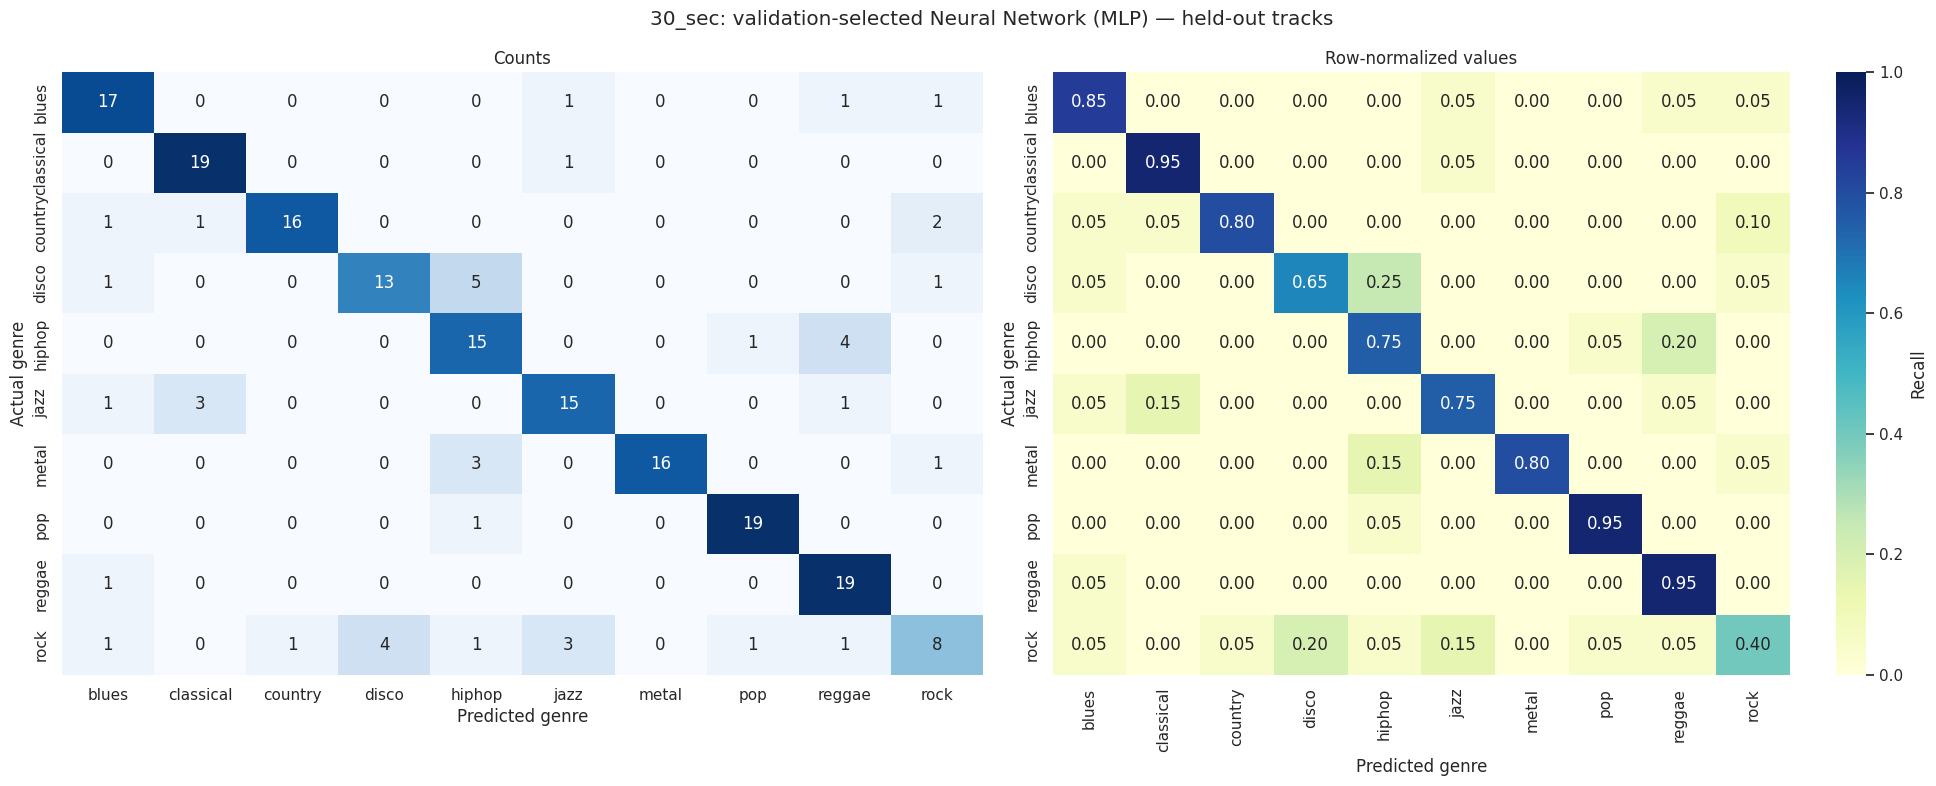

3_sec: validation fitting Logistic Regression
3_sec: validation fitting KNN
3_sec: validation fitting SVM (RBF)
3_sec: validation fitting Random Forest
3_sec: validation fitting Boosted Trees
3_sec: validation fitting Neural Network (MLP)
3_sec: validation fitting SVM (RBF, 15 selected features)
3_sec: validation fitting Logistic Regression (15 selected features)

3_sec selected by validation macro-F1: SVM (RBF)
3_sec: final test fitting Logistic Regression
3_sec: final test fitting KNN
3_sec: final test fitting SVM (RBF)
3_sec: final test fitting Random Forest
3_sec: final test fitting Boosted Trees
3_sec: final test fitting Neural Network (MLP)
3_sec: final test fitting SVM (RBF, 15 selected features)
3_sec: final test fitting Logistic Regression (15 selected features)


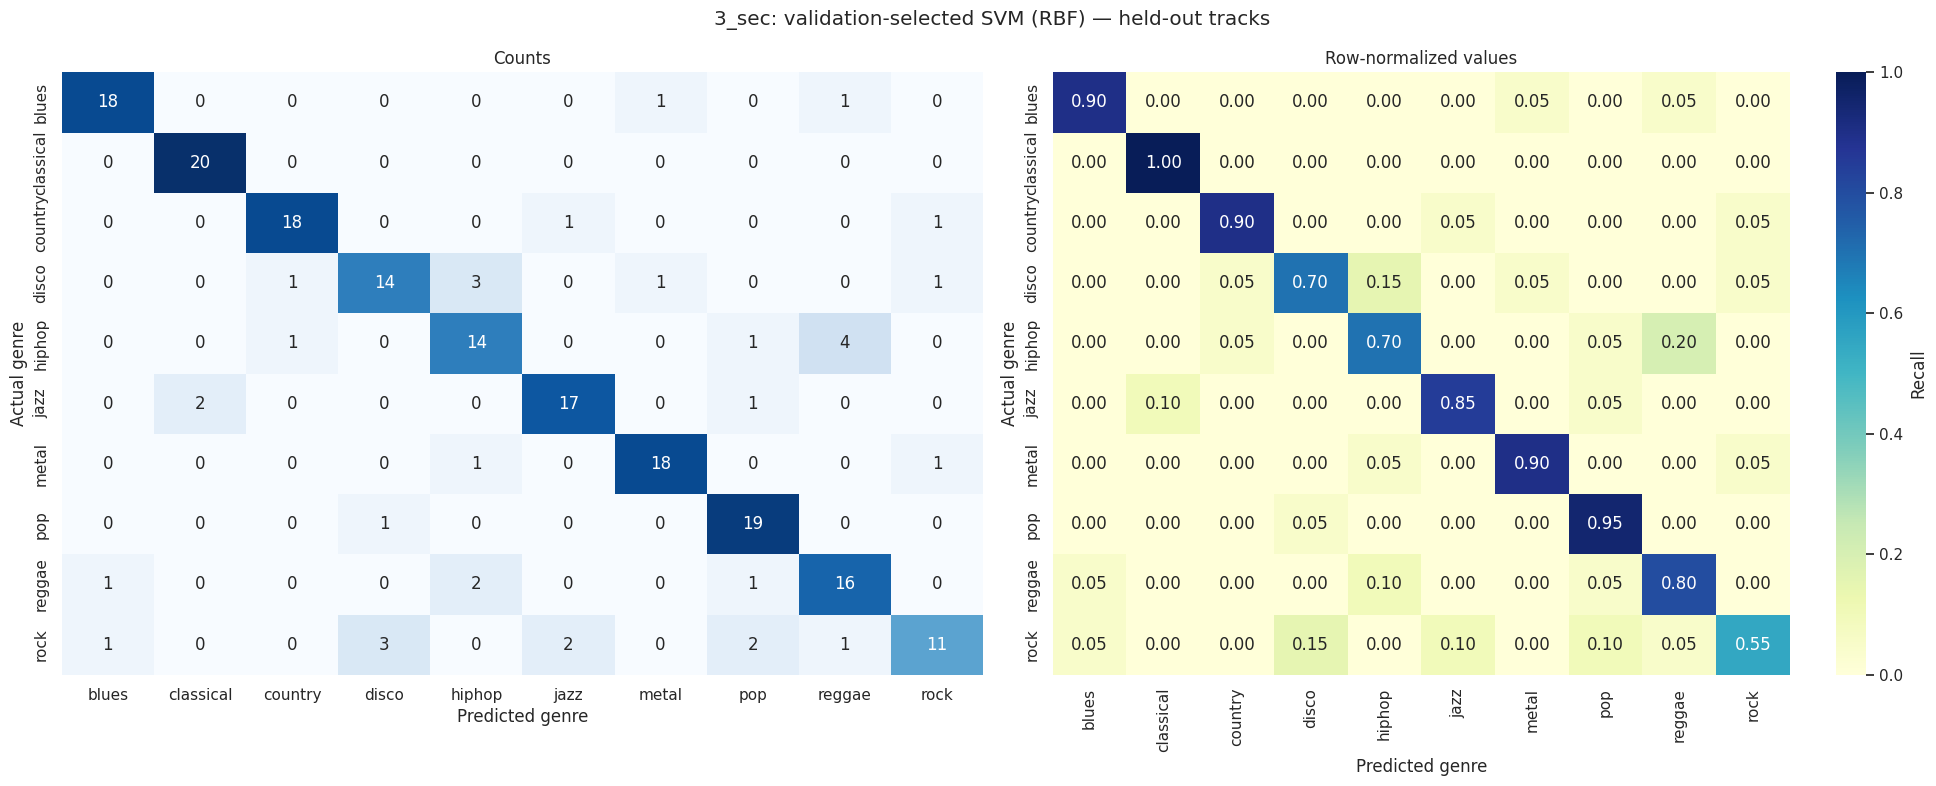


Validation model comparison (used to select each final model):


,dataset,model,accuracy,macro_f1,weighted_f1
0,30_sec,Neural Network (MLP),0.71875,0.720385,0.720385
1,30_sec,SVM (RBF),0.71875,0.718867,0.718867
2,30_sec,Boosted Trees,0.70625,0.707371,0.707371
3,30_sec,Random Forest,0.67500,0.674219,0.674219
4,30_sec,Logistic Regression,0.65000,0.655807,0.655807
5,30_sec,"SVM (RBF, 15 selected features)",0.63750,0.638913,0.638913
6,30_sec,KNN,0.60000,0.602016,0.602016
7,30_sec,Logistic Regression (15 selected features),0.59375,0.591526,0.591526
8,3_sec,SVM (RBF),0.80625,0.806001,0.806001
9,3_sec,Boosted Trees,0.78125,0.781823,0.781823



Held-out test comparison (track-level):


,dataset,model,selected_by_validation,accuracy,macro_f1,weighted_f1
3,30_sec,SVM (RBF),False,0.800,0.794155,0.794155
0,30_sec,Neural Network (MLP),True,0.785,0.780413,0.780413
5,30_sec,Boosted Trees,False,0.770,0.767348,0.767348
4,30_sec,Random Forest,False,0.755,0.747612,0.747612
1,30_sec,Logistic Regression,False,0.740,0.735709,0.735709
2,30_sec,KNN,False,0.730,0.727958,0.727958
6,30_sec,"SVM (RBF, 15 selected features)",False,0.720,0.710458,0.710458
7,30_sec,Logistic Regression (15 selected features),False,0.645,0.638482,0.638482
12,3_sec,Boosted Trees,False,0.840,0.836674,0.836674
13,3_sec,Neural Network (MLP),False,0.835,0.835921,0.835921


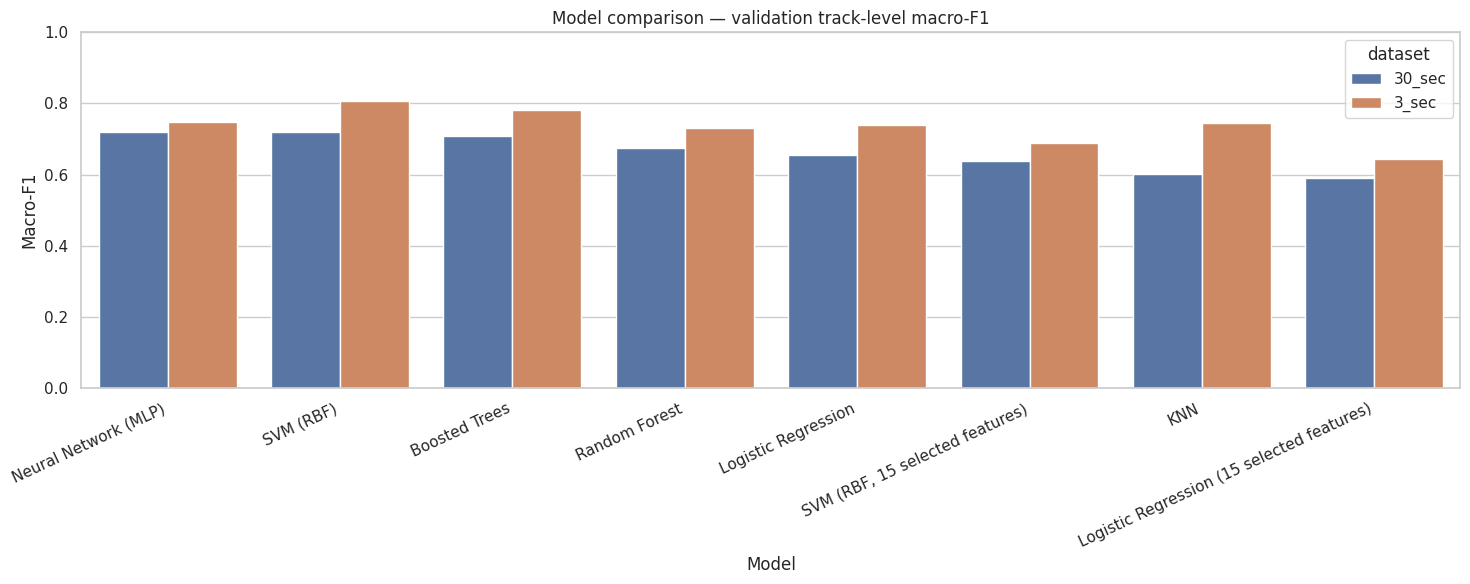

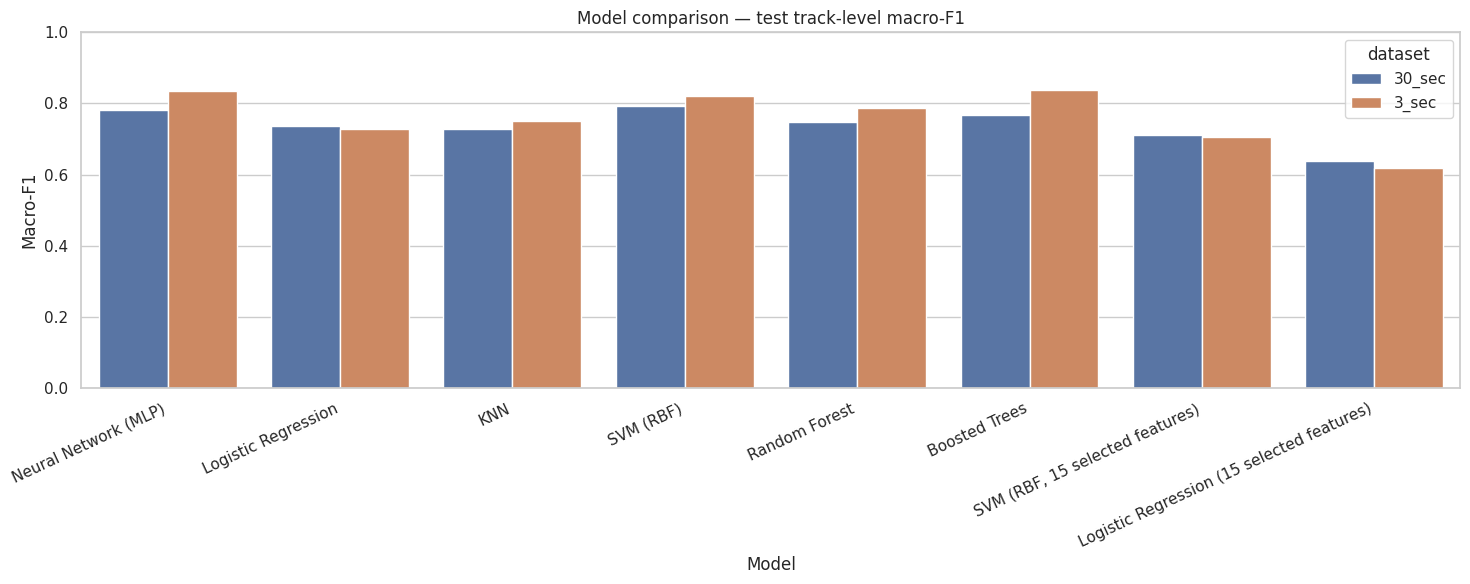


Part 2 complete. Results and trained models are in: /content/outputs/part2


In [ ]:
# PART 2 — Model comparison and track-level evaluation
#This part trains and compares machine-learning classifiers using audio features. It uses a track-level split so slices from the same original song do not appear in both training and test data. Validation results are used to select a model; the held-out test set is reserved for final evaluation.
# Run after Part 1 in the same Colab runtime.

from pathlib import Path
import sqlite3
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 409
DB_PATH = Path("/content/outputs/part1/music_genre.db")
OUTPUT_DIR = Path("/content/outputs/part2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {DB_PATH}. Run Part 1 first in this Colab runtime."
    )

# Load both datasets from the Part 1 SQLite database.
with sqlite3.connect(DB_PATH) as connection:
    data_30 = pd.read_sql_query("SELECT * FROM features_30_sec", connection)
    data_3 = pd.read_sql_query("SELECT * FROM features_3_sec", connection)

genre_labels = sorted(data_30["label"].astype(str).unique().tolist())
print("Genres:", genre_labels)
print("30-second rows:", len(data_30))
print("3-second rows:", len(data_3))
print("Original tracks:", data_30["track_id"].nunique())

# Split original tracks first, so slices from one song cannot leak across splits.
tracks = data_30[["track_id", "label"]].drop_duplicates("track_id")

trainval_tracks, test_tracks = train_test_split(
    tracks,
    test_size=0.20,
    random_state=SEED,
    stratify=tracks["label"],
)
train_tracks, validation_tracks = train_test_split(
    trainval_tracks,
    test_size=0.20,
    random_state=SEED,
    stratify=trainval_tracks["label"],
)

train_ids = set(train_tracks["track_id"].astype(str))
validation_ids = set(validation_tracks["track_id"].astype(str))
test_ids = set(test_tracks["track_id"].astype(str))
trainval_ids = train_ids | validation_ids

assert not (train_ids & validation_ids)
assert not (train_ids & test_ids)
assert not (validation_ids & test_ids)

print(
    f"\nTrack split: train={len(train_ids)}, "
    f"validation={len(validation_ids)}, test={len(test_ids)}"
)
print("No original track is shared across the splits.")

# Candidate models. Scaling is included for models that need it.
def create_models():
    return {
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("model", LogisticRegression(
                C=1.0, max_iter=2500, class_weight="balanced"
            )),
        ]),
        "KNN": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("model", KNeighborsClassifier(
                n_neighbors=11, weights="distance", p=2
            )),
        ]),
        "SVM (RBF)": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("model", SVC(
                C=3.0, kernel="rbf", probability=True,
                class_weight="balanced", random_state=SEED
            )),
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=250,
                min_samples_leaf=2,
                class_weight="balanced",
                n_jobs=-1,
                random_state=SEED,
            )),
        ]),
        "Boosted Trees": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", HistGradientBoostingClassifier(
                learning_rate=0.08,
                max_iter=160,
                max_leaf_nodes=20,
                l2_regularization=1.0,
                random_state=SEED,
            )),
        ]),
        "Neural Network (MLP)": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("model", MLPClassifier(
                hidden_layer_sizes=(128, 64),
                activation="relu",
                alpha=0.01,
                learning_rate_init=0.001,
                max_iter=180,
                random_state=SEED,
            )),
        ]),
        # Feature selection is fitted inside each model pipeline.
        "SVM (RBF, 15 selected features)": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("select", SelectKBest(score_func=f_classif, k=15)),
            ("model", SVC(
                C=3.0, kernel="rbf", probability=True,
                class_weight="balanced", random_state=SEED
            )),
        ]),
        "Logistic Regression (15 selected features)": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("select", SelectKBest(score_func=f_classif, k=15)),
            ("model", LogisticRegression(
                C=1.0, max_iter=2500, class_weight="balanced"
            )),
        ]),
    }


def get_rows_and_xy(data, track_ids, feature_names):
    rows = data[data["track_id"].astype(str).isin(track_ids)].copy()
    X = rows[feature_names].replace([np.inf, -np.inf], np.nan)
    y = rows["label"].astype(str)
    return rows, X, y


def predict_tracks(model, rows, X, labels):
    """Average 3-second segment probabilities to get one prediction per song."""
    probabilities = model.predict_proba(X)
    model_classes = list(model.classes_)

    probability_frame = pd.DataFrame(
        probabilities, columns=model_classes, index=rows.index
    ).reindex(columns=labels, fill_value=0.0)

    probability_frame["track_id"] = rows["track_id"].astype(str).values
    probability_frame["true_label"] = rows["label"].astype(str).values

    track_probabilities = probability_frame.groupby("track_id")[labels].mean()
    true_labels = (
        probability_frame.groupby("track_id")["true_label"]
        .first()
        .reindex(track_probabilities.index)
    )
    predicted_labels = track_probabilities.idxmax(axis=1)

    return true_labels.tolist(), predicted_labels.tolist(), track_probabilities


def score_predictions(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred, labels=genre_labels,
            average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true, y_pred, labels=genre_labels,
            average="weighted", zero_division=0
        ),
    }


def save_confusion_matrix(y_true, y_pred, duration, model_name):
    matrix = confusion_matrix(y_true, y_pred, labels=genre_labels)
    row_sums = matrix.sum(axis=1, keepdims=True)
    normalized = np.divide(
        matrix,
        row_sums,
        out=np.zeros_like(matrix, dtype=float),
        where=row_sums != 0,
    )

    fig, axes = plt.subplots(1, 2, figsize=(20, 8))

    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues",
        xticklabels=genre_labels, yticklabels=genre_labels,
        ax=axes[0], cbar=False,
    )
    axes[0].set_title("Counts")
    axes[0].set_xlabel("Predicted genre")
    axes[0].set_ylabel("Actual genre")

    sns.heatmap(
        normalized, annot=True, fmt=".2f", cmap="YlGnBu",
        xticklabels=genre_labels, yticklabels=genre_labels,
        vmin=0, vmax=1, ax=axes[1],
        cbar_kws={"label": "Recall"},
    )
    axes[1].set_title("Row-normalized values")
    axes[1].set_xlabel("Predicted genre")
    axes[1].set_ylabel("Actual genre")

    fig.suptitle(
        f"{duration}: validation-selected {model_name} — held-out tracks"
    )
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / f"{duration}_confusion_matrix.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


def save_confusion_reflection(y_true, y_pred, duration, model_name):
    matrix = confusion_matrix(y_true, y_pred, labels=genre_labels)
    errors = []

    for i, actual in enumerate(genre_labels):
        row_total = matrix[i].sum()
        if row_total == 0:
            continue
        for j, predicted in enumerate(genre_labels):
            if i != j and matrix[i, j] > 0:
                errors.append(
                    (matrix[i, j], matrix[i, j] / row_total, actual, predicted)
                )

    errors.sort(reverse=True)
    lines = [
        f"Confusion reflection — {duration}",
        f"Validation-selected model: {model_name}",
        "",
        "Most frequent errors (actual genre -> predicted genre):",
    ]

    if errors:
        for count, rate, actual, predicted in errors[:5]:
            lines.append(
                f"{actual} -> {predicted}: {count} tracks ({rate:.1%} "
                f"of held-out {actual} tracks)"
            )
    else:
        lines.append("No off-diagonal errors on this held-out split.")

    lines.extend([
        "",
        "Reflection note:",
        "Use the EDA plots to discuss whether overlapping timbre, chroma,",
        "spectral brightness, or tempo patterns could help explain these errors.",
        "Present that explanation as a hypothesis; the confusion matrix alone",
        "does not prove why two genres were confused.",
    ])

    (OUTPUT_DIR / f"{duration}_confusion_reflection.txt").write_text(
        "\n".join(lines), encoding="utf-8"
    )


# Fit each candidate on train tracks, select by validation macro-F1,
# then refit on train + validation tracks for the final held-out test.
all_validation_results = []
all_test_results = []

for data, duration in [(data_30, "30_sec"), (data_3, "3_sec")]:
    excluded = {"filename", "label", "track_id", "length"}
    feature_names = [
        col for col in data.select_dtypes(include="number").columns
        if col not in excluded
    ]

    train_rows, X_train, y_train = get_rows_and_xy(
        data, train_ids, feature_names
    )
    validation_rows, X_validation, _ = get_rows_and_xy(
        data, validation_ids, feature_names
    )
    trainval_rows, X_trainval, y_trainval = get_rows_and_xy(
        data, trainval_ids, feature_names
    )
    test_rows, X_test, _ = get_rows_and_xy(
        data, test_ids, feature_names
    )

    validation_scores = []
    for model_name, model in create_models().items():
        print(f"{duration}: validation fitting {model_name}")
        model.fit(X_train, y_train)
        y_val, pred_val, _ = predict_tracks(
            model, validation_rows, X_validation, genre_labels
        )
        validation_scores.append({
            "dataset": duration,
            "model": model_name,
            **score_predictions(y_val, pred_val),
        })

    validation_table = pd.DataFrame(validation_scores).sort_values(
        ["macro_f1", "accuracy"], ascending=False
    )
    best_model_name = validation_table.iloc[0]["model"]
    all_validation_results.append(validation_table)

    print(f"\n{duration} selected by validation macro-F1: {best_model_name}")

    test_scores = []
    fitted_models = {}

    for model_name, model in create_models().items():
        print(f"{duration}: final test fitting {model_name}")
        model.fit(X_trainval, y_trainval)

        y_test, pred_test, track_probabilities = predict_tracks(
            model, test_rows, X_test, genre_labels
        )

        test_scores.append({
            "dataset": duration,
            "model": model_name,
            "selected_by_validation": model_name == best_model_name,
            **score_predictions(y_test, pred_test),
        })
        fitted_models[model_name] = (
            model, y_test, pred_test, track_probabilities
        )

    test_table = pd.DataFrame(test_scores).sort_values(
        "selected_by_validation", ascending=False
    )
    all_test_results.append(test_table)

    # Produce the final confusion matrix/report using the model chosen on validation.
    best_model, y_test, pred_test, track_probabilities = fitted_models[best_model_name]

    save_confusion_matrix(y_test, pred_test, duration, best_model_name)
    save_confusion_reflection(y_test, pred_test, duration, best_model_name)

    report = classification_report(
        y_test, pred_test, labels=genre_labels,
        output_dict=True, zero_division=0
    )
    pd.DataFrame(report).transpose().to_csv(
        OUTPUT_DIR / f"{duration}_classification_report.csv"
    )
    (OUTPUT_DIR / f"{duration}_classification_report.txt").write_text(
        f"Dataset: {duration}\n"
        f"Selected using validation macro-F1: {best_model_name}\n\n"
        + classification_report(
            y_test, pred_test, labels=genre_labels, zero_division=0
        ),
        encoding="utf-8",
    )

    selected_features = feature_names
    if "select" in best_model.named_steps:
        selected_features = np.asarray(feature_names)[
            best_model.named_steps["select"].get_support()
        ].tolist()

    pd.DataFrame({"feature": selected_features}).to_csv(
        OUTPUT_DIR / f"{duration}_selected_model_features.csv",
        index=False,
    )

    # Save the trained model for Part 4's WAV upload classifier.
    joblib.dump(
        {
            "model": best_model,
            "features": feature_names,
            "selected_features": selected_features,
            "genres": genre_labels,
            "duration": duration,
            "selected_model": best_model_name,
        },
        OUTPUT_DIR / f"{duration}_best_model.joblib",
    )
    track_probabilities.to_csv(
        OUTPUT_DIR / f"{duration}_test_track_probabilities.csv"
    )

# Save the comparison tables.
validation_results = pd.concat(all_validation_results, ignore_index=True)
test_results = pd.concat(all_test_results, ignore_index=True)

validation_results.to_csv(
    OUTPUT_DIR / "validation_model_comparison.csv", index=False
)
test_results.to_csv(
    OUTPUT_DIR / "test_model_comparison.csv", index=False
)

print("\nValidation model comparison (used to select each final model):")
display(
    validation_results.sort_values(
        ["dataset", "macro_f1"], ascending=[True, False]
    )
)

print("\nHeld-out test comparison (track-level):")
display(
    test_results.sort_values(
        ["dataset", "macro_f1"], ascending=[True, False]
    )
)

# Plot macro-F1 comparison for validation and held-out test.
for phase, results_table in [
    ("validation", validation_results),
    ("test", test_results),
]:
    plt.figure(figsize=(15, 6))
    sns.barplot(
        data=results_table,
        x="model",
        y="macro_f1",
        hue="dataset",
    )
    plt.title(f"Model comparison — {phase} track-level macro-F1")
    plt.xlabel("Model")
    plt.ylabel("Macro-F1")
    plt.ylim(0, 1)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / f"model_comparison_{phase}_macro_f1.png",
        dpi=180,
    )
    plt.show()
    plt.close()

print(f"\nPart 2 complete. Results and trained models are in: {OUTPUT_DIR}")

Part 2.1: fitting 30_sec — Logistic Regression
Part 2.1: fitting 30_sec — KNN
Part 2.1: fitting 30_sec — SVM (RBF)
Part 2.1: fitting 30_sec — Random Forest
Part 2.1: fitting 30_sec — Boosted Trees
Part 2.1: fitting 30_sec — Neural Network (MLP)
Part 2.1: fitting 30_sec — SVM (RBF, 15 selected features)
Part 2.1: fitting 30_sec — Logistic Regression (15 selected features)


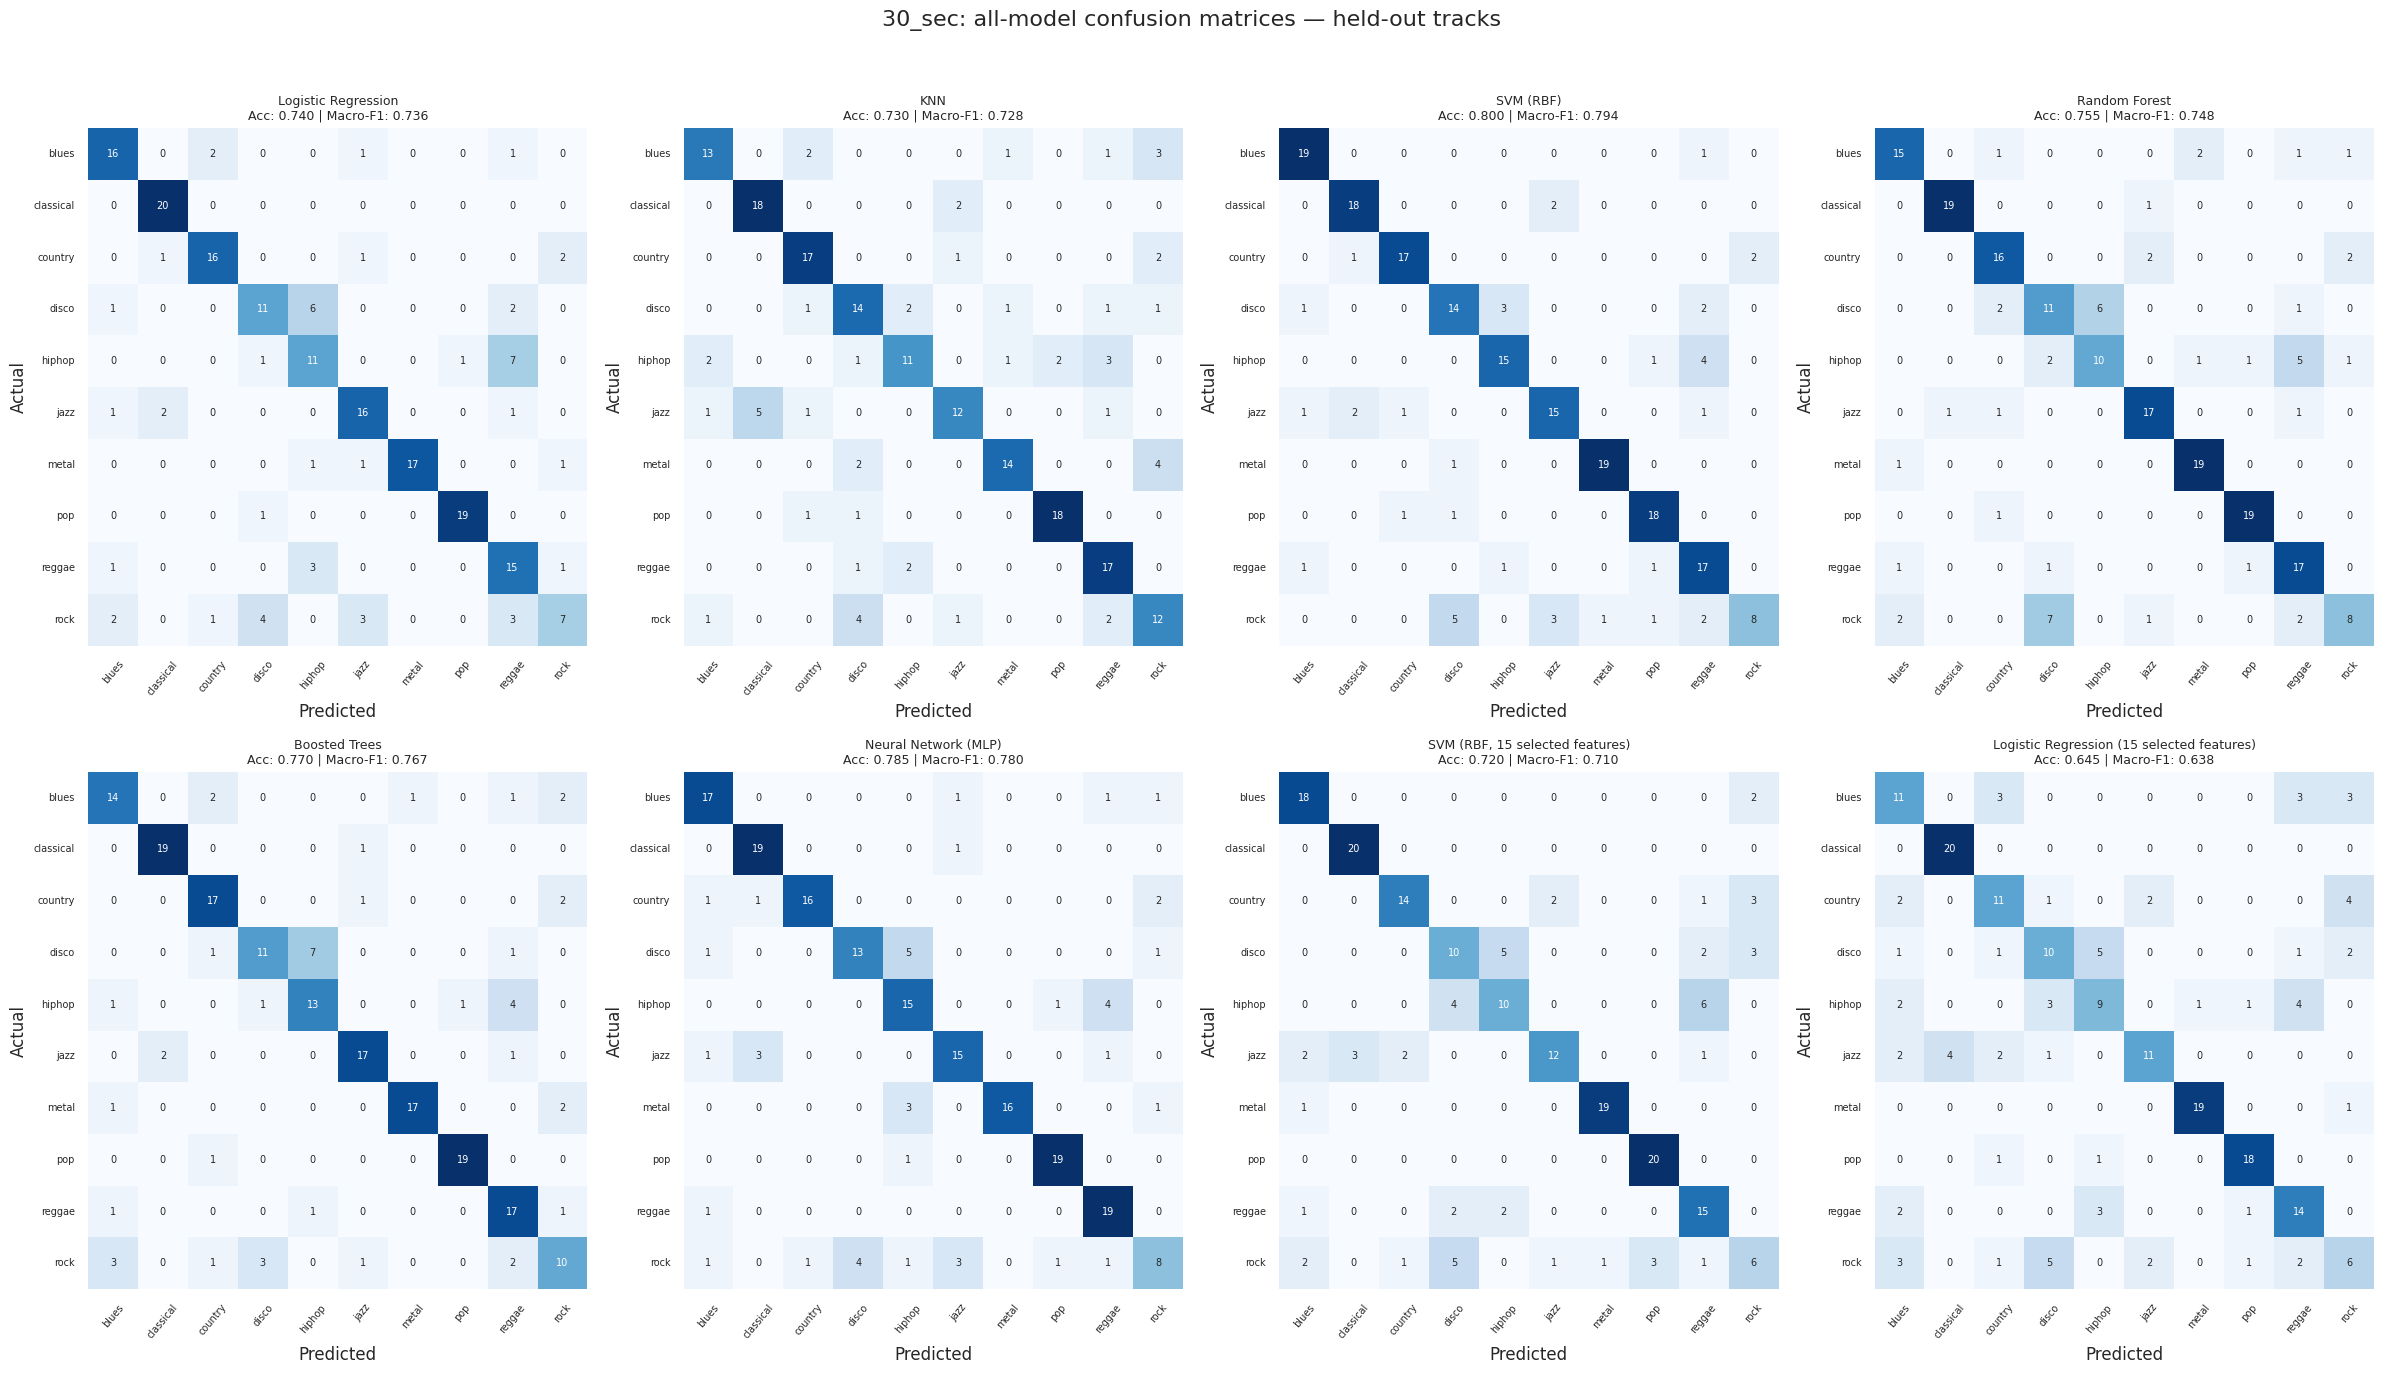

Part 2.1: fitting 3_sec — Logistic Regression
Part 2.1: fitting 3_sec — KNN
Part 2.1: fitting 3_sec — SVM (RBF)
Part 2.1: fitting 3_sec — Random Forest
Part 2.1: fitting 3_sec — Boosted Trees
Part 2.1: fitting 3_sec — Neural Network (MLP)
Part 2.1: fitting 3_sec — SVM (RBF, 15 selected features)
Part 2.1: fitting 3_sec — Logistic Regression (15 selected features)


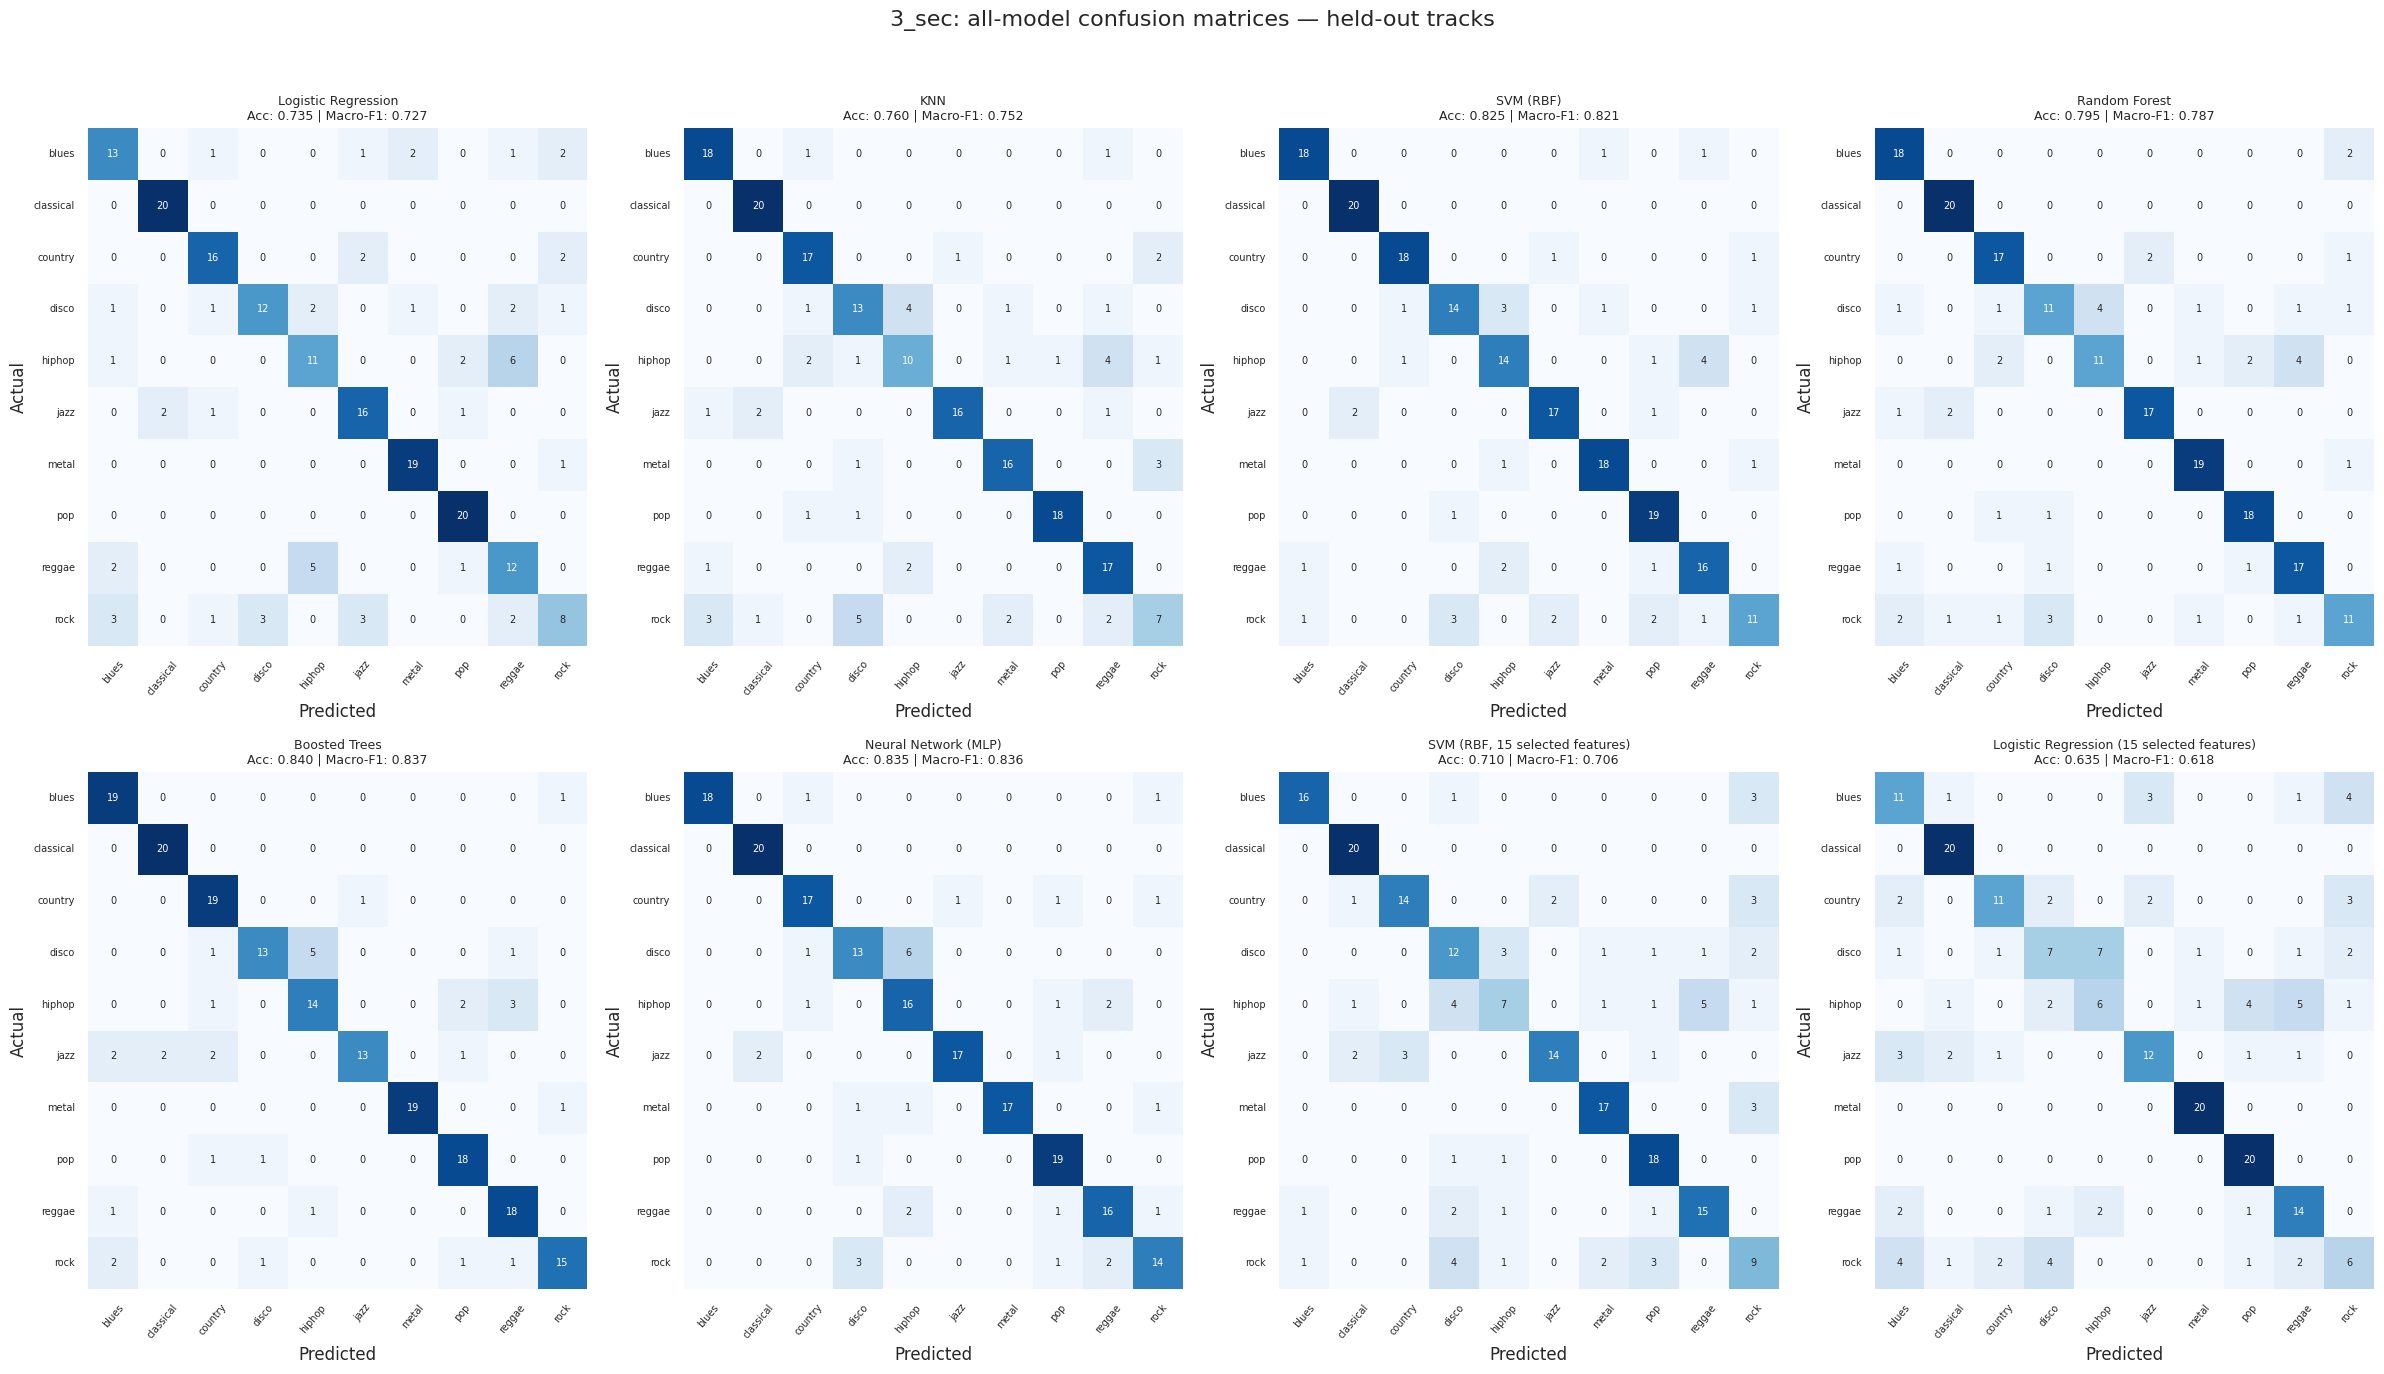


Part 2.1 held-out test comparison:


,dataset,model,accuracy,macro_f1,weighted_f1,held_out_tracks
2,30_sec,SVM (RBF),0.800,0.794155,0.794155,200
5,30_sec,Neural Network (MLP),0.785,0.780413,0.780413,200
4,30_sec,Boosted Trees,0.770,0.767348,0.767348,200
3,30_sec,Random Forest,0.755,0.747612,0.747612,200
0,30_sec,Logistic Regression,0.740,0.735709,0.735709,200
1,30_sec,KNN,0.730,0.727958,0.727958,200
6,30_sec,"SVM (RBF, 15 selected features)",0.720,0.710458,0.710458,200
7,30_sec,Logistic Regression (15 selected features),0.645,0.638482,0.638482,200
12,3_sec,Boosted Trees,0.840,0.836674,0.836674,200
13,3_sec,Neural Network (MLP),0.835,0.835921,0.835921,200


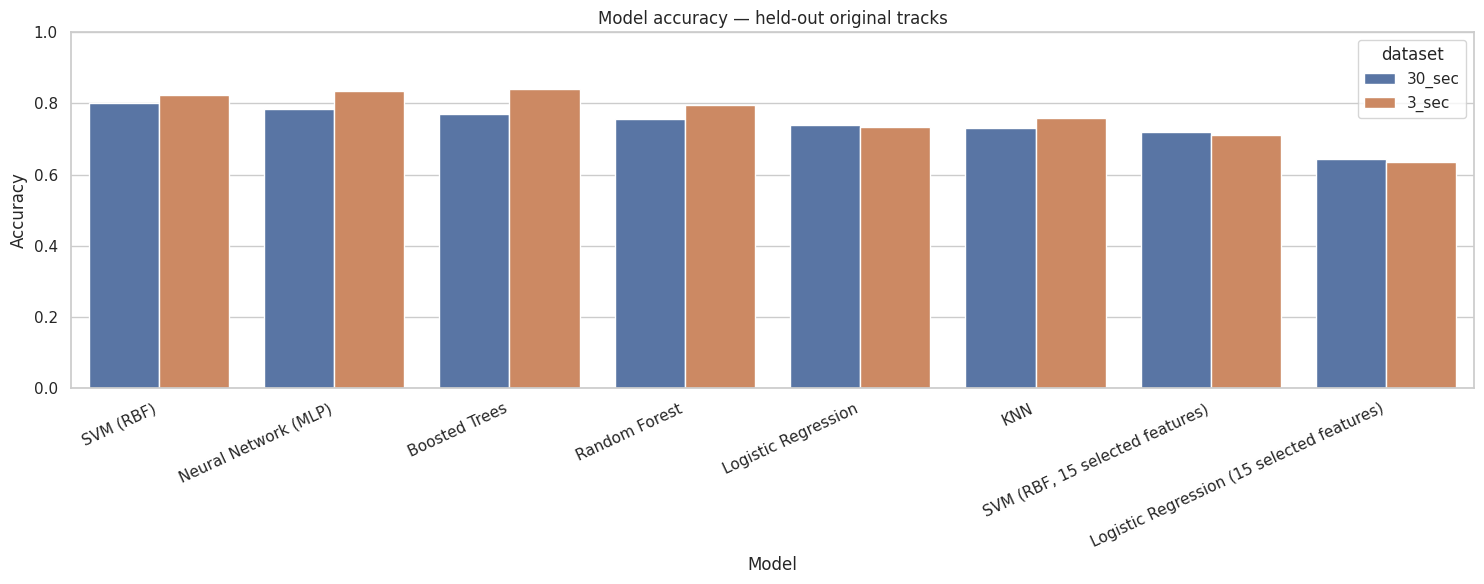

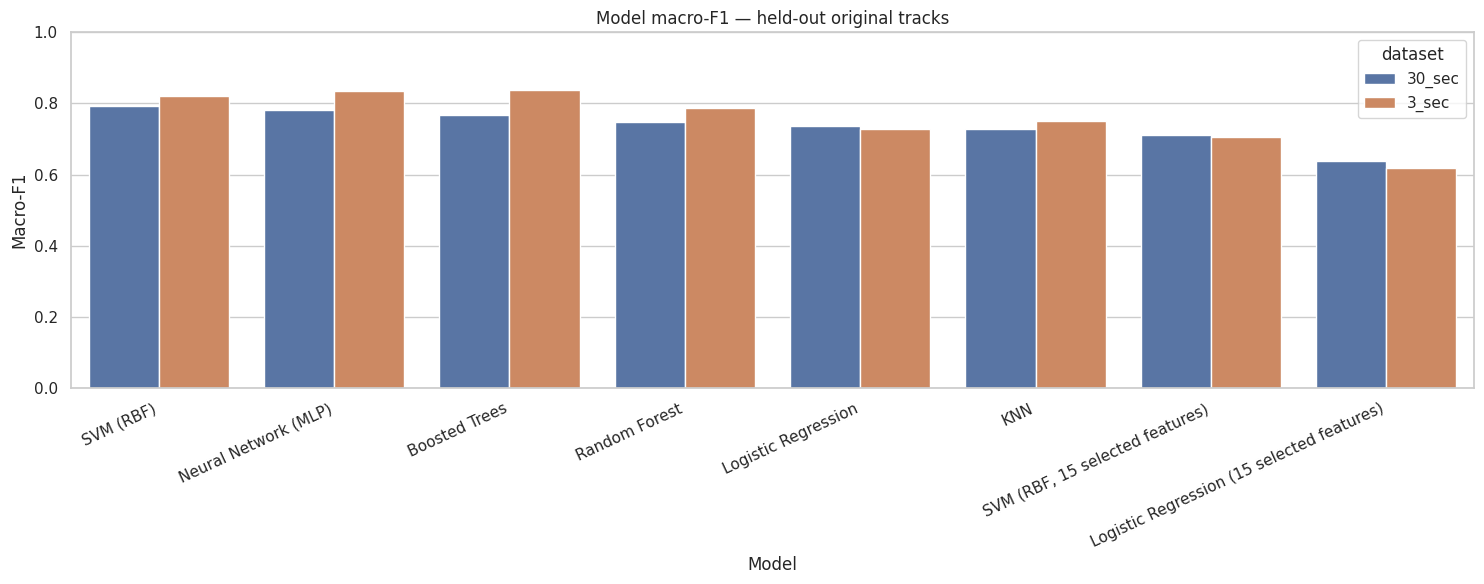


Part 2.1 complete. Files saved in: /content/outputs/part2_1


In [ ]:
# PART 2.1 — Detailed model comparison and confusion matrices
#This part compares model performance using accuracy, macro-F1, and confusion matrices. These results show both overall performance and which genres the models mix up.
# Run after Part 2 in the same Colab runtime.
# These test results are for comparison; do not use them to reselect the final model.

PART21_DIR = Path("/content/outputs/part2_1")
PART21_DIR.mkdir(parents=True, exist_ok=True)

detailed_results = []

for data, duration in [(data_30, "30_sec"), (data_3, "3_sec")]:
    excluded = {"filename", "label", "track_id", "length"}
    feature_names = [
        col for col in data.select_dtypes(include="number").columns
        if col not in excluded
    ]

    # Train on train + validation tracks; evaluate on the same held-out test tracks.
    _, X_trainval, y_trainval = get_rows_and_xy(
        data, trainval_ids, feature_names
    )
    test_rows, X_test, _ = get_rows_and_xy(
        data, test_ids, feature_names
    )

    models = create_models()
    model_names = list(models.keys())

    # Combined 2x4 figure for all eight models.
    fig, axes = plt.subplots(2, 4, figsize=(24, 14))
    axes = axes.flatten()

    for index, (model_name, model) in enumerate(models.items()):
        print(f"Part 2.1: fitting {duration} — {model_name}")
        model.fit(X_trainval, y_trainval)

        y_true, y_pred, _ = predict_tracks(
            model, test_rows, X_test, genre_labels
        )

        accuracy = accuracy_score(y_true, y_pred)
        macro_f1 = f1_score(
            y_true, y_pred,
            labels=genre_labels,
            average="macro",
            zero_division=0,
        )
        weighted_f1 = f1_score(
            y_true, y_pred,
            labels=genre_labels,
            average="weighted",
            zero_division=0,
        )

        detailed_results.append({
            "dataset": duration,
            "model": model_name,
            "accuracy": accuracy,
            "macro_f1": macro_f1,
            "weighted_f1": weighted_f1,
            "held_out_tracks": len(y_true),
        })

        # Save detailed precision, recall and F1 for each model.
        class_report = classification_report(
            y_true,
            y_pred,
            labels=genre_labels,
            output_dict=True,
            zero_division=0,
        )
        pd.DataFrame(class_report).transpose().to_csv(
            PART21_DIR / f"{duration}_{index + 1}_class_report.csv"
        )

        matrix = confusion_matrix(
            y_true, y_pred, labels=genre_labels
        )

        # Save an individual confusion matrix for this model.
        plt.figure(figsize=(9, 7))
        sns.heatmap(
            matrix,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=genre_labels,
            yticklabels=genre_labels,
        )
        plt.title(
            f"{duration} — {model_name}\n"
            f"Accuracy: {accuracy:.3f} | Macro-F1: {macro_f1:.3f}"
        )
        plt.xlabel("Predicted genre")
        plt.ylabel("Actual genre")
        plt.xticks(rotation=40, ha="right")
        plt.tight_layout()
        safe_name = (
            model_name.lower()
            .replace(" ", "_")
            .replace("(", "")
            .replace(")", "")
            .replace(",", "")
        )
        plt.savefig(
            PART21_DIR / f"{duration}_{safe_name}_confusion_matrix.png",
            dpi=180,
            bbox_inches="tight",
        )
        plt.close()

        # Add the same matrix to the combined figure.
        sns.heatmap(
            matrix,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=genre_labels,
            yticklabels=genre_labels,
            cbar=False,
            annot_kws={"size": 7},
            ax=axes[index],
        )
        axes[index].set_title(
            f"{model_name}\nAcc: {accuracy:.3f} | Macro-F1: {macro_f1:.3f}",
            fontsize=9,
        )
        axes[index].set_xlabel("Predicted")
        axes[index].set_ylabel("Actual")
        axes[index].tick_params(axis="x", rotation=50, labelsize=7)
        axes[index].tick_params(axis="y", rotation=0, labelsize=7)

    fig.suptitle(
        f"{duration}: all-model confusion matrices — held-out tracks",
        fontsize=16,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(
        PART21_DIR / f"{duration}_all_model_confusion_matrices.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

# Save and display the model metrics table.
results_21 = pd.DataFrame(detailed_results).sort_values(
    ["dataset", "macro_f1"], ascending=[True, False]
)
results_21.to_csv(PART21_DIR / "all_model_metrics.csv", index=False)

print("\nPart 2.1 held-out test comparison:")
display(results_21)

# Accuracy chart.
plt.figure(figsize=(15, 6))
sns.barplot(data=results_21, x="model", y="accuracy", hue="dataset")
plt.title("Model accuracy — held-out original tracks")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(PART21_DIR / "model_accuracy_comparison.png", dpi=180)
plt.show()
plt.close()

# Macro-F1 chart.
plt.figure(figsize=(15, 6))
sns.barplot(data=results_21, x="model", y="macro_f1", hue="dataset")
plt.title("Model macro-F1 — held-out original tracks")
plt.xlabel("Model")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(PART21_DIR / "model_macro_f1_comparison.png", dpi=180)
plt.show()
plt.close()

print(f"\nPart 2.1 complete. Files saved in: {PART21_DIR}")

Most influential features for the saved 30-second model:


,feature,mean_macro_f1_drop,std_macro_f1_drop
23,mfcc4_mean,0.063568,0.011640
0,chroma_stft_mean,0.057648,0.014563
15,perceptr_var,0.052870,0.014759
33,mfcc9_mean,0.049129,0.019033
37,mfcc11_mean,0.044801,0.016473
3,rms_var,0.040033,0.011411
9,rolloff_var,0.039899,0.009982
45,mfcc15_mean,0.033630,0.014145
36,mfcc10_var,0.028211,0.013292
14,perceptr_mean,0.027496,0.006941


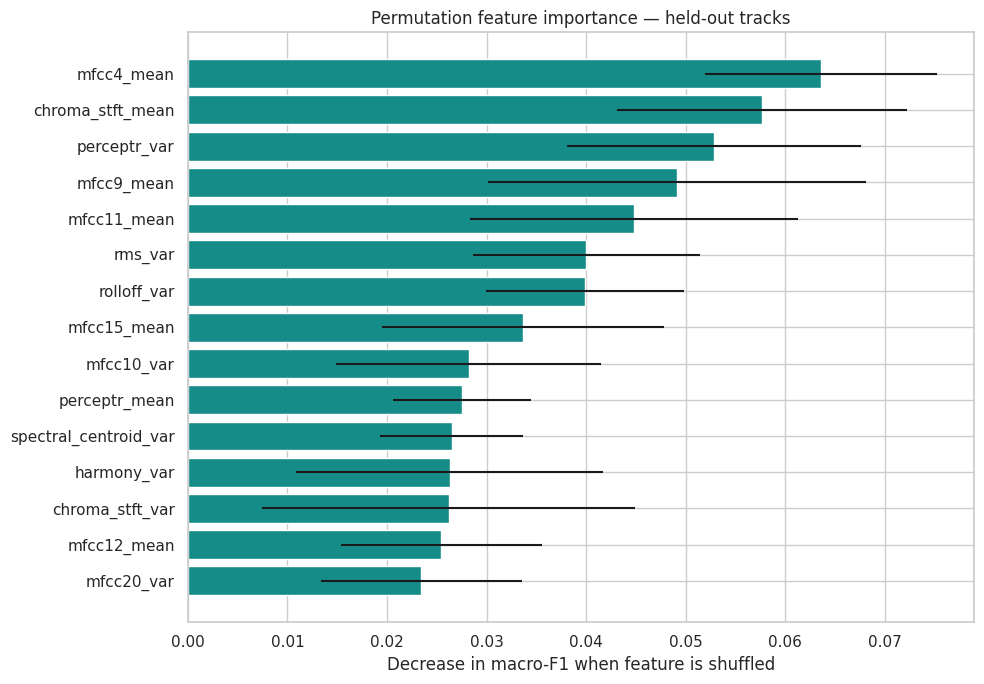

Saved chart and table in: /content/outputs/part2_2


In [ ]:
# PART 2.2 — Which audio features matter most?
#This part estimates how much each audio feature contributes to the selected model’s predictions. It helps identify which measured audio characteristics may be useful for distinguishing genres.
# Run after Part 2 in the same Colab runtime.

from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

MODEL_PATH = Path("/content/outputs/part2/30_sec_best_model.joblib")
OUTPUT_DIR = Path("/content/outputs/part2_2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not MODEL_PATH.exists():
    raise FileNotFoundError("Run Part 2 first; the saved 30-second model was not found.")

model_bundle = joblib.load(MODEL_PATH)
model = model_bundle["model"]
feature_names = list(model_bundle["features"])

# Recreate Part 2's held-out track split.
tracks = data_30[["track_id", "label"]].drop_duplicates("track_id")
_, test_tracks = train_test_split(
    tracks,
    test_size=0.20,
    random_state=SEED,
    stratify=tracks["label"],
)
test_ids = set(test_tracks["track_id"].astype(str))

test_rows = data_30[
    data_30["track_id"].astype(str).isin(test_ids)
].copy()

X_test = test_rows[feature_names].replace([np.inf, -np.inf], np.nan)
y_test = test_rows["label"].astype(str)

# Measure the drop in macro-F1 when each feature is shuffled.
importance = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=20,
    random_state=SEED,
    n_jobs=-1,
)

importance_table = pd.DataFrame({
    "feature": feature_names,
    "mean_macro_f1_drop": importance.importances_mean,
    "std_macro_f1_drop": importance.importances_std,
}).sort_values("mean_macro_f1_drop", ascending=False)

importance_table.to_csv(
    OUTPUT_DIR / "permutation_feature_importance.csv",
    index=False,
)

print("Most influential features for the saved 30-second model:")
display(importance_table.head(15))

# Plot the top 15 features.
top = importance_table.head(15).sort_values("mean_macro_f1_drop")

plt.figure(figsize=(10, 7))
plt.barh(
    top["feature"],
    top["mean_macro_f1_drop"],
    xerr=top["std_macro_f1_drop"],
    color="#168c88",
)
plt.xlabel("Decrease in macro-F1 when feature is shuffled")
plt.title("Permutation feature importance — held-out tracks")
plt.tight_layout()

chart_path = OUTPUT_DIR / "permutation_feature_importance.png"
plt.savefig(chart_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close()

print(f"Saved chart and table in: {OUTPUT_DIR}")

Majority-class baseline:


,dataset,model,accuracy,macro_f1,weighted_f1,held_out_tracks
0,30_sec,Majority-class baseline,0.1,0.018182,0.018182,200
1,3_sec,Majority-class baseline,0.1,0.018182,0.018182,200


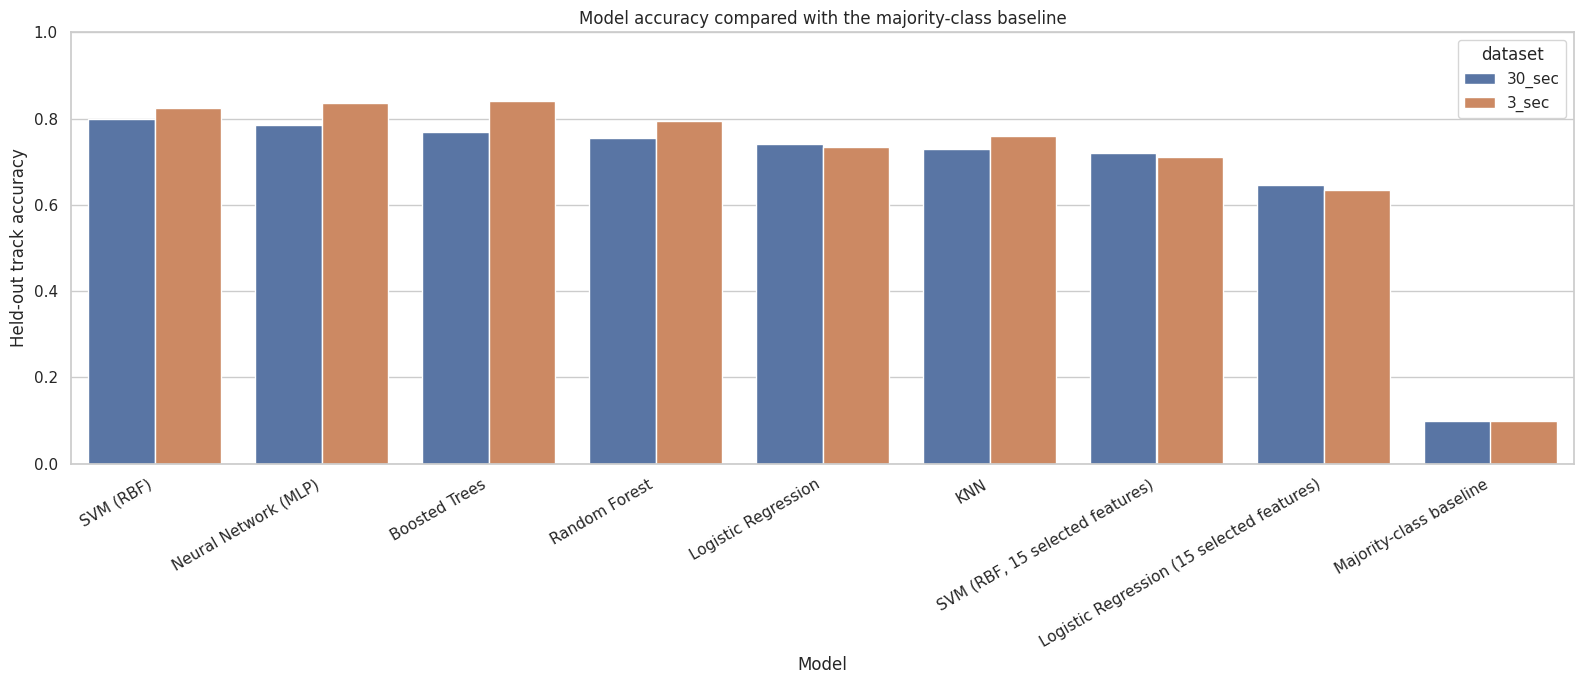

Saved baseline comparison in: /content/outputs/part2_3


In [ ]:
# Part 2.3 — Compare the models with a simple majority-class baseline.
#This part compares the trained models with a simple baseline that always predicts the most common genre. It checks whether the models learn useful patterns beyond that basic strategy.
# Run after Part 2.1 in the same Colab runtime.

from pathlib import Path
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

BASELINE_DIR = Path("/content/outputs/part2_3")
BASELINE_DIR.mkdir(parents=True, exist_ok=True)

baseline_rows = []

for data, duration in [(data_30, "30_sec"), (data_3, "3_sec")]:
    # Count each original song once, even in the 3-second dataset.
    train_tracks = (
        data[data["track_id"].astype(str).isin(trainval_ids)]
        [["track_id", "label"]]
        .drop_duplicates("track_id")
    )
    majority_genre = (
        train_tracks["label"].value_counts().sort_index().idxmax()
    )

    test_tracks = (
        data[data["track_id"].astype(str).isin(test_ids)]
        [["track_id", "label"]]
        .drop_duplicates("track_id")
    )
    y_true = test_tracks["label"].astype(str).tolist()
    y_pred = [majority_genre] * len(y_true)

    baseline_rows.append({
        "dataset": duration,
        "model": "Majority-class baseline",
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred,
            labels=genre_labels,
            average="macro",
            zero_division=0,
        ),
        "weighted_f1": f1_score(
            y_true, y_pred,
            labels=genre_labels,
            average="weighted",
            zero_division=0,
        ),
        "held_out_tracks": len(y_true),
    })

baseline = pd.DataFrame(baseline_rows)
baseline.to_csv(BASELINE_DIR / "majority_baseline_metrics.csv", index=False)

# Combine the baseline with the Part 2.1 model comparison.
combined_results = pd.concat(
    [results_21, baseline],
    ignore_index=True,
)
combined_results.to_csv(
    BASELINE_DIR / "models_vs_baseline.csv",
    index=False,
)

print("Majority-class baseline:")
display(baseline)

# Chart comparing every model with the baseline.
plt.figure(figsize=(16, 7))
sns.barplot(
    data=combined_results,
    x="model",
    y="accuracy",
    hue="dataset",
)
plt.title("Model accuracy compared with the majority-class baseline")
plt.xlabel("Model")
plt.ylabel("Held-out track accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(
    BASELINE_DIR / "models_vs_baseline_accuracy.png",
    dpi=180,
)
plt.show()
plt.close()

print(f"Saved baseline comparison in: {BASELINE_DIR}")

,fraction,training_tracks,train_f1_mean,train_f1_std,validation_f1_mean,validation_f1_std
0,0.10,64,1.000000,0.0,0.494201,0.044525
1,0.25,160,1.000000,0.0,0.606983,0.005071
2,0.50,320,1.000000,0.0,0.639726,0.005639
3,0.75,480,0.997916,0.0,0.658654,0.012799
4,1.00,640,0.998437,0.0,0.720385,0.000000


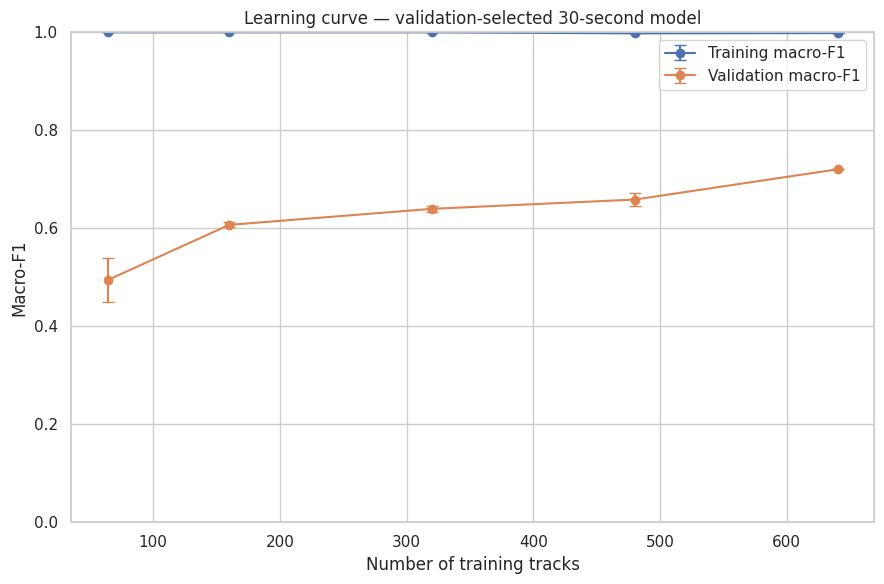

Most frequent directed confusion: disco predicted as hiphop (5 held-out track(s)).


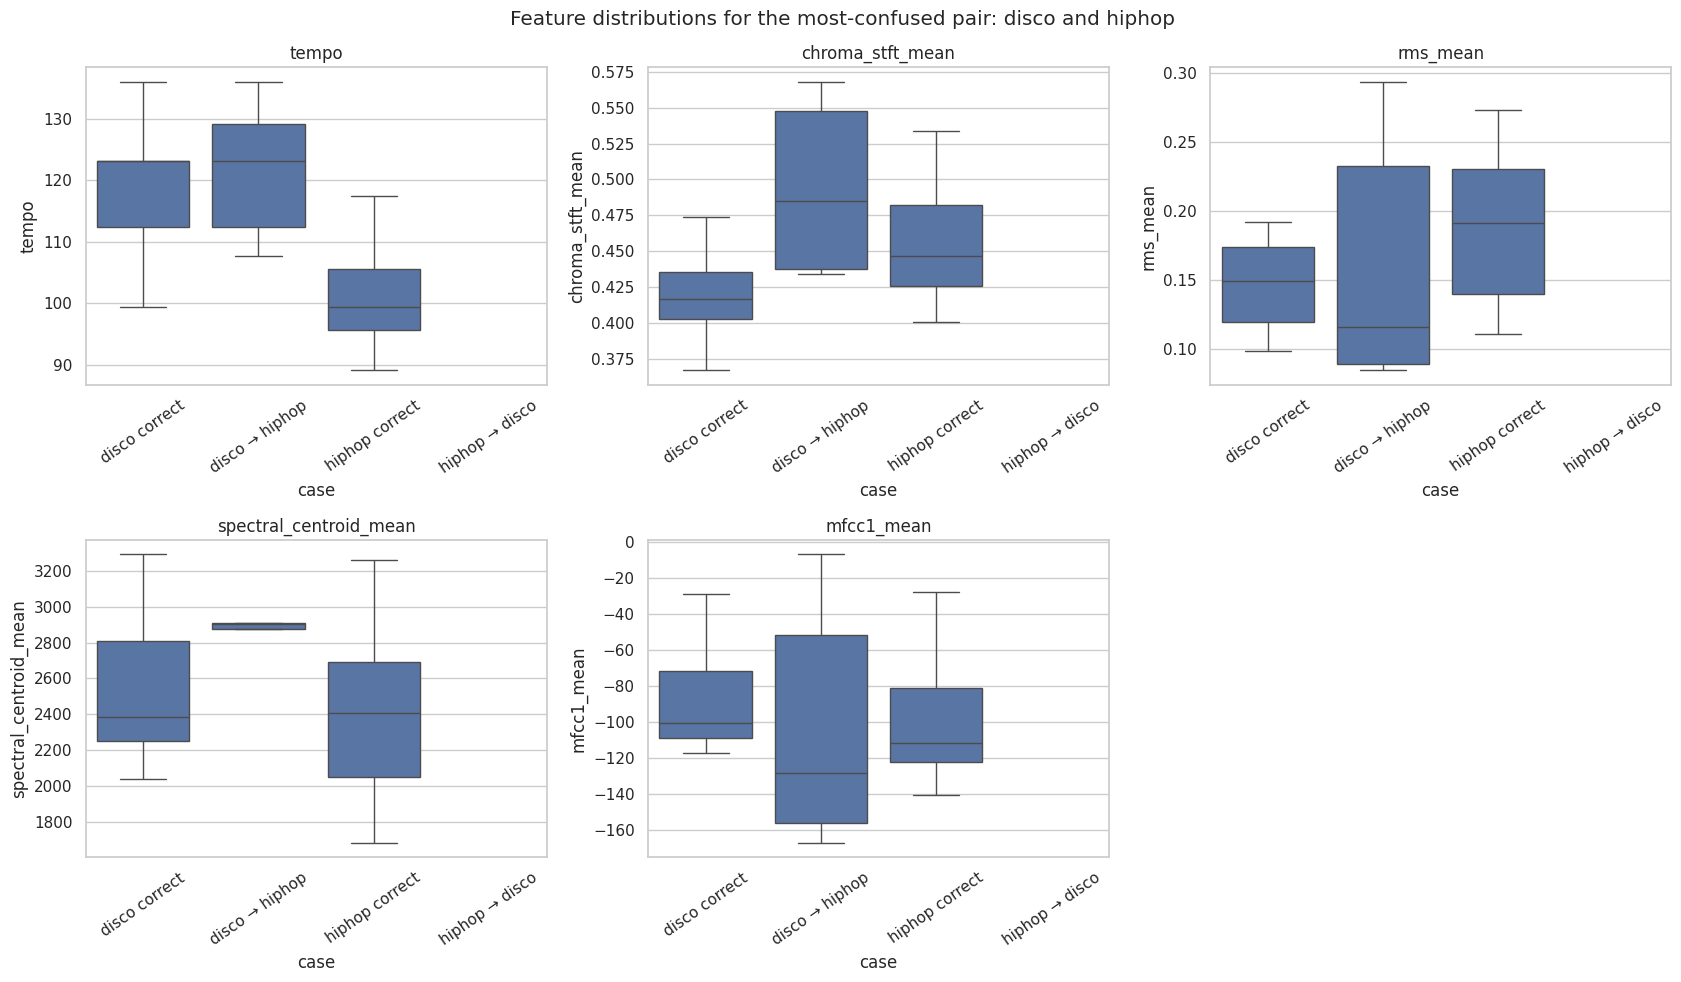

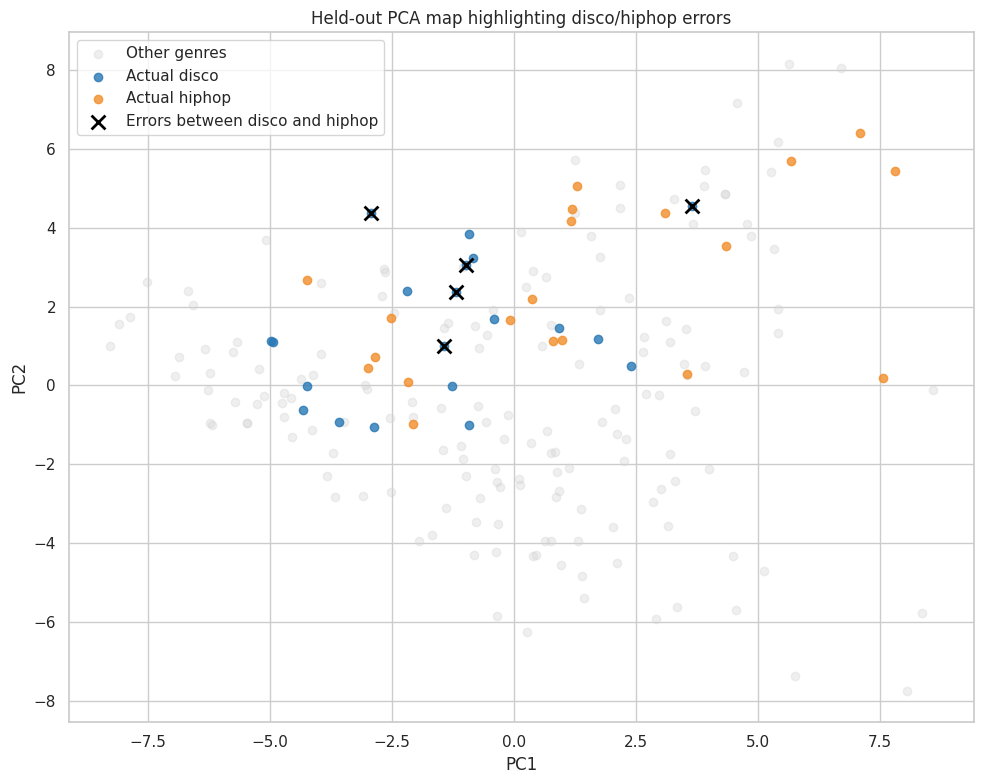


Part 2.4 outputs saved in: /content/outputs/part2_4


In [ ]:
# PART 2.4 — Learning curve and confused-genre analysis
#This part examines model performance as the amount of training data increases and investigates commonly confused genres. It helps show whether more training data may help and where the model’s mistakes occur.
# Run after Parts 2 and 2.1 in the same Colab runtime.

from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

PART24_DIR = Path("/content/outputs/part2_4")
PART24_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = Path("/content/outputs/part2/30_sec_best_model.joblib")
if not MODEL_PATH.exists():
    raise FileNotFoundError("Run Part 2 first; its 30-second model was not found.")

model_bundle = joblib.load(MODEL_PATH)
best_model = model_bundle["model"]
feature_names = list(model_bundle["features"])

# The notebook should still have these variables from Part 2.
if "data_30" not in globals() or "train_ids" not in globals() or "validation_ids" not in globals():
    raise NameError("Run Part 2 first in this Colab runtime so its data and track splits are available.")

# -------------------------------
# A. Learning curve
# -------------------------------
# Train on progressively larger, genre-stratified subsets of the training tracks.
# Score on the same validation tracks each time.

train_meta = (
    data_30[data_30["track_id"].astype(str).isin(train_ids)]
    [["track_id", "label"]]
    .drop_duplicates("track_id")
)

validation_rows = data_30[
    data_30["track_id"].astype(str).isin(validation_ids)
].copy()

X_validation = validation_rows[feature_names].replace([np.inf, -np.inf], np.nan)
y_validation = validation_rows["label"].astype(str)

fractions = [0.10, 0.25, 0.50, 0.75, 1.00]
repeats = 3
learning_rows = []

for fraction in fractions:
    for repeat in range(repeats):
        if fraction == 1.0:
            subset_meta = train_meta.copy()
        else:
            subset_meta, _ = train_test_split(
                train_meta,
                train_size=fraction,
                random_state=SEED + repeat + int(fraction * 100),
                stratify=train_meta["label"],
            )

        subset_ids = set(subset_meta["track_id"].astype(str))
        subset_rows = data_30[
            data_30["track_id"].astype(str).isin(subset_ids)
        ].copy()

        X_subset = subset_rows[feature_names].replace(
            [np.inf, -np.inf], np.nan
        )
        y_subset = subset_rows["label"].astype(str)

        learning_model = clone(best_model)
        learning_model.fit(X_subset, y_subset)

        train_predictions = learning_model.predict(X_subset)
        validation_predictions = learning_model.predict(X_validation)

        learning_rows.append({
            "fraction": fraction,
            "training_tracks": len(subset_meta),
            "repeat": repeat + 1,
            "train_macro_f1": f1_score(
                y_subset, train_predictions,
                labels=genre_labels,
                average="macro",
                zero_division=0,
            ),
            "validation_macro_f1": f1_score(
                y_validation, validation_predictions,
                labels=genre_labels,
                average="macro",
                zero_division=0,
            ),
        })

learning_results = pd.DataFrame(learning_rows)
learning_results.to_csv(
    PART24_DIR / "learning_curve_results.csv",
    index=False,
)

learning_summary = (
    learning_results.groupby(["fraction", "training_tracks"])
    .agg(
        train_f1_mean=("train_macro_f1", "mean"),
        train_f1_std=("train_macro_f1", "std"),
        validation_f1_mean=("validation_macro_f1", "mean"),
        validation_f1_std=("validation_macro_f1", "std"),
    )
    .reset_index()
    .fillna(0)
)

display(learning_summary)

plt.figure(figsize=(9, 6))
plt.errorbar(
    learning_summary["training_tracks"],
    learning_summary["train_f1_mean"],
    yerr=learning_summary["train_f1_std"],
    marker="o",
    capsize=4,
    label="Training macro-F1",
)
plt.errorbar(
    learning_summary["training_tracks"],
    learning_summary["validation_f1_mean"],
    yerr=learning_summary["validation_f1_std"],
    marker="o",
    capsize=4,
    label="Validation macro-F1",
)
plt.xlabel("Number of training tracks")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.title("Learning curve — validation-selected 30-second model")
plt.legend()
plt.tight_layout()
plt.savefig(
    PART24_DIR / "learning_curve.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()
plt.close()

# -------------------------------
# B. Investigate the most-confused genre pair
# -------------------------------
# This uses the untouched held-out tracks for diagnosis after model selection.

if "test_ids" not in globals():
    raise NameError("Part 2's test_ids are missing. Run Part 2 again first.")

test_rows = data_30[
    data_30["track_id"].astype(str).isin(test_ids)
].copy()

X_test = test_rows[feature_names].replace([np.inf, -np.inf], np.nan)
actual = test_rows["label"].astype(str).to_numpy()
predicted = best_model.predict(X_test)

matrix = confusion_matrix(actual, predicted, labels=genre_labels)
off_diagonal = matrix.copy()
np.fill_diagonal(off_diagonal, 0)

if off_diagonal.max() == 0:
    print("There are no misclassified test tracks to investigate.")
else:
    actual_index, predicted_index = np.unravel_index(
        np.argmax(off_diagonal), off_diagonal.shape
    )
    genre_a = genre_labels[actual_index]
    genre_b = genre_labels[predicted_index]
    error_count = int(off_diagonal[actual_index, predicted_index])

    print(
        f"Most frequent directed confusion: {genre_a} predicted as {genre_b} "
        f"({error_count} held-out track(s))."
    )

    pair_data = test_rows.copy()
    pair_data["actual_genre"] = actual
    pair_data["predicted_genre"] = predicted

    cases = [
        (pair_data["actual_genre"] == genre_a) &
        (pair_data["predicted_genre"] == genre_a),
        (pair_data["actual_genre"] == genre_a) &
        (pair_data["predicted_genre"] == genre_b),
        (pair_data["actual_genre"] == genre_b) &
        (pair_data["predicted_genre"] == genre_b),
        (pair_data["actual_genre"] == genre_b) &
        (pair_data["predicted_genre"] == genre_a),
    ]
    case_names = [
        f"{genre_a} correct",
        f"{genre_a} → {genre_b}",
        f"{genre_b} correct",
        f"{genre_b} → {genre_a}",
    ]

    pair_data["case"] = np.select(cases, case_names, default="Other")
    pair_data = pair_data[pair_data["case"] != "Other"].copy()

    pair_data.groupby("case")[
        [c for c in [
            "tempo",
            "chroma_stft_mean",
            "rms_mean",
            "spectral_centroid_mean",
            "mfcc1_mean",
        ] if c in pair_data.columns]
    ].mean().to_csv(PART24_DIR / "confused_pair_feature_means.csv")

    plot_features = [
        c for c in [
            "tempo",
            "chroma_stft_mean",
            "rms_mean",
            "spectral_centroid_mean",
            "mfcc1_mean",
        ]
        if c in pair_data.columns
    ]

    fig, axes = plt.subplots(2, 3, figsize=(17, 10))
    axes = axes.flatten()

    for ax, feature in zip(axes, plot_features):
        sns.boxplot(
            data=pair_data,
            x="case",
            y=feature,
            order=case_names,
            ax=ax,
            showfliers=False,
        )
        ax.set_title(f"{feature}")
        ax.tick_params(axis="x", rotation=35)

    for ax in axes[len(plot_features):]:
        ax.axis("off")

    fig.suptitle(
        f"Feature distributions for the most-confused pair: {genre_a} and {genre_b}"
    )
    fig.tight_layout()
    fig.savefig(
        PART24_DIR / "confused_pair_feature_distributions.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    # PCA map: fit scaling and PCA on training tracks, then project test tracks.
    train_rows = data_30[
        data_30["track_id"].astype(str).isin(train_ids)
    ].copy()
    X_train = train_rows[feature_names].replace([np.inf, -np.inf], np.nan)

    map_scaler = StandardScaler()
    X_train_scaled = map_scaler.fit_transform(X_train)
    X_test_scaled = map_scaler.transform(X_test)

    map_pca = PCA(n_components=2, random_state=SEED)
    map_pca.fit(X_train_scaled)
    test_coordinates = map_pca.transform(X_test_scaled)

    map_data = pd.DataFrame({
        "PC1": test_coordinates[:, 0],
        "PC2": test_coordinates[:, 1],
        "actual_genre": actual,
        "predicted_genre": predicted,
    })

    pair_error = (
        ((map_data["actual_genre"] == genre_a) &
         (map_data["predicted_genre"] == genre_b)) |
        ((map_data["actual_genre"] == genre_b) &
         (map_data["predicted_genre"] == genre_a))
    )

    plt.figure(figsize=(10, 8))
    plt.scatter(
        map_data.loc[~map_data["actual_genre"].isin([genre_a, genre_b]), "PC1"],
        map_data.loc[~map_data["actual_genre"].isin([genre_a, genre_b]), "PC2"],
        color="lightgray",
        alpha=0.35,
        label="Other genres",
    )

    for genre, color in [(genre_a, "#2878B5"), (genre_b, "#F28E2B")]:
        mask = map_data["actual_genre"] == genre
        plt.scatter(
            map_data.loc[mask, "PC1"],
            map_data.loc[mask, "PC2"],
            color=color,
            alpha=0.8,
            label=f"Actual {genre}",
        )

    plt.scatter(
        map_data.loc[pair_error, "PC1"],
        map_data.loc[pair_error, "PC2"],
        marker="x",
        s=100,
        linewidths=2,
        color="black",
        label=f"Errors between {genre_a} and {genre_b}",
    )

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(f"Held-out PCA map highlighting {genre_a}/{genre_b} errors")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        PART24_DIR / "confused_pair_pca_map.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

print(f"\nPart 2.4 outputs saved in: {PART24_DIR}")

In [ ]:
# PART 2.5 — CNN using mel-spectrograms
#This optional part trains a convolutional neural network using spectrograms made from audio recordings. It provides a comparison with models trained on pre-extracted features and requires the actual audio files.
# Upload a ZIP of the full WAV dataset, not a features CSV ZIP.

import os
import zipfile
import tempfile
from pathlib import Path

import numpy as np
import librosa
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Upload the full audio ZIP in Google Colab
from google.colab import files
uploaded = files.upload()

zip_name = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)
if zip_name is None:
    raise ValueError("Upload a ZIP file containing the genre WAV files.")

audio_dir = Path(tempfile.mkdtemp())
with zipfile.ZipFile(zip_name, "r") as zf:
    zf.extractall(audio_dir)

GENRES = {
    "blues", "classical", "country", "disco", "hiphop",
    "jazz", "metal", "pop", "reggae", "rock"
}

# Find WAVs; label by parent folder or filename prefix.
wav_paths = []
labels = []

for path in audio_dir.rglob("*"):
    if path.is_file() and path.suffix.lower() == ".wav":
        folder_label = path.parent.name.lower().replace(" ", "")
        filename_label = path.stem.lower().split(".")[0].replace(" ", "")

        label = folder_label if folder_label in GENRES else filename_label
        if label in GENRES:
            wav_paths.append(path)
            labels.append(label)

if not wav_paths:
    raise ValueError(
        "No labelled WAV files found. Use genre folders or filenames like blues.00000.wav."
    )

print(f"Found {len(wav_paths)} labelled WAV files.")
print("Tracks per genre:")
for genre in sorted(GENRES):
    print(f"  {genre}: {labels.count(genre)}")

# Convert each track's center 5 seconds into a fixed-size mel-spectrogram.
SR = 22050
CLIP_SECONDS = 5
N_MELS = 128
MAX_LEN = 216  # about 5 seconds with hop_length=512

spectrograms = []
valid_labels = []

for i, (path, label) in enumerate(zip(wav_paths, labels), start=1):
    try:
        y, _ = librosa.load(path, sr=SR, mono=True)
        needed = SR * CLIP_SECONDS

        if len(y) < needed:
            y = np.pad(y, (0, needed - len(y)))
        else:
            start = (len(y) - needed) // 2
            y = y[start:start + needed]

        mel = librosa.feature.melspectrogram(
            y=y, sr=SR, n_fft=2048, hop_length=512, n_mels=N_MELS
        )
        mel_db = librosa.power_to_db(mel, ref=np.max)
        mel_db = np.clip((mel_db + 80) / 80, 0, 1)

        # Ensure every input has the same time dimension.
        if mel_db.shape[1] < MAX_LEN:
            mel_db = np.pad(
                mel_db, ((0, 0), (0, MAX_LEN - mel_db.shape[1]))
            )
        else:
            mel_db = mel_db[:, :MAX_LEN]

        spectrograms.append(mel_db[..., np.newaxis])
        valid_labels.append(label)

    except Exception as e:
        print(f"Skipping unreadable file {path.name}: {e}")

X = np.asarray(spectrograms, dtype=np.float32)
encoder = LabelEncoder()
y = encoder.fit_transform(valid_labels)

# Hold out complete tracks so audio from the same track cannot appear
# in both training and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Genres:", list(encoder.classes_))

# CNN classifier
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(N_MELS, MAX_LEN, 1)),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.35),
    tf.keras.layers.Dense(len(encoder.classes_), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# Evaluate once on the held-out test tracks.
probabilities = model.predict(X_test, verbose=0)
predictions = np.argmax(probabilities, axis=1)

print(f"\nCNN test accuracy: {accuracy_score(y_test, predictions):.4f}")
print(f"CNN test macro-F1: {f1_score(y_test, predictions, average='macro'):.4f}")

cm = confusion_matrix(
    y_test, predictions, labels=np.arange(len(encoder.classes_))
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=encoder.classes_
)
disp.plot(xticks_rotation=45, cmap="Blues", values_format="d")
plt.title("CNN Mel-Spectrogram Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# PART 3 — Similar-song recommender
#This part scales the audio features and uses cosine similarity to find songs with feature patterns similar to a selected dataset track. It demonstrates a simple recommendation use for the audio-feature data.
# Run after Part 1 in the same Colab runtime.

from pathlib import Path
import sqlite3
import zipfile

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
from google.colab import files

DB_PATH = Path("/content/outputs/part1/music_genre.db")
OUTPUT_DIR = Path("/content/outputs/part3")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DB_PATH.exists():
    raise FileNotFoundError("Run Part 1 first; its SQLite database was not found.")

# Use one row per original song.
with sqlite3.connect(DB_PATH) as connection:
    songs = pd.read_sql_query("SELECT * FROM features_30_sec", connection)

# Use numeric audio features; exclude identifiers and metadata.
excluded = {"length", "track_id"}
feature_cols = [
    col for col in songs.select_dtypes(include="number").columns
    if col not in excluded
]
if not feature_cols:
    raise ValueError("No numeric audio features were found.")

# Impute any missing feature values, then scale features before comparing them.
X = songs[feature_cols].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X_scaled = StandardScaler().fit_transform(X)

# Similarity matrix: each row corresponds to one song.
similarities = cosine_similarity(X_scaled)

print(f"Loaded {len(songs)} tracks and {len(feature_cols)} audio features.")
print("Enter a dataset filename (for example, blues.00000.wav) or track ID.")

query = input("Track to find similar songs for: ").strip().lower()
if not query:
    raise ValueError("Enter a filename or track ID.")

# Match filename or original track ID.
filenames = songs["filename"].astype(str).str.lower()
track_ids = songs["track_id"].astype(str).str.lower()
matches = songs.index[
    filenames.str.contains(query, regex=False) |
    track_ids.str.contains(query, regex=False)
].tolist()

if len(matches) == 0:
    raise ValueError(
        f"No dataset track matched '{query}'. Try a filename such as blues.00000.wav."
    )
if len(matches) > 1:
    examples = songs.loc[matches[:10], ["filename", "label"]]
    print("That search matched multiple tracks. Try one exact filename:")
    display(examples)
    raise ValueError("Rerun this cell with a more specific filename.")

target_index = matches[0]
target = songs.loc[target_index]

# Sort by similarity and exclude the selected song itself.
scores = similarities[target_index]
ranked_indices = np.argsort(scores)[::-1]
ranked_indices = [
    index for index in ranked_indices
    if index != target_index
][:10]

recommendations = songs.loc[
    ranked_indices, ["filename", "label"]
].copy()
recommendations.insert(
    0, "similarity", [float(scores[index]) for index in ranked_indices]
)
recommendations.insert(0, "query_track", target["filename"])

print(f"\nSimilar tracks to {target['filename']} ({target['label']}):")
display(recommendations)

csv_path = OUTPUT_DIR / "similar_songs.csv"
recommendations.to_csv(csv_path, index=False)

zip_path = OUTPUT_DIR / "part3_results.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    archive.write(csv_path, arcname="similar_songs.csv")

print(f"Saved recommendations: {csv_path}")
files.download(str(zip_path))

Loaded 1000 tracks and 57 audio features.
Enter a dataset filename (for example, blues.00000.wav) or track ID.
Track to find similar songs for: blues.00002.wav

Similar tracks to blues.00002.wav (blues):


,query_track,similarity,filename,label
277,blues.00002.wav,0.771768,country.00077.wav,country
910,blues.00002.wav,0.729045,rock.00010.wav,rock
921,blues.00002.wav,0.716959,rock.00021.wav,rock
908,blues.00002.wav,0.709894,rock.00008.wav,rock
272,blues.00002.wav,0.691205,country.00072.wav,country
692,blues.00002.wav,0.683765,metal.00092.wav,metal
922,blues.00002.wav,0.674960,rock.00022.wav,rock
60,blues.00002.wav,0.659707,blues.00060.wav,blues
964,blues.00002.wav,0.657971,rock.00064.wav,rock
901,blues.00002.wav,0.654816,rock.00001.wav,rock


Saved recommendations: /content/outputs/part3/similar_songs.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload one .wav file or a .zip file containing a .wav file.


Saving blues.00000.wav.zip to blues.00000.wav.zip
Extracting features from audio window 1...

Audio file: blues.00000.wav
Predicted genre: blues
Model probability estimate: 95.2%
This is the model's estimate, not a guarantee and not a score derived from the confusion matrix.


,genre,probability_percent
0,blues,95.218641
2,country,1.595859
3,disco,1.375999
5,jazz,1.102232
9,rock,0.591998
1,classical,0.067900
4,hiphop,0.038446
8,reggae,0.006620
6,metal,0.002115
7,pop,0.000190


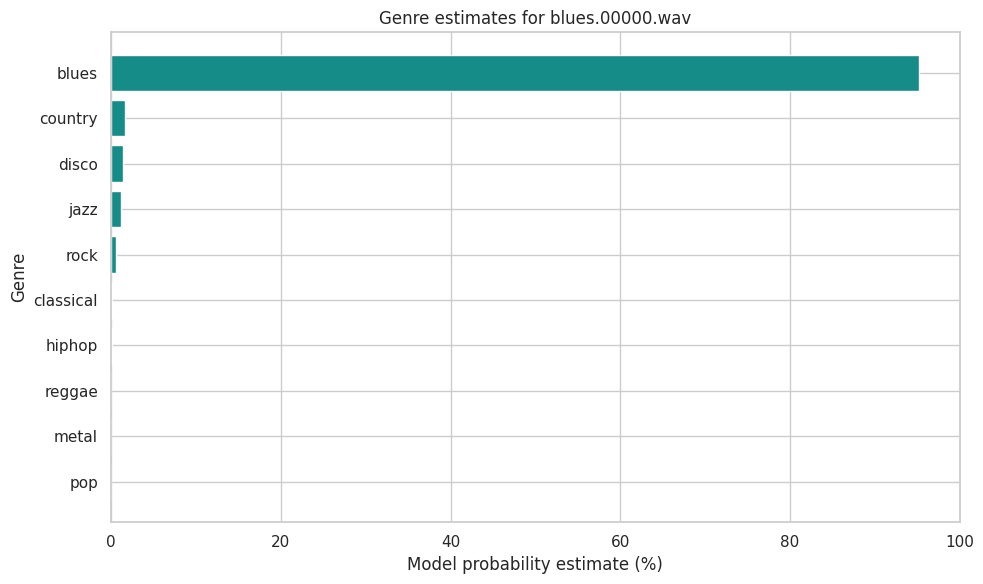


Saved results in: /content/outputs/part4


In [ ]:
# PART 4 — Upload an audio track and predict its genre
#This part accepts an audio file, extracts features, and uses the trained model to estimate its genre. The displayed probabilities are the model’s estimates for that file; they are not overall accuracy scores or guarantees
# Run after Part 2 in the same Colab runtime.
# If you get "No module named librosa", first run:
# !pip -q install librosa

from pathlib import Path, PurePosixPath
import zipfile

import joblib
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files

MODEL_DIR = Path("/content/outputs/part2")
MODEL_PATH = MODEL_DIR / "30_sec_best_model.joblib"
OUTPUT_DIR = Path("/content/outputs/part4")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_RATE = 22050
WINDOW_SECONDS = 30


def load_saved_model():
    """Use Part 2's model, or upload its results ZIP if needed."""
    global MODEL_PATH

    if MODEL_PATH.exists():
        return joblib.load(MODEL_PATH)

    print("Upload part2_results.zip, or the 30_sec_best_model.joblib file.")
    uploaded = files.upload()

    for filename in uploaded:
        file_path = Path("/content") / filename

        if filename.lower().endswith(".joblib"):
            MODEL_DIR.mkdir(parents=True, exist_ok=True)
            MODEL_PATH.write_bytes(file_path.read_bytes())
            return joblib.load(MODEL_PATH)

        if filename.lower().endswith(".zip"):
            with zipfile.ZipFile(file_path) as archive:
                model_members = [
                    name for name in archive.namelist()
                    if name.lower().endswith("30_sec_best_model.joblib")
                ]
                if model_members:
                    MODEL_DIR.mkdir(parents=True, exist_ok=True)
                    MODEL_PATH.write_bytes(archive.read(model_members[0]))
                    return joblib.load(MODEL_PATH)

    raise FileNotFoundError(
        "Could not find 30_sec_best_model.joblib. "
        "Upload the model file or the Part 2 results ZIP."
    )


def upload_wav():
    """Upload a WAV directly, or upload a ZIP containing one WAV."""
    print("Upload one .wav file or a .zip file containing a .wav file.")
    uploaded = files.upload()

    for filename in uploaded:
        file_path = Path("/content") / filename
        if filename.lower().endswith(".wav"):
            return file_path

    for filename in uploaded:
        file_path = Path("/content") / filename
        if filename.lower().endswith(".zip"):
            with zipfile.ZipFile(file_path) as archive:
                wav_members = [
                    name for name in archive.namelist()
                    if name.lower().endswith(".wav")
                ]
                if not wav_members:
                    continue

                member = wav_members[0]
                output_path = Path("/content") / PurePosixPath(member).name
                output_path.write_bytes(archive.read(member))
                return output_path

    raise ValueError("No WAV file was found in the upload.")


def extract_gtzan_features(audio, sample_rate):
    """Extract the 57 numeric GTZAN-style features expected by Part 2."""
    features = {}

    feature_arrays = {
        "chroma_stft": librosa.feature.chroma_stft(y=audio, sr=sample_rate),
        "rms": librosa.feature.rms(y=audio),
        "spectral_centroid": librosa.feature.spectral_centroid(
            y=audio, sr=sample_rate
        ),
        "spectral_bandwidth": librosa.feature.spectral_bandwidth(
            y=audio, sr=sample_rate
        ),
        "rolloff": librosa.feature.spectral_rolloff(
            y=audio, sr=sample_rate
        ),
        "zero_crossing_rate": librosa.feature.zero_crossing_rate(audio),
    }

    harmonic, percussive = librosa.effects.hpss(audio)
    feature_arrays["harmony"] = harmonic
    feature_arrays["perceptr"] = percussive

    for feature_name, values in feature_arrays.items():
        features[f"{feature_name}_mean"] = float(np.mean(values))
        features[f"{feature_name}_var"] = float(np.var(values))

    # Compatibility with librosa versions that expose tempo in different places.
    if hasattr(librosa.feature, "tempo"):
        tempo_values = librosa.feature.tempo(y=audio, sr=sample_rate)
    else:
        tempo_values = librosa.beat.tempo(y=audio, sr=sample_rate)

    features["tempo"] = float(np.asarray(tempo_values).reshape(-1)[0])

    mfccs = librosa.feature.mfcc(
        y=audio, sr=sample_rate, n_mfcc=20
    )
    for number, coefficient in enumerate(mfccs, start=1):
        features[f"mfcc{number}_mean"] = float(np.mean(coefficient))
        features[f"mfcc{number}_var"] = float(np.var(coefficient))

    return features


def make_audio_windows(audio_path):
    """Load mono audio and split it into windows for the 30-second model."""
    audio, sample_rate = librosa.load(
        audio_path, sr=SAMPLE_RATE, mono=True
    )

    if len(audio) < sample_rate * 5:
        raise ValueError(
            "The audio is shorter than 5 seconds. Please upload a longer clip."
        )

    window_size = sample_rate * WINDOW_SECONDS
    windows = []

    for start in range(0, len(audio), window_size):
        chunk = audio[start:start + window_size]

        # Ignore a very short leftover segment at the end of a long file.
        if len(chunk) < sample_rate * 5:
            continue

        # Pad a shorter final segment so it matches the model's 30-second input.
        if len(chunk) < window_size:
            chunk = np.pad(chunk, (0, window_size - len(chunk)))

        windows.append(chunk)

    if not windows:
        chunk = np.pad(audio, (0, max(0, window_size - len(audio))))
        windows = [chunk[:window_size]]

    return windows


# Load the trained model and upload the audio.
model_bundle = load_saved_model()
model = model_bundle["model"]
feature_names = list(model_bundle["features"])
genre_names = list(model_bundle["genres"])

audio_path = upload_wav()
audio_windows = make_audio_windows(audio_path)

# Extract features from every window, in the exact column order used by Part 2.
window_features = []
for window_number, audio_window in enumerate(audio_windows, start=1):
    print(f"Extracting features from audio window {window_number}...")
    extracted = extract_gtzan_features(audio_window, SAMPLE_RATE)
    window_features.append(extracted)

X_audio = pd.DataFrame(window_features).reindex(
    columns=feature_names
)

# Average probability estimates across windows for one song-level result.
window_probabilities = model.predict_proba(X_audio)
average_probabilities = window_probabilities.mean(axis=0)

probability_table = pd.DataFrame({
    "genre": model.classes_,
    "probability": average_probabilities,
}).sort_values("probability", ascending=False)

predicted_genre = probability_table.iloc[0]["genre"]
confidence_estimate = probability_table.iloc[0]["probability"]

print(f"\nAudio file: {audio_path.name}")
print(f"Predicted genre: {predicted_genre}")
print(f"Model probability estimate: {confidence_estimate:.1%}")
print(
    "This is the model's estimate, not a guarantee and not a score "
    "derived from the confusion matrix."
)

probability_table["probability_percent"] = (
    probability_table["probability"] * 100
)
display(probability_table[["genre", "probability_percent"]])

# Plot the model's probability estimate for each genre.
plt.figure(figsize=(10, 6))
plt.barh(
    probability_table["genre"][::-1],
    probability_table["probability_percent"][::-1],
    color="#168c88",
)
plt.xlabel("Model probability estimate (%)")
plt.ylabel("Genre")
plt.title(f"Genre estimates for {audio_path.name}")
plt.xlim(0, 100)
plt.tight_layout()

chart_path = OUTPUT_DIR / "genre_probability_estimates.png"
plt.savefig(chart_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Save the prediction and probability table.
probability_table.to_csv(
    OUTPUT_DIR / "genre_probability_estimates.csv",
    index=False,
)
print(f"\nSaved results in: {OUTPUT_DIR}")